[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/PHai237/VietSight/blob/main/notebooks/colab/VietSight_TEAM55_colab.ipynb)

VietSight TEAM 55 — vietsight_v1_e25: Runtime → T4 GPU → Run all. Kết quả: Google Drive `MyDrive/VietSight/vietsight_v1_e25/`.

# AIInAction RoboTaxi Data Centric Competition: notebook huấn luyện và nộp bài (Khóa 5)

**Bài toán:** phát hiện và tách mặt nạ (instance segmentation) cho cảnh giao thông, 11 lớp (bảng lớp in ở Bước 1).
**Điểm của đội = 100 × mask mAP@[.5:.95]** trên bộ test ẩn: mask càng khớp vật thể, điểm càng cao. Mô hình: **YOLO26n-seg** (Ultralytics `8.4.214`),
`imgsz = 640`. Dữ liệu huấn luyện do đội chuẩn bị: tự thu thập và gán nhãn, **được dùng thêm public dataset** (ghi lại thông tin để đưa vào báo cáo). Quy ước gán nhãn: xem website.

| Bước | Việc làm | Bạn sửa gì? |
|---|---|---|
| Tham số | Điền `TEAM_ID` (seed của đội), `DATASET_PATH`, số epoch | Chỉ ô tham số |
| 0 | Cài đặt đúng phiên bản, kiểm tra GPU | Không |
| 1 | Nạp dữ liệu (zip/thư mục trên Drive), kiểm tra nhãn, chia train/val theo seed, tạo `data.yaml` | Không (đổi tham số ở trên) |
| 2 | **Báo cáo kiểm tra dữ liệu** TRƯỚC khi huấn luyện: số đối tượng mỗi lớp, nhãn lỗi, mask quá nhỏ, ảnh trùng, rò rỉ train/val, ảnh minh họa | Đọc và sửa dữ liệu nếu cần |
| 3 | Huấn luyện, lưu `best.pt` | Có, tự do |
| 4 | **Xuất ONNX + kiểm tra như hệ thống chấm + đóng gói `submission.zip`** (BẮT BUỘC) | **Không** |
| 5 | Chạy thử như hệ thống chấm trên tập val: mask mAP, AP từng lớp, ảnh lỗi để phân tích | Đọc kết quả |
| 6 | Ghi bản kê tái lập `run_report.json`, tải `submission.zip` về | Không |

**Cách chạy:** Google Colab (Runtime > Change runtime type > **T4 GPU**), Kaggle (Settings > Accelerator > GPU, bật **Internet**) hoặc máy GPU tự thuê (Jupyter). Bật GPU, điền ô tham số, rồi chạy lần lượt từng ô từ trên xuống (Runtime > Run all cũng được).

**Cả đội dùng chung MỘT bộ dữ liệu**, mỗi thành viên có thể tự chạy notebook: hãy dùng **cùng `TEAM_ID`** (seed) và cùng dữ liệu để cùng cách chia train/val; các lần chạy khác nhau sẽ so sánh được với nhau.
**Giữ lại** notebook, zip dữ liệu và `run_report.json`: ban tổ chức có thể yêu cầu chạy lại để tái lập kết quả.

In [18]:
#@title Hằng số của cuộc thi (tự sinh từ hệ thống chấm, không chỉnh sửa) { display-mode: "form" }
# GENERATED by notebook/build_notebook.py from competition_config.yaml, detscore/data/*.json and detscore/*.py.
# Do not edit by hand: change the sources and rebuild, so the notebook cannot drift from the platform.
import json

NOTEBOOK_NAME = 'train_and_export'
NOTEBOOK_VERSION = '3.0.0+7880385f'
DETSCORE_VERSION = '0.2.0'
ULTRALYTICS_VERSION = '8.4.214'
PINNED_PACKAGES = {'ultralytics': '8.4.214', 'onnx': '1.23.2', 'onnxslim': '0.1.99', 'onnxruntime': '1.32.0'}
INFO_PACKAGES = {'torch': '2.15.0', 'torchvision': '0.29.2', 'numpy': '2.5.4'}
PYTHON_EXPECTED = '3.12.16'
INSTALL_SPECS = ['ultralytics==8.4.214', 'onnx==1.23.2', 'onnxslim==0.1.99', 'onnxruntime==1.32.0', 'pycocotools']
MODEL_ALLOWED = ['yolo26n-seg']
IMGSZ = 640
CLASSES = ['Car', 'Bus', 'Truck', 'Other vehicle', 'Motorcycle', 'Motorcyclist', 'Bicycle', 'Cyclist', 'Pedestrian', 'Sign', 'Traffic light']
CLASS_DISPLAY_VI = {'Car': 'Ô tô con', 'Bus': 'Xe buýt / xe khách', 'Truck': 'Xe tải', 'Other vehicle': 'Phương tiện khác', 'Motorcycle': 'Xe máy (không người)', 'Motorcyclist': 'Xe máy (có người)', 'Bicycle': 'Xe đạp (không người)', 'Cyclist': 'Xe đạp (có người)', 'Pedestrian': 'Người đi bộ', 'Sign': 'Biển báo', 'Traffic light': 'Đèn giao thông'}
MIN_GT_AREA_PX = 64.0
MIN_GT_PER_CLASS = 10
MAX_DET = 100
MAX_ZIP_MB = 42.0
EXPORT_CONTRACT = json.loads(r'''{
 "batch": 1,
 "dynamic": false,
 "export_call": "YOLO(best_pt).export(format='onnx', imgsz=640, opset=17, simplify=True, dynamic=False, half=False, batch=1)",
 "format": "onnx",
 "half": false,
 "imgsz": 640,
 "input": {
  "dtype": "float32",
  "name": "images",
  "shape": [
   1,
   3,
   640,
   640
  ]
 },
 "nms": null,
 "notes": "Class names and nc come from competition_config.yaml, never from this file.",
 "opset": 17,
 "outputs": [
  {
   "dtype": "float32",
   "meaning": "cx, cy, w, h (letterboxed 640 px) | nc sigmoid class scores | 32 mask coefficients",
   "name": "output0",
   "shape_template": [
    1,
    "4+nc+32",
    8400
   ]
  },
  {
   "dtype": "float32",
   "meaning": "mask prototypes, raw logits",
   "name": "output1",
   "shape": [
    1,
    32,
    160,
    160
   ]
  }
 ],
 "rationale": {
  "half": "False = fp32. half is deprecated in 8.4 (maps to quantize=16); fp16 models are rejected.",
  "layout": "Layout A = the DEFAULT Ultralytics export (nms unset). nms=False would select the end-to-end head ([1,300,38]) and nms=True puts NonMaxSuppression in the graph: both are rejected. The host owns conf/NMS/max_det/masks.",
  "nms": "null = do not pass nms to export (Ultralytics default). Never pass nms=False.",
  "opset": "Pinned to 17: without it ultralytics derives the opset from the torch version.",
  "simplify": "True (onnxslim): smaller and more stable graph across torch/onnx versions. Ultralytics default."
 },
 "schema_version": 2,
 "simplify": true,
 "structure_reference": {
  "contract_export_initializers": 153,
  "contract_export_nodes": 416,
  "contract_export_op_types": {
   "Add": 24,
   "Concat": 24,
   "Conv": 117,
   "ConvTranspose": 1,
   "Div": 1,
   "MatMul": 4,
   "MaxPool": 3,
   "Mul": 102,
   "Reshape": 15,
   "Resize": 4,
   "Sigmoid": 100,
   "Slice": 2,
   "Softmax": 2,
   "Split": 11,
   "Sub": 2,
   "Transpose": 4
  },
  "conv_signature_definition": "sha256(repr(sorted((role, dtype, shape) for every Conv/ConvTranspose weight and bias))) with tensors resolved through Identity nodes; no names, no values.",
  "status": "Built from random-initialised yolo26n-seg / yolo26s-seg exports (the architecture is weight independent); tools/make_reference.py. A trained checkpoint exported with the contract should have the same signature (unverified until a trained export is compared with tools/compare_reference.py)."
 },
 "task": "segment",
 "ultralytics_version": "8.4.214"
}''')
SELFCHECK_BUNDLE = json.loads(r'''{
 "config_yaml": "# Subset of competition_config.yaml (generated by notebook/build_notebook.py)\nschema_version: 2\ntask: segment\nclasses:\n- Car\n- Bus\n- Truck\n- Other vehicle\n- Motorcycle\n- Motorcyclist\n- Bicycle\n- Cyclist\n- Pedestrian\n- Sign\n- Traffic light\nclass_display_vi:\n  Car: \u00d4 t\u00f4 con\n  Bus: Xe bu\u00fdt / xe kh\u00e1ch\n  Truck: Xe t\u1ea3i\n  Other vehicle: Ph\u01b0\u01a1ng ti\u1ec7n kh\u00e1c\n  Motorcycle: Xe m\u00e1y (kh\u00f4ng ng\u01b0\u1eddi)\n  Motorcyclist: Xe m\u00e1y (c\u00f3 ng\u01b0\u1eddi)\n  Bicycle: Xe \u0111\u1ea1p (kh\u00f4ng ng\u01b0\u1eddi)\n  Cyclist: Xe \u0111\u1ea1p (c\u00f3 ng\u01b0\u1eddi)\n  Pedestrian: Ng\u01b0\u1eddi \u0111i b\u1ed9\n  Sign: Bi\u1ec3n b\u00e1o\n  Traffic light: \u0110\u00e8n giao th\u00f4ng\nimgsz: 640\nmodel:\n  family: yolo26\n  allowed:\n  - yolo26n-seg\npostprocess:\n  conf: 0.001\n  iou: 0.7\n  max_det: 100\n  pad_value: 114\n  mask_threshold: 0.5\n  multi_label: true\nscoring:\n  metric: mask_map_50_95\n  iou_thresholds:\n  - 0.5\n  - 0.55\n  - 0.6\n  - 0.65\n  - 0.7\n  - 0.75\n  - 0.8\n  - 0.85\n  - 0.9\n  - 0.95\n  min_gt_area_px: 64\n  ignore_small_predictions: true\n  report_by_source: false\nsubmission:\n  required_entry: model.onnx\n  max_zip_mb: 42\n  max_uncompressed_mb: 45\n  max_compression_ratio: 20\n  ratio_check_min_mb: 1\n  max_zip_entries_scanned: 100\n  max_central_directory_kb: 64\nvalidator:\n  max_nodes: 600\n  max_initializers: 400\n  max_total_params_m: 10.6\n  max_metadata_chars: 20000\nsplit:\n  min_gt_per_class_per_split: 10\ncontainer:\n  validate_timeout_s: 30\n  infer_timeout_s: 300\n  cpus: 2\n  memory_mb: 2048\n  pids_limit: 64\n  tmpfs_mb: 256\n  max_output_mb: 256\n",
 "files": {
  "__init__.py": "\"\"\"detscore: YOLO26-seg submission validator, sandbox ONNX runner (decode + RLE masks) and host mask-mAP scorer.\"\"\"\n\n__version__ = \"0.2.0\"\n",
  "cli_infer.py": "\"\"\"``infer`` entry point used inside the sandbox container (also usable from the command line).\n\n    python -m detscore.cli_infer --zip /sub/submission.zip --images /input/images --out /output/predictions.json [--cpus 2]\n\nReads ``model.onnx`` out of the zip (streamed to /tmp with a hard size cap, no path is taken from the archive), runs\nevery image of ``--images`` (sorted by file name), decodes the two raw tensors with OUR code (NMS + masks, see\n:mod:`detscore.decode`) and writes ``predictions.json`` (schema: ``docs/dev/DETSCORE_API.md``): per image up to\n``postprocess.max_det`` instances with class, score, box and the mask as COCO RLE at the original resolution.\nNo raw tensor is ever written. Only /tmp and the output path are written, so a read-only root filesystem is fine.\nNothing here ever sees a label file.\n\nstdout, last line: one JSON object ``{\"ok\": true, ...summary}`` or ``{\"ok\": false, \"code\", \"message\", \"detail\"}``.\nExit code: 0 ok, 2 :class:`~detscore.infer.InferenceError` (model problem), 3 internal error.\n\"\"\"\nfrom __future__ import annotations\n\nimport argparse\nimport json\nimport os\nimport resource\nimport shutil\nimport sys\nimport tempfile\nimport zipfile\nfrom pathlib import Path\n\nimport numpy as np\n\nfrom .decode import DecodeParams\nfrom .infer import InferenceError, InferenceResult, list_images, run_images\n\nPREDICTIONS_SCHEMA_VERSION = 1\nMODEL_ENTRY = \"model.onnx\"\nDEFAULT_MAX_MODEL_BYTES = 45 * 1024 * 1024  # = submission.max_uncompressed_mb of the default config\nDEFAULT_MAX_OUTPUT_BYTES = 256 * 1024 * 1024  # = container.max_output_mb of the default config\nDEFAULT_TMP = \"/tmp\"\n\n\ndef extract_model(zip_path: str | Path, dest_dir: str | Path, max_bytes: int = DEFAULT_MAX_MODEL_BYTES) -> Path:\n    \"\"\"Safely copy the single ``model.onnx`` entry of the zip to ``dest_dir/model.onnx``.\n\n    The destination file name is fixed (the archive entry name is only compared, never used as a path),\n    and the real decompressed size is enforced while streaming, whatever the zip header claims.\n    \"\"\"\n    try:\n        zf = zipfile.ZipFile(zip_path)\n    except (zipfile.BadZipFile, OSError) as exc:\n        raise InferenceError(\"BAD_ZIP\", \"Kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c file zip.\", str(exc)[:200]) from exc\n    with zf:\n        infos = [i for i in zf.infolist() if not i.is_dir()]\n        if len(infos) != 1 or infos[0].filename != MODEL_ENTRY:\n            raise InferenceError(\"BAD_ZIP_LAYOUT\", \"File zip ph\u1ea3i ch\u1ee9a duy nh\u1ea5t m\u1ed9t t\u1ec7p model.onnx.\")\n        info = infos[0]\n        if info.file_size > max_bytes:\n            raise InferenceError(\"MODEL_TOO_LARGE\", \"model.onnx v\u01b0\u1ee3t qu\u00e1 dung l\u01b0\u1ee3ng cho ph\u00e9p.\")\n        out_path = Path(dest_dir) / MODEL_ENTRY\n        written = 0\n        with zf.open(info) as src, open(out_path, \"wb\") as dst:\n            while True:\n                chunk = src.read(1 << 20)\n                if not chunk:\n                    break\n                written += len(chunk)\n                if written > max_bytes:\n                    raise InferenceError(\"MODEL_TOO_LARGE\", \"model.onnx v\u01b0\u1ee3t qu\u00e1 dung l\u01b0\u1ee3ng cho ph\u00e9p.\")\n                dst.write(chunk)\n    return out_path\n\n\ndef predictions_payload(result: InferenceResult, params: DecodeParams, classes: list[str] | None, meta: dict) -> dict:\n    \"\"\"The JSON-serialisable content of ``predictions.json``.\"\"\"\n    return {\n        \"schema_version\": PREDICTIONS_SCHEMA_VERSION,\n        \"format\": \"coco_rle\",\n        \"imgsz\": params.imgsz,\n        \"classes\": classes,\n        \"params\": {\"conf\": params.conf, \"iou\": params.iou, \"max_det\": params.max_det, \"mask_threshold\": params.mask_threshold,\n                   \"multi_label\": params.multi_label, \"pad_value\": params.pad_value},\n        \"images\": [\n            {\n                \"file\": im.name, \"height\": im.height, \"width\": im.width,\n                \"latency_ms\": round(im.latency_ms, 3), \"decode_ms\": round(im.decode_ms, 3),\n                \"instances\": [{\"c\": it.cls, \"s\": it.score, \"box\": list(it.box), \"rle\": it.rle} for it in im.instances],\n            }\n            for im in result.images\n        ],\n        \"meta\": meta,\n    }\n\n\ndef write_predictions(result: InferenceResult, out_json: str | Path, params: DecodeParams, classes: list[str] | None = None,\n                      extra_meta: dict | None = None) -> Path:\n    \"\"\"Write the predictions atomically (temp file in the same directory, then rename).\"\"\"\n    import onnxruntime as ort\n\n    out_json = Path(out_json)\n    out_json.parent.mkdir(parents=True, exist_ok=True)\n    lat, dec = result.latency_ms, result.decode_ms\n    meta = {\n        \"n_images\": result.n, \"n_instances\": result.n_instances, \"threads\": result.threads,\n        \"model_load_s\": round(result.model_load_s, 3), \"total_s\": round(result.total_s, 3),\n        \"latency_ms_p50\": float(np.median(lat)) if result.n else 0.0,\n        \"decode_ms_p50\": float(np.median(dec)) if result.n else 0.0,\n        \"output_bytes\": result.output_bytes, \"onnxruntime\": ort.__version__,\n        **(extra_meta or {}),\n    }\n    payload = predictions_payload(result, params, classes, meta)\n    tmp = out_json.with_name(out_json.name + \".tmp\")\n    with open(tmp, \"w\", encoding=\"utf-8\") as fh:\n        json.dump(payload, fh, separators=(\",\", \":\"), ensure_ascii=False)\n    os.replace(tmp, out_json)\n    return out_json\n\n\ndef _try_load_config():\n    \"\"\"The competition config if it can be found, else None (defaults apply). Never raises.\"\"\"\n    try:\n        from .config import load_config\n\n        return load_config()\n    except Exception:  # noqa: BLE001 - inference must not die because the config is unreachable\n        return None\n\n\ndef main(\n    zip_path: str | Path,\n    images_dir: str | Path,\n    out_json: str | Path,\n    cpus: int | float | None = None,\n    max_model_bytes: int | None = None,\n    tmp_root: str | Path | None = None,\n    config=None,\n) -> dict:\n    \"\"\"Run inference and write ``out_json``. Returns a small summary dict. Raises InferenceError.\n\n    ``config`` is a ``detscore.config.Config`` or None; when None the competition config is looked up\n    (``DETSCORE_CONFIG`` or the project file). It supplies the class count, ``imgsz``, the post-processing\n    parameters and the limits. Without any config the call fails: the decoder needs ``nc``.\n    \"\"\"\n    images = list_images(images_dir)\n    if not images:\n        raise InferenceError(\"NO_IMAGES\", \"Kh\u00f4ng t\u00ecm th\u1ea5y \u1ea3nh ki\u1ec3m th\u1eed \u0111\u1ec3 suy lu\u1eadn.\")\n    if config is None:\n        config = _try_load_config()\n    if config is None:\n        raise InferenceError(\"NO_CONFIG\", \"Kh\u00f4ng t\u00ecm th\u1ea5y competition_config.yaml (\u0111\u1eb7t bi\u1ebfn DETSCORE_CONFIG).\")\n    params = DecodeParams.from_config(config)\n    if max_model_bytes is None:\n        max_model_bytes = int(config.max_uncompressed_bytes)\n    if cpus is None:\n        cpus = os.environ.get(\"DETSCORE_CPUS\") or os.environ.get(\"CPUS\") or config.container_cpus\n    threads = max(1, int(round(float(cpus)))) if cpus else 1\n\n    root = str(tmp_root or (DEFAULT_TMP if os.path.isdir(DEFAULT_TMP) else tempfile.gettempdir()))\n    work = tempfile.mkdtemp(prefix=\"detscore_\", dir=root)\n    try:\n        model = extract_model(zip_path, work, max_model_bytes)\n        result = run_images(model, images, params, threads=threads, max_output_bytes=int(config.container_max_output_bytes))\n    finally:\n        shutil.rmtree(work, ignore_errors=True)\n    rss_mb = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss / 1024.0  # Linux: KiB\n    write_predictions(result, out_json, params, list(config.classes), {\"peak_rss_mb\": round(rss_mb, 1)})\n    return {\n        \"n_images\": result.n,\n        \"n_instances\": result.n_instances,\n        \"threads\": threads,\n        \"latency_ms_p50\": float(np.median(result.latency_ms)),\n        \"latency_ms_max\": float(result.latency_ms.max()),\n        \"decode_ms_p50\": float(np.median(result.decode_ms)),\n        \"decode_ms_max\": float(result.decode_ms.max()),\n        \"model_load_s\": round(result.model_load_s, 3),\n        \"total_s\": round(result.total_s, 3),\n        \"output_bytes\": result.output_bytes,\n        \"peak_rss_mb\": round(rss_mb, 1),\n        \"predictions\": str(out_json),\n    }\n\n\ndef cli(argv: list[str] | None = None) -> int:\n    ap = argparse.ArgumentParser(prog=\"python -m detscore.cli_infer\", description=__doc__.splitlines()[0])\n    ap.add_argument(\"--zip\", dest=\"zip_path\", default=\"/sub/submission.zip\")\n    ap.add_argument(\"--images\", dest=\"images_dir\", default=\"/input/images\")\n    ap.add_argument(\"--out\", dest=\"out_json\", default=\"/output/predictions.json\")\n    ap.add_argument(\"--cpus\", type=float, default=None)\n    ap.add_argument(\"--config\", default=None, help=\"competition_config.yaml (default: DETSCORE_CONFIG or project file)\")\n    args = ap.parse_args(argv)\n    try:\n        config = None\n        if args.config:\n            from .config import load_config\n\n            config = load_config(args.config)\n        summary = main(args.zip_path, args.images_dir, args.out_json, cpus=args.cpus, config=config)\n    except InferenceError as exc:\n        print(json.dumps({\"ok\": False, \"code\": exc.code, \"message\": exc.message_vi, \"detail\": exc.detail}, ensure_ascii=False))\n        return 2\n    except MemoryError:\n        print(json.dumps({\"ok\": False, \"code\": \"INFER_INTERNAL_ERROR\", \"message\": \"H\u1ebft b\u1ed9 nh\u1edb khi suy lu\u1eadn.\", \"detail\": \"MemoryError\"}, ensure_ascii=False))\n        return 3\n    except Exception as exc:  # noqa: BLE001 - e.g. unreadable --config; report as JSON, never a traceback\n        print(json.dumps({\"ok\": False, \"code\": \"INFER_INTERNAL_ERROR\", \"message\": \"L\u1ed7i n\u1ed9i b\u1ed9 khi suy lu\u1eadn.\", \"detail\": f\"{type(exc).__name__}: {str(exc)[:300]}\"}, ensure_ascii=False))\n        return 3\n    print(json.dumps({\"ok\": True, **summary}))\n    return 0\n\n\nif __name__ == \"__main__\":\n    sys.exit(cli())\n",
  "config.py": "\"\"\"Competition configuration loader.\n\n``competition_config.yaml`` is the single source of truth for classes, thresholds and policies.\nResolution order for the file: explicit ``path`` argument, environment variable ``DETSCORE_CONFIG``,\n``<project root>/competition_config.yaml`` (source checkout), ``./competition_config.yaml``.\n\n``Config`` exposes the values other modules need as plain attributes (``classes``, ``nc``, ``imgsz``,\n``conf``, ``iou``, ``max_det``, ``num_anchors``, ``max_zip_bytes``, ``max_uncompressed_bytes``,\n``penalty_points`` ...). The raw parsed mapping is kept in ``Config.raw`` for sections this module does\nnot interpret (for example ``competitions``).\n\nSchema version 2 (instance segmentation, YOLO26-seg). Sizes written ``*_mb`` are MiB (1024 * 1024 bytes).\n\"\"\"\nfrom __future__ import annotations\n\nimport os\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Any, Mapping\n\nimport yaml\n\nENV_VAR = \"DETSCORE_CONFIG\"\nCONFIG_FILENAME = \"competition_config.yaml\"\nSTRIDES = (8, 16, 32)  # YOLO26 detection strides: anchors = sum((imgsz / s) ** 2)\nNUM_MASKS = 32  # mask coefficients per anchor / prototype channels of YOLO26n-seg and YOLO26s-seg\nPROTO_STRIDE = 4  # prototypes are imgsz / 4 pixels wide\nSCHEMA_VERSION = 2\nDEFAULT_IOU_THRESHOLDS = (0.50, 0.55, 0.60, 0.65, 0.70, 0.75, 0.80, 0.85, 0.90, 0.95)\n\n_MB = 1024 * 1024\n\n\nclass ConfigError(ValueError):\n    \"\"\"The competition configuration is missing or inconsistent.\"\"\"\n\n\ndef anchors_for(imgsz: int) -> int:\n    \"\"\"Number of anchor points of the YOLO26 head for a square input (8400 for 640).\"\"\"\n    if imgsz % max(STRIDES):\n        raise ConfigError(f\"imgsz must be a multiple of {max(STRIDES)}, got {imgsz}\")\n    return sum((imgsz // s) ** 2 for s in STRIDES)\n\n\ndef _section(raw: Mapping[str, Any], key: str) -> Mapping[str, Any]:\n    value = raw.get(key, {})\n    if not isinstance(value, Mapping):\n        raise ConfigError(f\"'{key}' must be a mapping\")\n    return value\n\n\ndef _num(section: Mapping[str, Any], key: str, default: float | None = None, *, minimum: float = 0.0) -> float:\n    if key not in section and default is None:\n        raise ConfigError(f\"missing required key '{key}'\")\n    value = section.get(key, default)\n    if isinstance(value, bool) or not isinstance(value, (int, float)):\n        raise ConfigError(f\"'{key}' must be a number, got {value!r}\")\n    if value < minimum:\n        raise ConfigError(f\"'{key}' must be >= {minimum}, got {value!r}\")\n    return value\n\n\n@dataclass(frozen=True)\nclass Config:\n    classes: tuple[str, ...]\n    class_display_vi: Mapping[str, str]\n    imgsz: int\n    # post-processing\n    conf: float\n    iou: float\n    max_det: int\n    pad_value: int\n    # submission zip\n    required_entry: str\n    max_zip_bytes: int\n    max_uncompressed_bytes: int\n    max_compression_ratio: float\n    ratio_check_min_bytes: int\n    max_zip_entries_scanned: int\n    max_central_directory_bytes: int\n    # onnx validator guards\n    max_nodes: int\n    max_initializers: int\n    max_total_params: int\n    max_metadata_chars: int\n    # scoring data\n    split_public_images: int\n    split_private_images: int\n    min_gt_per_class_per_split: int\n    # penalties\n    penalty_points: float\n    original_extra_slots: int\n    copier_extra_slots: int\n    # accounts\n    username_pattern: str\n    # container\n    validate_timeout_s: int\n    infer_timeout_s: int\n    container_cpus: float\n    container_memory_mb: int\n    # untouched sections\n    competitions: tuple[Mapping[str, Any], ...] = ()\n    raw: Mapping[str, Any] = field(default_factory=dict, compare=False, repr=False)\n    source: str = field(default=\"<dict>\", compare=False)\n    # container hardening (defaults keep Config(...) built by older callers valid)\n    container_pids_limit: int = 64\n    container_tmpfs_mb: int = 256\n    # schema version 2 additions (all have defaults so Config(...) built by older callers stays valid)\n    mask_threshold: float = 0.5\n    multi_label: bool = True\n    iou_thresholds: tuple[float, ...] = DEFAULT_IOU_THRESHOLDS\n    min_gt_area_px: float = 64.0\n    ignore_small_predictions: bool = True\n    report_by_source: bool = True\n    sources: tuple[str, ...] = (\"all\",)\n    model_family: str = \"yolo26\"\n    model_allowed: tuple[str, ...] = (\"yolo26n-seg\",)\n    container_max_output_bytes: int = 256 * _MB\n\n    @property\n    def nc(self) -> int:\n        return len(self.classes)\n\n    @property\n    def num_anchors(self) -> int:\n        return anchors_for(self.imgsz)\n\n    @property\n    def max_zip_mb(self) -> float:\n        return self.max_zip_bytes / _MB\n\n    @property\n    def max_uncompressed_mb(self) -> float:\n        return self.max_uncompressed_bytes / _MB\n\n    @property\n    def expected_input_shape(self) -> tuple[int, int, int, int]:\n        return (1, 3, self.imgsz, self.imgsz)\n\n    @property\n    def num_masks(self) -> int:\n        return NUM_MASKS\n\n    @property\n    def proto_size(self) -> int:\n        return self.imgsz // PROTO_STRIDE\n\n    @property\n    def expected_output0_shape(self) -> tuple[int, int, int]:\n        \"\"\"``[1, 4 + nc + 32, anchors]``: cx, cy, w, h | nc sigmoid class scores | 32 mask coefficients.\"\"\"\n        return (1, 4 + self.nc + NUM_MASKS, self.num_anchors)\n\n    @property\n    def expected_output1_shape(self) -> tuple[int, int, int, int]:\n        \"\"\"``[1, 32, imgsz/4, imgsz/4]``: raw mask prototype logits.\"\"\"\n        return (1, NUM_MASKS, self.proto_size, self.proto_size)\n\n    @property\n    def expected_output_shape(self) -> tuple[int, int, int]:\n        \"\"\"Kept for old callers: the shape of ``output0``.\"\"\"\n        return self.expected_output0_shape\n\n    @property\n    def expected_output_shapes(self) -> tuple[tuple[int, ...], tuple[int, ...]]:\n        return (self.expected_output0_shape, self.expected_output1_shape)\n\n    @classmethod\n    def from_dict(cls, raw: Mapping[str, Any], source: str = \"<dict>\") -> \"Config\":\n        if not isinstance(raw, Mapping):\n            raise ConfigError(\"the configuration root must be a mapping\")\n        classes = raw.get(\"classes\")\n        if not isinstance(classes, (list, tuple)) or not classes:\n            raise ConfigError(\"'classes' must be a non-empty list\")\n        if not all(isinstance(c, str) and c for c in classes):\n            raise ConfigError(\"every class name must be a non-empty string\")\n        if len(set(classes)) != len(classes):\n            raise ConfigError(\"class names must be unique\")\n        display = dict(_section(raw, \"class_display_vi\"))\n        unknown = set(display) - set(classes)\n        if unknown:\n            raise ConfigError(f\"class_display_vi names unknown classes: {sorted(unknown)}\")\n        display = {c: str(display.get(c, c)) for c in classes}\n\n        imgsz = int(_num(raw, \"imgsz\", 640, minimum=32))\n        anchors_for(imgsz)  # validates the multiple-of-32 constraint\n\n        post = _section(raw, \"postprocess\")\n        sub = _section(raw, \"submission\")\n        val = _section(raw, \"validator\")\n        split = _section(raw, \"split\")\n        pen = _section(raw, \"penalty\")\n        auth = _section(raw, \"auth\")\n        cont = _section(raw, \"container\")\n        scoring = _section(raw, \"scoring\")\n        model = _section(raw, \"model\")\n        if raw.get(\"schema_version\", SCHEMA_VERSION) != SCHEMA_VERSION:\n            raise ConfigError(f\"schema_version must be {SCHEMA_VERSION} (instance segmentation), got {raw.get('schema_version')!r}\")\n\n        conf = float(_num(post, \"conf\", 0.001))\n        iou = float(_num(post, \"iou\", 0.7))\n        if not (0 <= conf <= 1 and 0 < iou <= 1):\n            raise ConfigError(\"postprocess.conf must be in [0,1] and postprocess.iou in (0,1]\")\n\n        mask_thr = float(_num(post, \"mask_threshold\", 0.5))\n        if not 0 < mask_thr < 1:\n            raise ConfigError(\"postprocess.mask_threshold must be in (0, 1)\")\n        thr = scoring.get(\"iou_thresholds\", list(DEFAULT_IOU_THRESHOLDS))\n        if (not isinstance(thr, (list, tuple)) or not thr\n                or not all(isinstance(t, (int, float)) and not isinstance(t, bool) and 0 < t < 1 for t in thr)\n                or list(thr) != sorted(set(thr))):\n            raise ConfigError(\"scoring.iou_thresholds must be a strictly increasing list of numbers in (0, 1)\")\n        sources = split.get(\"sources\", [\"all\"])\n        if not isinstance(sources, (list, tuple)) or not sources or not all(isinstance(x, str) and x for x in sources):\n            raise ConfigError(\"split.sources must be a non-empty list of names\")\n        allowed = model.get(\"allowed\", [\"yolo26n-seg\"])\n        if not isinstance(allowed, (list, tuple)) or not allowed or not all(isinstance(x, str) and x for x in allowed):\n            raise ConfigError(\"model.allowed must be a non-empty list of architecture names\")\n\n        comps = raw.get(\"competitions\", [])\n        if not isinstance(comps, (list, tuple)):\n            raise ConfigError(\"'competitions' must be a list\")\n        codes = [c.get(\"code\") for c in comps if isinstance(c, Mapping)]\n        if len(codes) != len(comps) or len(set(codes)) != len(codes) or not all(isinstance(c, str) and c for c in codes):\n            raise ConfigError(\"every competition needs a unique string 'code'\")\n\n        return cls(\n            classes=tuple(classes),\n            class_display_vi=display,\n            imgsz=imgsz,\n            conf=conf,\n            iou=iou,\n            max_det=int(_num(post, \"max_det\", 100, minimum=1)),\n            pad_value=int(_num(post, \"pad_value\", 114)),\n            required_entry=str(sub.get(\"required_entry\", \"model.onnx\")),\n            max_zip_bytes=int(_num(sub, \"max_zip_mb\", 42, minimum=0.001) * _MB),\n            max_uncompressed_bytes=int(_num(sub, \"max_uncompressed_mb\", 45, minimum=0.001) * _MB),\n            max_compression_ratio=float(_num(sub, \"max_compression_ratio\", 20, minimum=1)),\n            ratio_check_min_bytes=int(_num(sub, \"ratio_check_min_mb\", 1) * _MB),\n            max_zip_entries_scanned=int(_num(sub, \"max_zip_entries_scanned\", 100, minimum=1)),\n            max_central_directory_bytes=int(_num(sub, \"max_central_directory_kb\", 64, minimum=1) * 1024),\n            max_nodes=int(_num(val, \"max_nodes\", 600, minimum=1)),\n            max_initializers=int(_num(val, \"max_initializers\", 200, minimum=1)),\n            max_total_params=int(_num(val, \"max_total_params_m\", 10.6, minimum=0.001) * 1_000_000),\n            max_metadata_chars=int(_num(val, \"max_metadata_chars\", 20000, minimum=1)),\n            split_public_images=int(_num(split, \"public_images\", 1, minimum=1)),\n            split_private_images=int(_num(split, \"private_images\", 1, minimum=1)),\n            min_gt_per_class_per_split=int(_num(split, \"min_gt_per_class_per_split\", 10)),\n            penalty_points=float(_num(pen, \"points\", 10)),\n            original_extra_slots=int(_num(pen, \"original_extra_slots\", 1)),\n            copier_extra_slots=int(_num(pen, \"copier_extra_slots\", 1)),\n            username_pattern=str(auth.get(\"username_pattern\", r\"^[a-z0-9_.-]{3,64}$\")),\n            validate_timeout_s=int(_num(cont, \"validate_timeout_s\", 30, minimum=1)),\n            infer_timeout_s=int(_num(cont, \"infer_timeout_s\", 300, minimum=1)),\n            container_cpus=float(_num(cont, \"cpus\", 2, minimum=0.1)),\n            container_memory_mb=int(_num(cont, \"memory_mb\", 2048, minimum=64)),\n            container_pids_limit=int(_num(cont, \"pids_limit\", 64, minimum=8)),\n            container_tmpfs_mb=int(_num(cont, \"tmpfs_mb\", 256, minimum=16)),\n            mask_threshold=mask_thr,\n            multi_label=bool(post.get(\"multi_label\", True)),\n            iou_thresholds=tuple(float(t) for t in thr),\n            min_gt_area_px=float(_num(scoring, \"min_gt_area_px\", 64)),\n            ignore_small_predictions=bool(scoring.get(\"ignore_small_predictions\", True)),\n            report_by_source=bool(scoring.get(\"report_by_source\", True)),\n            sources=tuple(sources),\n            model_family=str(model.get(\"family\", \"yolo26\")),\n            model_allowed=tuple(allowed),\n            container_max_output_bytes=int(_num(cont, \"max_output_mb\", 256, minimum=1) * _MB),\n            competitions=tuple(dict(c) for c in comps),\n            raw=dict(raw),\n            source=source,\n        )\n\n\ndef default_search_paths() -> list[Path]:\n    paths: list[Path] = []\n    env = os.environ.get(ENV_VAR)\n    if env:\n        paths.append(Path(env))\n    # <root>/detscore/detscore/config.py -> <root>\n    paths.append(Path(__file__).resolve().parents[2] / CONFIG_FILENAME)\n    paths.append(Path.cwd() / CONFIG_FILENAME)\n    return paths\n\n\ndef load_config(path: str | os.PathLike | None = None) -> Config:\n    \"\"\"Load and validate the configuration (see the module docstring for the lookup order).\"\"\"\n    if path is not None:\n        candidates = [Path(path)]\n    else:\n        candidates = default_search_paths()\n    for candidate in candidates:\n        if candidate.is_file():\n            try:\n                raw = yaml.safe_load(candidate.read_text(encoding=\"utf-8\"))\n            except yaml.YAMLError as exc:\n                raise ConfigError(f\"{candidate}: invalid YAML: {exc}\") from exc\n            try:\n                return Config.from_dict(raw, source=str(candidate))\n            except ConfigError as exc:\n                raise ConfigError(f\"{candidate}: {exc}\") from exc\n    tried = \", \".join(str(c) for c in candidates)\n    raise ConfigError(f\"{CONFIG_FILENAME} not found (looked in: {tried}); set {ENV_VAR}\")\n",
  "data/reference_signature.json": "{\n  \"schema_version\": 2,\n  \"nc\": 11,\n  \"imgsz\": 640,\n  \"num_masks\": 32,\n  \"allowed_op_types\": [\n    \"Add\",\n    \"Concat\",\n    \"Constant\",\n    \"Conv\",\n    \"ConvTranspose\",\n    \"Div\",\n    \"Gather\",\n    \"Identity\",\n    \"MatMul\",\n    \"MaxPool\",\n    \"Mul\",\n    \"Reshape\",\n    \"Resize\",\n    \"Shape\",\n    \"Sigmoid\",\n    \"Slice\",\n    \"Softmax\",\n    \"Split\",\n    \"Sub\",\n    \"Transpose\"\n  ],\n  \"architectures\": {\n    \"yolo26n-seg\": {\n      \"signature_sha256\": \"855b7e666adf3cee06077d5da3b9e925dba9e019784b151c70294badba43599b\",\n      \"conv_nodes\": 118,\n      \"conv_params\": 2681904,\n      \"conv_tensors\": [\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            4,\n            16,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            8,\n            16,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            11,\n            64,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            3,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            8,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            16,\n            3,\n            3\n          ],\n          \"count\": 7\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            32,\n            1,\n            1\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            32,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            256,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            16,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            32,\n            1,\n            1\n          ],\n          \"count\": 5\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            32,\n            3,\n            3\n          ],\n          \"count\": 15\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            64,\n            1,\n            1\n          ],\n          \"count\": 7\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            256,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            1,\n            3,\n            3\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            48,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            1,\n            1\n          ],\n          \"count\": 8\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            3,\n            3\n          ],\n          \"count\": 9\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            96,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            128,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            256,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            1,\n            3,\n            3\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            96,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            192,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            256,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            384,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            1,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            128,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            256,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            384,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            512,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            4\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            8\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            11\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16\n          ],\n          \"count\": 15\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32\n          ],\n          \"count\": 32\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64\n          ],\n          \"count\": 31\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128\n          ],\n          \"count\": 19\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256\n          ],\n          \"count\": 13\n        },\n        {\n          \"role\": 2,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            2,\n            2\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 3,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64\n          ],\n          \"count\": 1\n        }\n      ],\n      \"reference_op_counts\": {\n        \"Add\": 24,\n        \"Concat\": 24,\n        \"Conv\": 117,\n        \"ConvTranspose\": 1,\n        \"Div\": 1,\n        \"MatMul\": 4,\n        \"MaxPool\": 3,\n        \"Mul\": 102,\n        \"Reshape\": 15,\n        \"Resize\": 4,\n        \"Sigmoid\": 100,\n        \"Slice\": 2,\n        \"Softmax\": 2,\n        \"Split\": 11,\n        \"Sub\": 2,\n        \"Transpose\": 4\n      }\n    },\n    \"yolo26s-seg\": {\n      \"signature_sha256\": \"dd50a7e0f396e21c749ffd94ea412974e062a6a53318ddb62109ba8b45bea317\",\n      \"conv_nodes\": 118,\n      \"conv_params\": 10351712,\n      \"conv_tensors\": [\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            4,\n            32,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            11,\n            128,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            32,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            3,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            16,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            32,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            32,\n            3,\n            3\n          ],\n          \"count\": 10\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            64,\n            1,\n            1\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            128,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            128,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            256,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            512,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            32,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            1,\n            1\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            3,\n            3\n          ],\n          \"count\": 12\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            128,\n            1,\n            1\n          ],\n          \"count\": 6\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            1,\n            3,\n            3\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            96,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            1,\n            1\n          ],\n          \"count\": 8\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            3,\n            3\n          ],\n          \"count\": 9\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            192,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            256,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            256,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            512,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            1,\n            3,\n            3\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            192,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            256,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            256,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            384,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            512,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            768,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512,\n            1,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512,\n            256,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512,\n            256,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512,\n            512,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512,\n            768,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512,\n            1024,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            4\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            11\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32\n          ],\n          \"count\": 25\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64\n          ],\n          \"count\": 22\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128\n          ],\n          \"count\": 31\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256\n          ],\n          \"count\": 19\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            512\n          ],\n          \"count\": 13\n        },\n        {\n          \"role\": 2,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            2,\n            2\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 3,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128\n          ],\n          \"count\": 1\n        }\n      ],\n      \"reference_op_counts\": {\n        \"Add\": 24,\n        \"Concat\": 24,\n        \"Conv\": 117,\n        \"ConvTranspose\": 1,\n        \"Div\": 1,\n        \"MatMul\": 4,\n        \"MaxPool\": 3,\n        \"Mul\": 102,\n        \"Reshape\": 15,\n        \"Resize\": 4,\n        \"Sigmoid\": 100,\n        \"Slice\": 2,\n        \"Softmax\": 2,\n        \"Split\": 11,\n        \"Sub\": 2,\n        \"Transpose\": 4\n      }\n    },\n    \"yolo26n-seg@pretrained-head\": {\n      \"signature_sha256\": \"d847611dbe78fe63f6bfbd51c858b8f78453f71c062160ea0f7c21552033e2d0\",\n      \"conv_nodes\": 118,\n      \"conv_params\": 2696944,\n      \"conv_tensors\": [\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            4,\n            16,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            8,\n            16,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            11,\n            80,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            3,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            8,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            16,\n            3,\n            3\n          ],\n          \"count\": 7\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            32,\n            1,\n            1\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            32,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16,\n            256,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            16,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            32,\n            1,\n            1\n          ],\n          \"count\": 5\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            32,\n            3,\n            3\n          ],\n          \"count\": 15\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            64,\n            1,\n            1\n          ],\n          \"count\": 7\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32,\n            256,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            1,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            48,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            3,\n            3\n          ],\n          \"count\": 9\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            96,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            128,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            256,\n            1,\n            1\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            80,\n            1,\n            3,\n            3\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            80,\n            64,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            80,\n            80,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            80,\n            128,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            80,\n            256,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            1,\n            3,\n            3\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            64,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            96,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            128,\n            3,\n            3\n          ],\n          \"count\": 2\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            192,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            256,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128,\n            384,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            1,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            128,\n            1,\n            1\n          ],\n          \"count\": 4\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            128,\n            3,\n            3\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            256,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            384,\n            1,\n            1\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 0,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256,\n            512,\n            1,\n            1\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            4\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            8\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            11\n          ],\n          \"count\": 3\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            16\n          ],\n          \"count\": 15\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            32\n          ],\n          \"count\": 32\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64\n          ],\n          \"count\": 22\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            80\n          ],\n          \"count\": 9\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            128\n          ],\n          \"count\": 19\n        },\n        {\n          \"role\": 1,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            256\n          ],\n          \"count\": 13\n        },\n        {\n          \"role\": 2,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64,\n            64,\n            2,\n            2\n          ],\n          \"count\": 1\n        },\n        {\n          \"role\": 3,\n          \"dtype\": \"float32\",\n          \"shape\": [\n            64\n          ],\n          \"count\": 1\n        }\n      ],\n      \"reference_op_counts\": {\n        \"Add\": 24,\n        \"Concat\": 24,\n        \"Conv\": 117,\n        \"ConvTranspose\": 1,\n        \"Div\": 1,\n        \"MatMul\": 4,\n        \"MaxPool\": 3,\n        \"Mul\": 102,\n        \"Reshape\": 15,\n        \"Resize\": 4,\n        \"Sigmoid\": 100,\n        \"Slice\": 2,\n        \"Softmax\": 2,\n        \"Split\": 11,\n        \"Sub\": 2,\n        \"Transpose\": 4\n      }\n    }\n  },\n  \"provenance\": {\n    \"generated_at\": \"2026-11-24T17:10:38+00:00\",\n    \"note\": \"\",\n    \"source\": \"random_init_ultralytics_export\",\n    \"seed\": 0,\n    \"toolchain\": {\n      \"ultralytics\": \"8.4.214\",\n      \"torch\": \"2.15.0\",\n      \"torchvision\": \"0.29.2\",\n      \"onnx\": \"1.23.2\",\n      \"onnxslim\": \"0.1.99\",\n      \"onnxruntime\": \"1.32.0\",\n      \"numpy\": \"2.5.4\",\n      \"python\": \"3.12.16\",\n      \"platform\": \"Linux x86_64\",\n      \"note\": \"Versions the fixtures were generated with. The student notebook pins ultralytics to this version; torch/onnx/onnxslim on Colab may differ, which is why the structure check compares a tolerant weight signature rather than every constant/op.\"\n    },\n    \"status\": \"built from random-initialised exports (the architecture is weight independent); a trained export must still be compared once with tools/compare_reference.py\",\n    \"variants_merged\": 4,\n    \"added\": {\n      \"yolo26n-seg@pretrained-head\": {\n        \"sha256\": \"b2ac8ceb8579e7879f227e553b6721858890855331dcbd4e1ea0874989b0410d\"\n      }\n    }\n  }\n}\n",
  "data/reserved_fingerprints.json": "{\n  \"schema_version\": 1,\n  \"generated_at\": \"2026-11-25T00:00:00+00:00\",\n  \"note\": \"EMPTY on purpose until the official pretrained exports exist: they need yolo26n-seg.pt / yolo26s-seg.pt, which this repository never downloads. Run detscore/tools/make_reserved.py --pretrained yolo26n-seg.pt yolo26s-seg.pt on a machine that has them (OPEN ITEM).\",\n  \"entries\": []\n}\n",
  "decode.py": "\"\"\"Decoding of the raw YOLO26-seg output (layout A, the default Ultralytics export) into instances.\n\nRuns INSIDE the sandbox container, with our code, on the two tensors the untrusted model produced:\n\n* ``output0``  ``[1, 4 + nc + 32, 8400]``: rows 0..3 = ``cx, cy, w, h`` in letterboxed 640 x 640 pixels, rows\n  4..4+nc = class scores (already sigmoid), the last 32 rows = mask coefficients (raw);\n* ``output1``  ``[1, 32, 160, 160]``: mask prototypes, raw logits (no sigmoid).\n\nPipeline (the same operations as Ultralytics ``non_max_suppression(multi_label=True)`` -> ``scale_boxes`` ->\n``process_mask_native`` that ``yolo val`` / ``predict(retina_masks=True)`` use; parity is measured by\n``scripts/parity_check.py``):\n\n1. candidates = every (anchor, class) pair with score > ``conf`` (multi-label, like ``yolo val``), the best\n   ``MAX_NMS_CANDIDATES`` by score;\n2. class-aware greedy NMS (IoU ``iou``, strict ``>`` suppresses), the first ``max_det`` kept (score descending);\n3. boxes mapped back to the original image (undo padding and scale, clip);\n4. masks: ``coef @ protos`` -> bilinear upsample 160 -> 160 * f (f = 1, 2 or 4 as in Ultralytics) -> drop the\n   letterbox padding -> bilinear resize to the original ``(H, W)`` -> ``logit > logit(mask_threshold)`` -> zero\n   outside the box. Only the pixels INSIDE the box are ever computed, so a traffic light costs a few hundred\n   pixels, not a 1080p frame;\n5. every mask becomes a COCO RLE string at ORIGINAL resolution (:mod:`detscore.rle`).\n\nGarbage in, no crash out: non-finite rows/scores are dropped; tensors of the wrong shape raise\n:class:`DecodeError` (the validator rejects such models long before, this is the second line of defence).\n\"\"\"\nfrom __future__ import annotations\n\nimport math\nfrom dataclasses import dataclass\nfrom typing import Any, Sequence\n\nimport numpy as np\n\nfrom . import rle\n\nIMGSZ = 640\nPAD_VALUE = 114\nNUM_MASKS = 32\nMAX_NMS_CANDIDATES = 30000  # same cap as Ultralytics (max_nms)\nCOORD_LIMIT = 1.0e7  # |coordinate| above this (letterbox px) is treated as garbage\n\n\nclass DecodeError(ValueError):\n    \"\"\"The raw tensors cannot be interpreted as YOLO26-seg output (wrong rank / channel count / size).\"\"\"\n\n\n@dataclass(frozen=True)\nclass DecodeParams:\n    \"\"\"Fixed post-processing parameters (``competition_config.yaml``: ``postprocess`` + ``imgsz``).\"\"\"\n\n    nc: int\n    imgsz: int = IMGSZ\n    conf: float = 0.001\n    iou: float = 0.7\n    max_det: int = 100\n    mask_threshold: float = 0.5\n    multi_label: bool = True\n    pad_value: int = PAD_VALUE\n\n    @classmethod\n    def from_config(cls, cfg: Any) -> \"DecodeParams\":\n        return cls(nc=cfg.nc, imgsz=cfg.imgsz, conf=cfg.conf, iou=cfg.iou, max_det=cfg.max_det,\n                   mask_threshold=cfg.mask_threshold, multi_label=cfg.multi_label, pad_value=cfg.pad_value)\n\n    @property\n    def mask_logit_threshold(self) -> float:\n        t = self.mask_threshold\n        return 0.0 if t == 0.5 else math.log(t / (1.0 - t))\n\n\n# ----------------------------------------------------------------------------------------------- geometry\n@dataclass(frozen=True)\nclass LetterboxMeta:\n    \"\"\"Geometry of one letterboxed image: everything needed to map boxes/masks back to the original image.\"\"\"\n\n    orig_h: int\n    orig_w: int\n    new_h: int  # resized (unpadded) size\n    new_w: int\n    top: int\n    left: int\n    gain_y: float  # new_h / orig_h\n    gain_x: float  # new_w / orig_w\n\n    @classmethod\n    def compute(cls, height: int, width: int, imgsz: int = IMGSZ) -> \"LetterboxMeta\":\n        \"\"\"Exactly Ultralytics ``LetterBox(new_shape=imgsz, auto=False, center=True)`` (scale-up allowed) and the\n        inverse used by ``scale_boxes`` / ``scale_masks`` (Python ``round``, i.e. banker's rounding, like torch code).\"\"\"\n        if height <= 0 or width <= 0:\n            raise ValueError(f\"invalid image size {width}x{height}\")\n        r = min(imgsz / height, imgsz / width)\n        new_w, new_h = max(round(width * r), 1), max(round(height * r), 1)\n        dw, dh = (imgsz - new_w) / 2.0, (imgsz - new_h) / 2.0\n        top, left = round(dh - 0.1), round(dw - 0.1)\n        return cls(height, width, new_h, new_w, int(top), int(left), new_h / height, new_w / width)\n\n\ndef letterbox_params(height: int, width: int, imgsz: int = IMGSZ) -> tuple[float, int, int, int, int]:\n    \"\"\"``(ratio, pad_left, pad_top, new_w, new_h)`` (kept for callers that want the classic tuple).\"\"\"\n    m = LetterboxMeta.compute(height, width, imgsz)\n    return min(imgsz / height, imgsz / width), m.left, m.top, m.new_w, m.new_h\n\n\ndef boxes_to_original(xyxy: np.ndarray, meta: LetterboxMeta) -> np.ndarray:\n    \"\"\"Letterbox-pixel xyxy boxes -> original-image pixels, clipped to the image (float32 in, float32 out).\"\"\"\n    b = np.asarray(xyxy, dtype=np.float32).reshape(-1, 4).copy()\n    b[:, [0, 2]] = (b[:, [0, 2]] - np.float32(meta.left)) / np.float32(meta.gain_x)\n    b[:, [1, 3]] = (b[:, [1, 3]] - np.float32(meta.top)) / np.float32(meta.gain_y)\n    b[:, [0, 2]] = b[:, [0, 2]].clip(0, meta.orig_w)\n    b[:, [1, 3]] = b[:, [1, 3]].clip(0, meta.orig_h)\n    return b\n\n\n# ----------------------------------------------------------------------------------------------- NMS\ndef nms_class_aware(boxes: np.ndarray, scores: np.ndarray, classes: np.ndarray, iou_thres: float, max_det: int) -> np.ndarray:\n    \"\"\"Greedy class-aware NMS (float32 like torchvision). Returns the kept indices, score descending.\n\n    Boxes of different classes never suppress each other; a box is suppressed when IoU with a kept box of its\n    class is STRICTLY above ``iou_thres``. Ties keep the lower input index first (stable) so the result is\n    deterministic. The loop stops once ``max_det`` boxes are kept: greedy order is score order, so these are\n    exactly the first ``max_det`` of the full NMS result.\n    \"\"\"\n    n = len(scores)\n    if n == 0 or max_det <= 0:\n        return np.zeros(0, dtype=np.int64)\n    order = np.argsort(-scores, kind=\"stable\")\n    b = np.ascontiguousarray(boxes[order], dtype=np.float32)\n    cl = classes[order]\n    area = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])\n    alive = np.ones(n, dtype=bool)\n    keep: list[int] = []\n    for i in range(n):\n        if not alive[i]:\n            continue\n        keep.append(i)\n        if len(keep) >= max_det:\n            break\n        rest = np.flatnonzero(alive[i + 1:] & (cl[i + 1:] == cl[i])) + i + 1\n        if rest.size:\n            iw = np.minimum(b[i, 2], b[rest, 2]) - np.maximum(b[i, 0], b[rest, 0])\n            ih = np.minimum(b[i, 3], b[rest, 3]) - np.maximum(b[i, 1], b[rest, 1])\n            inter = np.clip(iw, 0, None) * np.clip(ih, 0, None)\n            union = area[i] + area[rest] - inter\n            with np.errstate(divide=\"ignore\", invalid=\"ignore\"):\n                iou = np.where(union > 0, inter / union, np.float32(0))\n            alive[rest[iou > iou_thres]] = False\n    return order[np.asarray(keep, dtype=np.int64)]\n\n\ndef select_detections(output0: np.ndarray, params: DecodeParams) -> tuple[np.ndarray, np.ndarray, np.ndarray, np.ndarray]:\n    \"\"\"Candidates + NMS on one ``[4 + nc + 32, A]`` tensor.\n\n    Returns ``(xyxy (M,4) float32 letterbox px, scores (M,), classes (M,) int64, coefs (M,32) float32)`` with\n    ``M <= max_det``, score descending.\n    \"\"\"\n    nc = params.nc\n    arr = np.asarray(output0)\n    if arr.ndim == 3 and arr.shape[0] == 1:\n        arr = arr[0]\n    if arr.ndim != 2 or arr.shape[0] != 4 + nc + NUM_MASKS or arr.shape[1] < 1:\n        raise DecodeError(f\"output0 has shape {tuple(np.shape(output0))}, expected [1, {4 + nc + NUM_MASKS}, anchors]\")\n    if not np.issubdtype(arr.dtype, np.floating):\n        raise DecodeError(f\"output0 dtype {arr.dtype} is not floating point\")\n    p = np.ascontiguousarray(arr.T, dtype=np.float32)  # (A, 4 + nc + 32)\n    xywh, cls = p[:, :4], p[:, 4:4 + nc]\n    row_ok = np.isfinite(xywh).all(1) & (np.abs(xywh) < COORD_LIMIT).all(1) & (xywh[:, 2] > 0) & (xywh[:, 3] > 0)\n    with np.errstate(invalid=\"ignore\"):\n        hit = (cls > np.float32(params.conf)) & row_ok[:, None]\n    if not params.multi_label:\n        best = cls.argmax(1)\n        only = np.zeros_like(hit)\n        only[np.arange(len(best)), best] = True\n        hit &= only\n    a_idx, c_idx = np.nonzero(hit)\n    if a_idx.size == 0:\n        return (np.zeros((0, 4), np.float32), np.zeros(0, np.float32), np.zeros(0, np.int64), np.zeros((0, NUM_MASKS), np.float32))\n    sc = cls[a_idx, c_idx]\n    if sc.size > MAX_NMS_CANDIDATES:\n        top = np.argsort(-sc, kind=\"stable\")[:MAX_NMS_CANDIDATES]\n        a_idx, c_idx, sc = a_idx[top], c_idx[top], sc[top]\n    box = xywh[a_idx]\n    xyxy = np.empty_like(box)\n    xyxy[:, 0] = box[:, 0] - box[:, 2] / 2\n    xyxy[:, 1] = box[:, 1] - box[:, 3] / 2\n    xyxy[:, 2] = box[:, 0] + box[:, 2] / 2\n    xyxy[:, 3] = box[:, 1] + box[:, 3] / 2\n    keep = nms_class_aware(xyxy, sc, c_idx, params.iou, params.max_det)\n    coefs = p[a_idx[keep], 4 + nc:]\n    return xyxy[keep], sc[keep], c_idx[keep].astype(np.int64), coefs\n\n\n# ----------------------------------------------------------------------------------------------- masks\ndef _src_index(dst: np.ndarray, in_size: int, scale: float) -> tuple[np.ndarray, np.ndarray, np.ndarray]:\n    \"\"\"Bilinear taps of ``torch.nn.functional.interpolate(mode='bilinear', align_corners=False)`` / ``cv2.INTER_LINEAR``:\n    source coordinate ``max((dst + 0.5) * scale - 0.5, 0)`` (``scale = in / out``), the right tap clamped to the edge.\"\"\"\n    s = np.maximum((dst.astype(np.float64) + 0.5) * scale - 0.5, 0.0)\n    i0 = np.minimum(np.floor(s).astype(np.int64), in_size - 1)\n    i1 = np.minimum(i0 + 1, in_size - 1)\n    return i0, i1, (s - i0).astype(np.float32)\n\n\ndef upsample_factor(meta: LetterboxMeta, mh: int, mw: int) -> int:\n    \"\"\"The factor ``f`` in {1, 2, 4} that ``ops.process_mask_native`` picks so that the padding crop falls on whole pixels.\"\"\"\n    h, w = meta.orig_h, meta.orig_w\n    gain = min(4 * mh / h, 4 * mw / w)\n    pad = (4 * mh - max(round(h * gain), 1)) | (4 * mw - max(round(w * gain), 1))\n    return 4 // math.gcd(4, pad | pad // 2)\n\n\ndef decode_box_mask(logits: np.ndarray, box: np.ndarray, meta: LetterboxMeta, f: int, logit_thr: float = 0.0):\n    \"\"\"Binary mask of ONE instance, restricted to its box.\n\n    ``logits`` is the ``(mh, mw)`` prototype-resolution mask logit map, ``box`` the xyxy box in ORIGINAL pixels.\n    Returns ``(sub (hb, wb) bool, y0, x0)`` = the mask pixels inside the box and the box's integer top-left corner\n    (``hb`` or ``wb`` is 0 for an empty box). Pixel ``(y, x)`` belongs to the box iff ``x1 <= x < x2`` and\n    ``y1 <= y < y2`` (``ops.crop_mask``).\n    \"\"\"\n    mh, mw = logits.shape\n    h, w = meta.orig_h, meta.orig_w\n    x0 = max(int(math.ceil(float(box[0]))), 0)\n    x1 = min(int(math.ceil(float(box[2]))), w)\n    y0 = max(int(math.ceil(float(box[1]))), 0)\n    y1 = min(int(math.ceil(float(box[3]))), h)\n    if x1 <= x0 or y1 <= y0:\n        return np.zeros((0, 0), dtype=bool), y0, x0\n    # --- crop of the letterbox padding in the f-times upsampled prototype grid (ops.scale_masks)\n    hs, ws = f * mh, f * mw\n    gain = min(hs / h, ws / w)\n    ch, cw = max(round(h * gain), 1), max(round(w * gain), 1)\n    top = round((hs - ch) / 2 - 0.1)\n    left = round((ws - cw) / 2 - 0.1)\n    ch, cw = min(ch, hs - top), min(cw, ws - left)  # a slice past the end is clamped by torch\n    ys, xs = np.arange(y0, y1), np.arange(x0, x1)\n    ya, yb, wy = _src_index(ys, ch, ch / h)\n    xa, xb, wx = _src_index(xs, cw, cw / w)\n    # window of the upsampled grid that these taps read\n    r0, r1 = top + int(ya.min()), top + int(yb.max()) + 1\n    c0, c1 = left + int(xa.min()), left + int(xb.max()) + 1\n    if f == 1:\n        win = logits[r0:r1, c0:c1].astype(np.float32, copy=False)\n    else:\n        ua, ub, uw = _src_index(np.arange(r0, r1), mh, 1.0 / f)\n        va, vb, vw = _src_index(np.arange(c0, c1), mw, 1.0 / f)\n        lg = logits.astype(np.float32, copy=False)\n        rows_a, rows_b = lg[ua], lg[ub]\n        top_row = rows_a[:, va] * (1 - vw) + rows_a[:, vb] * vw\n        bot_row = rows_b[:, va] * (1 - vw) + rows_b[:, vb] * vw\n        win = top_row * (1 - uw)[:, None] + bot_row * uw[:, None]\n    ya, yb = ya + top - r0, yb + top - r0\n    xa, xb = xa + left - c0, xb + left - c0\n    # horizontal pass ONCE per window row (a few dozen), then blend rows: many output rows share the same two window rows\n    h_pass = win[:, xa] * (1 - wx) + win[:, xb] * wx\n    out = h_pass[ya] * (1 - wy)[:, None] + h_pass[yb] * wy[:, None]\n    return out > np.float32(logit_thr), y0, x0\n\n\n@dataclass\nclass Instance:\n    \"\"\"One decoded instance in ORIGINAL image coordinates.\"\"\"\n\n    cls: int\n    score: float\n    box: tuple[float, float, float, float]  # xyxy, original pixels, clipped\n    rle: str  # COCO compressed RLE string, size [orig_h, orig_w]\n\n\ndef decode_image(output0: np.ndarray, output1: np.ndarray, meta: LetterboxMeta, params: DecodeParams) -> list[Instance]:\n    \"\"\"Decode the two raw tensors of one image into at most ``max_det`` instances (score descending).\"\"\"\n    p1 = np.asarray(output1)\n    if p1.ndim == 4 and p1.shape[0] == 1:\n        p1 = p1[0]\n    if p1.ndim != 3 or p1.shape[0] != NUM_MASKS or p1.shape[1] < 1 or p1.shape[2] < 1:\n        raise DecodeError(f\"output1 has shape {tuple(np.shape(output1))}, expected [1, {NUM_MASKS}, h, w]\")\n    xyxy, scores, classes, coefs = select_detections(output0, params)\n    if len(scores) == 0:\n        return []\n    mh, mw = p1.shape[1:]\n    boxes = boxes_to_original(xyxy, meta)\n    f = upsample_factor(meta, mh, mw)\n    with np.errstate(all=\"ignore\"):\n        logits = (coefs @ p1.reshape(NUM_MASKS, -1).astype(np.float32, copy=False)).reshape(-1, mh, mw)\n    thr = params.mask_logit_threshold\n    out: list[Instance] = []\n    for i in range(len(scores)):\n        sub, y0, x0 = decode_box_mask(logits[i], boxes[i], meta, f, thr)\n        s = rle.encode_box_mask(sub, y0, x0, meta.orig_h, meta.orig_w)\n        b = boxes[i]\n        out.append(Instance(int(classes[i]), float(scores[i]),\n                            (round(float(b[0]), 2), round(float(b[1]), 2), round(float(b[2]), 2), round(float(b[3]), 2)), s))\n    return out\n\n\ndef decode_full_masks(output0: np.ndarray, output1: np.ndarray, meta: LetterboxMeta, params: DecodeParams):\n    \"\"\"Debug/test helper: ``(instances, masks (N, H, W) bool)`` with the full-size masks rebuilt from the RLE strings.\"\"\"\n    inst = decode_image(output0, output1, meta, params)\n    masks = np.zeros((len(inst), meta.orig_h, meta.orig_w), dtype=bool)\n    for i, it in enumerate(inst):\n        masks[i] = rle.counts_to_mask(rle.string_to_counts(it.rle), meta.orig_h, meta.orig_w)\n    return inst, masks\n\n\n__all__: Sequence[str] = [\n    \"IMGSZ\", \"PAD_VALUE\", \"NUM_MASKS\", \"DecodeError\", \"DecodeParams\", \"LetterboxMeta\", \"Instance\", \"letterbox_params\",\n    \"boxes_to_original\", \"nms_class_aware\", \"select_detections\", \"upsample_factor\", \"decode_box_mask\", \"decode_image\",\n    \"decode_full_masks\",\n]\n",
  "errors.py": "\"\"\"Submission errors: a fixed code table and accented-Vietnamese messages.\n\nEvery message names the exact problem and the fix. The factory functions below are the only place where\nstudent-facing validator text lives. No error here consumes a submission slot: an invalid submission is\nrejected and the team may try again (instructor clarification 1).\n\"\"\"\nfrom __future__ import annotations\n\nfrom typing import Any, Iterable\n\n# code -> (stage that produces it, short Vietnamese title)\nCODE_TABLE: dict[str, tuple[str, str]] = {\n    \"BAD_EXTENSION\": (\"upload\", \"Sai \u0111\u1ecbnh d\u1ea1ng t\u1ec7p\"),\n    \"ZIP_CORRUPT\": (\"upload\", \"T\u1ec7p zip b\u1ecb h\u1ecfng\"),\n    \"ZIP_TOO_LARGE\": (\"upload\", \"T\u1ec7p qu\u00e1 l\u1edbn\"),\n    \"ZIP_BOMB\": (\"upload\", \"T\u1ec7p n\u00e9n v\u01b0\u1ee3t gi\u1edbi h\u1ea1n gi\u1ea3i n\u00e9n\"),\n    \"ZIP_ENTRIES\": (\"upload\", \"C\u1ea5u tr\u00fac zip kh\u00f4ng \u0111\u00fang\"),\n    \"PATH_TRAVERSAL\": (\"upload\", \"\u0110\u01b0\u1eddng d\u1eabn kh\u00f4ng h\u1ee3p l\u1ec7 trong zip\"),\n    \"ONNX_PARSE\": (\"validate\", \"Kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c t\u1ec7p ONNX\"),\n    \"ONNX_EXTERNAL_DATA\": (\"validate\", \"ONNX d\u00f9ng d\u1eef li\u1ec7u ngo\u00e0i\"),\n    \"ONNX_CUSTOM_OP\": (\"validate\", \"ONNX c\u00f3 to\u00e1n t\u1eed t\u00f9y bi\u1ebfn\"),\n    \"ONNX_IO\": (\"validate\", \"Input/output ONNX sai\"),\n    \"ONNX_DTYPE\": (\"validate\", \"Sai ki\u1ec3u d\u1eef li\u1ec7u\"),\n    \"STRUCTURE_MISMATCH\": (\"validate\", \"Ki\u1ebfn tr\u00fac m\u00f4 h\u00ecnh kh\u00f4ng kh\u1edbp\"),\n    \"META_NAMES\": (\"validate\", \"T\u00ean l\u1edbp trong metadata sai\"),\n    \"PRETRAINED_MODEL\": (\"validate\", \"M\u00f4 h\u00ecnh pretrained g\u1ed1c\"),\n    \"BASELINE_MODEL\": (\"validate\", \"M\u00f4 h\u00ecnh baseline \u0111\u01b0\u1ee3c cung c\u1ea5p\"),\n    \"INVALID_WEIGHTS\": (\"validate\", \"Tr\u1ecdng s\u1ed1 m\u00f4 h\u00ecnh h\u1ecfng\"),\n    \"TIME_LIMIT\": (\"infer\", \"Qu\u00e1 th\u1eddi gian ch\u1ea1y\"),\n    \"MEMORY_LIMIT\": (\"infer\", \"Qu\u00e1 gi\u1edbi h\u1ea1n b\u1ed9 nh\u1edb\"),\n    \"RUNTIME_ERROR\": (\"infer\", \"L\u1ed7i khi ch\u1ea1y m\u00f4 h\u00ecnh\"),\n}\nCODES: tuple[str, ...] = tuple(CODE_TABLE)\n\n# Every code is a rejection that does NOT consume quota.\nCHARGES_QUOTA = False\n\n\nclass SubmissionError(Exception):\n    \"\"\"A submission is invalid. ``message_vi`` is shown to the team; ``detail`` is for logs/admins.\"\"\"\n\n    def __init__(self, code: str, message_vi: str, detail: dict[str, Any] | None = None):\n        if code not in CODE_TABLE:\n            raise ValueError(f\"unknown submission error code: {code!r}\")\n        super().__init__(f\"{code}: {message_vi}\")\n        self.code = code\n        self.message_vi = message_vi\n        self.detail: dict[str, Any] = dict(detail or {})\n\n    @property\n    def stage(self) -> str:\n        return CODE_TABLE[self.code][0]\n\n    @property\n    def title_vi(self) -> str:\n        return CODE_TABLE[self.code][1]\n\n    def to_dict(self) -> dict[str, Any]:\n        return {\"code\": self.code, \"message_vi\": self.message_vi, \"detail\": self.detail}\n\n\ndef _mb(n: float) -> str:\n    return f\"{n / (1024 * 1024):.1f} MB\"\n\n\ndef _list(items: Iterable[str], limit: int = 6) -> str:\n    items = [str(i) for i in items]\n    shown = \", \".join(f\"\u00ab{i}\u00bb\" for i in items[:limit])\n    if len(items) > limit:\n        shown += f\" v\u00e0 {len(items) - limit} m\u1ee5c kh\u00e1c\"\n    return shown\n\n\ndef _shape(dims: Iterable[Any]) -> str:\n    return \"[\" + \", \".join(str(d) for d in dims) + \"]\"\n\n\n# ---------------------------------------------------------------------------------------------- upload layer\ndef bad_extension(filename: str, required: str = \".zip\") -> SubmissionError:\n    name = filename or \"(kh\u00f4ng c\u00f3 t\u00ean)\"\n    low = name.lower()\n    ext = low[low.rfind(\".\"):] if \".\" in low else \"(kh\u00f4ng c\u00f3 \u0111u\u00f4i)\"\n    msg = f\"T\u1ec7p \u00ab{name}\u00bb c\u00f3 \u0111u\u00f4i \u00ab{ext}\u00bb, nh\u01b0ng h\u1ec7 th\u1ed1ng ch\u1ec9 nh\u1eadn t\u1ec7p {required} ch\u1ee9a \u0111\u00fang m\u1ed9t t\u1ec7p model.onnx.\"\n    if ext == \".onnx\":\n        msg += \" B\u1ea1n \u0111ang n\u1ed9p tr\u1ef1c ti\u1ebfp t\u1ec7p .onnx: h\u00e3y n\u00e9n n\u00f3 th\u00e0nh submission.zip (t\u00ean b\u00ean trong zip ph\u1ea3i l\u00e0 model.onnx) r\u1ed3i n\u1ed9p l\u1ea1i.\"\n    elif ext in (\".pt\", \".pth\"):\n        msg += \" \u0110\u00e2y l\u00e0 checkpoint PyTorch: h\u00e3y export sang ONNX (\u00f4 export trong notebook), r\u1ed3i n\u00e9n model.onnx th\u00e0nh zip.\"\n    else:\n        msg += \" H\u00e3y d\u00f9ng \u00f4 cu\u1ed1i c\u1ee7a notebook \u0111\u1ec3 t\u1ea1o submission.zip r\u1ed3i n\u1ed9p l\u1ea1i.\"\n    return SubmissionError(\"BAD_EXTENSION\", msg, {\"filename\": filename, \"extension\": ext})\n\n\ndef zip_corrupt(reason: str) -> SubmissionError:\n    return SubmissionError(\n        \"ZIP_CORRUPT\",\n        f\"T\u1ec7p zip b\u1ecb h\u1ecfng ho\u1eb7c kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c ({reason}). C\u00f3 th\u1ec3 qu\u00e1 tr\u00ecnh t\u1ea3i l\u00ean b\u1ecb ng\u1eaft gi\u1eefa ch\u1eebng ho\u1eb7c t\u1ec7p kh\u00f4ng ph\u1ea3i zip: \"\n        \"h\u00e3y t\u1ea1o l\u1ea1i submission.zip (ch\u1ea1y l\u1ea1i \u00f4 cu\u1ed1i c\u1ee7a notebook), ki\u1ec3m tra dung l\u01b0\u1ee3ng t\u1ec7p r\u1ed3i n\u1ed9p l\u1ea1i.\",\n        {\"reason\": reason},\n    )\n\n\ndef zip_too_large(size_bytes: int, limit_bytes: int, what: str = \"T\u1ec7p zip\") -> SubmissionError:\n    return SubmissionError(\n        \"ZIP_TOO_LARGE\",\n        f\"{what} n\u1eb7ng {_mb(size_bytes)}, v\u01b0\u1ee3t gi\u1edbi h\u1ea1n {_mb(limit_bytes)}. \"\n        \"YOLO26n-seg fp32 ch\u1ec9 kho\u1ea3ng 11 MB: ki\u1ec3m tra b\u1ea1n kh\u00f4ng export nh\u1ea7m yolo26s/m/l/x-seg ho\u1eb7c d\u00f9ng \u0111\u1ed9 ph\u00e2n gi\u1ea3i/\u0111\u1ecbnh d\u1ea1ng kh\u00e1c, v\u00e0 kh\u00f4ng nh\u00e9t th\u00eam t\u1ec7p n\u00e0o v\u00e0o zip.\",\n        {\"size_bytes\": size_bytes, \"limit_bytes\": limit_bytes},\n    )\n\n\ndef zip_bomb(reason: str, **detail: Any) -> SubmissionError:\n    return SubmissionError(\n        \"ZIP_BOMB\",\n        f\"T\u1ec7p zip b\u1ecb t\u1eeb ch\u1ed1i v\u00ec gi\u1ea3i n\u00e9n v\u01b0\u1ee3t gi\u1edbi h\u1ea1n an to\u00e0n ({reason}). \"\n        \"M\u1ed9t t\u1ec7p model.onnx YOLO26n-seg b\u00ecnh th\u01b0\u1eddng ch\u1ec9 kho\u1ea3ng 11 MB sau khi gi\u1ea3i n\u00e9n: h\u00e3y t\u1ea1o l\u1ea1i zip t\u1eeb t\u1ec7p ONNX do notebook export.\",\n        {\"reason\": reason, **detail},\n    )\n\n\ndef zip_entries_empty() -> SubmissionError:\n    return SubmissionError(\n        \"ZIP_ENTRIES\",\n        \"T\u1ec7p zip r\u1ed7ng. Zip ph\u1ea3i ch\u1ee9a \u0111\u00fang m\u1ed9t t\u1ec7p t\u00ean model.onnx (kh\u00f4ng c\u00f3 th\u01b0 m\u1ee5c, kh\u00f4ng c\u00f3 t\u1ec7p kh\u00e1c).\",\n        {\"entries\": []},\n    )\n\n\ndef zip_entries_too_many(count: int, limit: int) -> SubmissionError:\n    return SubmissionError(\n        \"ZIP_ENTRIES\",\n        f\"T\u1ec7p zip c\u00f3 {count} m\u1ee5c (gi\u1edbi h\u1ea1n \u0111\u1ecdc l\u00e0 {limit}). Zip ph\u1ea3i ch\u1ee9a \u0111\u00fang m\u1ed9t t\u1ec7p t\u00ean model.onnx v\u00e0 kh\u00f4ng c\u00f3 g\u00ec kh\u00e1c: \"\n        \"h\u00e3y t\u1ea1o l\u1ea1i zip ch\u1ec9 v\u1edbi model.onnx.\",\n        {\"count\": count, \"limit\": limit},\n    )\n\n\ndef zip_entries_wrong(names: list[str], required: str) -> SubmissionError:\n    \"\"\"Zip is not exactly one entry called ``required`` at the root; names the precise reason and fix.\"\"\"\n    detail = {\"entries\": names, \"required\": required}\n    count = len(names)\n    present = required in names\n    if present and count > 1:\n        extra = [n for n in names if n != required] if names.count(required) == 1 else names\n        if names.count(required) > 1:\n            msg = f\"Zip ch\u1ee9a {names.count(required)} m\u1ee5c c\u00f9ng t\u00ean \u00ab{required}\u00bb. Zip ph\u1ea3i ch\u1ee9a \u0111\u00fang m\u1ed9t t\u1ec7p {required}.\"\n        else:\n            msg = f\"Zip c\u00f3 {count} m\u1ee5c, nh\u01b0ng ch\u1ec9 \u0111\u01b0\u1ee3c ph\u00e9p c\u00f3 \u0111\u00fang m\u1ed9t t\u1ec7p {required}. H\u00e3y x\u00f3a c\u00e1c m\u1ee5c th\u1eeba: {_list(extra)}.\"\n        return SubmissionError(\"ZIP_ENTRIES\", msg, detail)\n    if count == 1:\n        only = names[0]\n        if only.endswith(\"/\"):\n            msg = f\"Zip ch\u1ec9 ch\u1ee9a m\u1ed9t th\u01b0 m\u1ee5c \u00ab{only}\u00bb m\u00e0 kh\u00f4ng c\u00f3 t\u1ec7p {required}. H\u00e3y n\u00e9n t\u1ec7p {required} tr\u1ef1c ti\u1ebfp, kh\u00f4ng n\u00e9n c\u1ea3 th\u01b0 m\u1ee5c.\"\n        elif only.replace(\"\\\\\", \"/\").split(\"/\")[-1] == required:\n            folder = only.replace(\"\\\\\", \"/\").rsplit(\"/\", 1)[0]\n            msg = (f\"T\u1ec7p {required} \u0111ang n\u1eb1m trong th\u01b0 m\u1ee5c \u00ab{folder}/\u00bb (\u0111\u01b0\u1eddng d\u1eabn \u00ab{only}\u00bb). \"\n                   f\"N\u00f3 ph\u1ea3i n\u1eb1m ngay \u1edf g\u1ed1c zip: h\u00e3y n\u00e9n ri\u00eang t\u1ec7p {required}, kh\u00f4ng n\u00e9n c\u1ea3 th\u01b0 m\u1ee5c.\")\n        elif only.lower() == required.lower():\n            msg = f\"T\u00ean t\u1ec7p trong zip l\u00e0 \u00ab{only}\u00bb, c\u1ea7n \u0111\u00fang \u00ab{required}\u00bb (ph\u00e2n bi\u1ec7t hoa/th\u01b0\u1eddng).\"\n        else:\n            msg = f\"T\u00ean t\u1ec7p trong zip l\u00e0 \u00ab{only}\u00bb, nh\u01b0ng b\u1eaft bu\u1ed9c ph\u1ea3i l\u00e0 \u00ab{required}\u00bb. H\u00e3y \u0111\u1ed5i t\u00ean t\u1ec7p r\u1ed3i n\u00e9n l\u1ea1i.\"\n        return SubmissionError(\"ZIP_ENTRIES\", msg, detail)\n    return SubmissionError(\n        \"ZIP_ENTRIES\",\n        f\"Zip c\u00f3 {count} m\u1ee5c nh\u01b0ng kh\u00f4ng c\u00f3 t\u1ec7p \u00ab{required}\u00bb. C\u00e1c m\u1ee5c t\u00ecm th\u1ea5y: {_list(names)}. \"\n        f\"Zip ph\u1ea3i ch\u1ee9a \u0111\u00fang m\u1ed9t t\u1ec7p {required}.\",\n        detail,\n    )\n\n\ndef path_traversal(names: list[str], why: str = \"\u0111\u01b0\u1eddng d\u1eabn tuy\u1ec7t \u0111\u1ed1i ho\u1eb7c ch\u1ee9a \u00ab..\u00bb\") -> SubmissionError:\n    return SubmissionError(\n        \"PATH_TRAVERSAL\",\n        f\"Zip ch\u1ee9a m\u1ee5c c\u00f3 \u0111\u01b0\u1eddng d\u1eabn kh\u00f4ng an to\u00e0n ({why}): {_list(names)}. \"\n        \"Zip ch\u1ec9 \u0111\u01b0\u1ee3c ch\u1ee9a t\u1ec7p model.onnx \u1edf g\u1ed1c, kh\u00f4ng c\u00f3 \u0111\u01b0\u1eddng d\u1eabn tuy\u1ec7t \u0111\u1ed1i, \u00ab..\u00bb hay li\u00ean k\u1ebft t\u01b0\u1ee3ng tr\u01b0ng (symlink).\",\n        {\"entries\": names, \"reason\": why},\n    )\n\n\n# ---------------------------------------------------------------------------------------------- ONNX validator\ndef onnx_parse(reason: str, hint: str = \"\") -> SubmissionError:\n    reason = reason.rstrip(\". \")\n    if hint:\n        msg = f\"Kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c t\u1ec7p ONNX: {reason}. {hint}\"\n    else:\n        msg = (f\"Kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c t\u1ec7p ONNX: {reason}. T\u1ec7p c\u00f3 th\u1ec3 b\u1ecb c\u1eaft c\u1ee5t ho\u1eb7c h\u1ecfng khi export/t\u1ea3i l\u00ean: \"\n               \"h\u00e3y export l\u1ea1i b\u1eb1ng \u00f4 export c\u1ee7a notebook v\u00e0 ki\u1ec3m tra \u00f4 t\u1ef1 ki\u1ec3m tra tr\u01b0\u1edbc khi n\u1ed9p.\")\n    return SubmissionError(\"ONNX_PARSE\", msg, {\"reason\": reason})\n\n\ndef onnx_external_data(tensor_name: str) -> SubmissionError:\n    return SubmissionError(\n        \"ONNX_EXTERNAL_DATA\",\n        f\"T\u1ec7p ONNX tham chi\u1ebfu d\u1eef li\u1ec7u tr\u1ecdng s\u1ed1 \u1edf t\u1ec7p ngo\u00e0i (tensor \u00ab{tensor_name}\u00bb). M\u1ecdi tr\u1ecdng s\u1ed1 ph\u1ea3i n\u1eb1m trong ch\u00ednh model.onnx: \"\n        \"h\u00e3y export l\u1ea1i b\u1eb1ng notebook (kh\u00f4ng d\u00f9ng t\u00f9y ch\u1ecdn save_as_external_data / m\u00f4 h\u00ecnh > 2 GB).\",\n        {\"tensor\": tensor_name},\n    )\n\n\ndef onnx_custom_op(items: list[str]) -> SubmissionError:\n    return SubmissionError(\n        \"ONNX_CUSTOM_OP\",\n        f\"M\u00f4 h\u00ecnh ch\u1ee9a to\u00e1n t\u1eed/domain kh\u00f4ng chu\u1ea9n: {_list(items)}. Ch\u1ec9 ch\u1ea5p nh\u1eadn to\u00e1n t\u1eed chu\u1ea9n c\u1ee7a domain ai.onnx \"\n        \"nh\u01b0 file export YOLO26-seg c\u1ee7a Ultralytics; h\u00e3y export l\u1ea1i b\u1eb1ng notebook.\",\n        {\"items\": items},\n    )\n\n\ndef onnx_io(what: str, found: str, expected: str, hint: str = \"\") -> SubmissionError:\n    msg = f\"{what} c\u1ee7a m\u00f4 h\u00ecnh sai: t\u00ecm th\u1ea5y {found}, c\u1ea7n {expected}.\"\n    if hint:\n        msg += \" \" + hint\n    return SubmissionError(\"ONNX_IO\", msg, {\"what\": what, \"found\": found, \"expected\": expected})\n\n\ndef onnx_io_shape(what: str, found: Iterable[Any], expected: str, hint: str = \"\") -> SubmissionError:\n    return onnx_io(what, _shape(found), expected, hint)\n\n\ndef onnx_dtype(what: str, found: str, expected: str = \"float32 (fp32)\", hint: str = \"\") -> SubmissionError:\n    msg = f\"{what} d\u00f9ng ki\u1ec3u {found}, c\u1ea7n {expected}.\"\n    msg += \" \" + (hint or \"H\u00e3y export \u1edf fp32: kh\u00f4ng d\u00f9ng half/quantize/int8/bfloat16 (\u0111\u00fang nh\u01b0 \u00f4 export trong notebook).\")\n    return SubmissionError(\"ONNX_DTYPE\", msg, {\"what\": what, \"found\": found, \"expected\": expected})\n\n\ndef onnx_layout(found_shape: Iterable[Any]) -> SubmissionError:\n    \"\"\"``output0`` has the end-to-end / in-graph NMS layout ``[1, N, 38]`` instead of the raw ``[1, 4+nc+32, 8400]``.\"\"\"\n    return SubmissionError(\n        \"ONNX_IO\",\n        f\"output0 c\u1ee7a m\u00f4 h\u00ecnh c\u00f3 d\u1ea1ng {_shape(found_shape)}: \u0111\u00e2y l\u00e0 b\u1ea3n export c\u00f3 NMS/end-to-end (nms=True ho\u1eb7c nms=False), \"\n        \"cu\u1ed9c thi c\u1ea7n b\u1ea3n export M\u1eb6C \u0110\u1ecaNH [1, 4+nc+32, 8400] \u0111\u1ec3 h\u1ec7 th\u1ed1ng t\u1ef1 ch\u1ea1y NMS v\u00e0 t\u1ea1o m\u1eb7t n\u1ea1. \"\n        \"H\u00e3y export b\u1eb1ng \u00f4 export c\u1ee7a notebook (kh\u00f4ng truy\u1ec1n nms, end2end, max_det, conf, iou).\",\n        {\"what\": \"output0\", \"found\": _shape(found_shape), \"reason\": \"layout_end2end_or_nms\"},\n    )\n\n\ndef structure_class_count(found_nc: int, expected_nc: int, names: Iterable[str]) -> SubmissionError:\n    msg = (f\"M\u00f4 h\u00ecnh c\u00f3 {found_nc} l\u1edbp (output0 c\u00f3 {4 + found_nc + 32} k\u00eanh = 4 + {found_nc} + 32) nh\u01b0ng cu\u1ed9c thi c\u1ea7n \u0111\u00fang {expected_nc} l\u1edbp \"\n           f\"({', '.join(names)}, theo \u0111\u00fang th\u1ee9 t\u1ef1). \")\n    if found_nc == 80:\n        msg += \"80 l\u1edbp l\u00e0 c\u1ee7a YOLO26-seg COCO g\u1ed1c: h\u00e3y fine-tune tr\u00ean d\u1eef li\u1ec7u c\u1ee7a nh\u00f3m v\u1edbi data.yaml c\u00f3 nc \u0111\u00fang r\u1ed3i export l\u1ea1i.\"\n    else:\n        msg += \"H\u00e3y ki\u1ec3m tra data.yaml (nc v\u00e0 names) d\u00f9ng khi hu\u1ea5n luy\u1ec7n, hu\u1ea5n luy\u1ec7n l\u1ea1i r\u1ed3i export l\u1ea1i.\"\n    return SubmissionError(\"STRUCTURE_MISMATCH\", msg, {\"reason\": \"class_count\", \"found_nc\": found_nc, \"expected_nc\": expected_nc})\n\n\ndef structure_mismatch(reason_vi: str, kind: str, **detail: Any) -> SubmissionError:\n    return SubmissionError(\n        \"STRUCTURE_MISMATCH\",\n        f\"Ki\u1ebfn tr\u00fac m\u00f4 h\u00ecnh kh\u00f4ng kh\u1edbp YOLO26n-seg: {reason_vi}\",\n        {\"reason\": kind, **detail},\n    )\n\n\ndef meta_names(expected: list[str], found: Any, why: str) -> SubmissionError:\n    return SubmissionError(\n        \"META_NAMES\",\n        f\"Metadata \u00abnames\u00bb c\u1ee7a m\u00f4 h\u00ecnh sai ({why}). C\u1ea7n \u0111\u00fang th\u1ee9 t\u1ef1: {', '.join(expected)}; \"\n        f\"t\u00ecm th\u1ea5y: {found}. H\u00e3y hu\u1ea5n luy\u1ec7n v\u1edbi data.yaml c\u00f3 names \u0111\u00fang th\u1ee9 t\u1ef1 r\u1ed3i export l\u1ea1i (kh\u00f4ng s\u1eeda tay metadata).\",\n        {\"expected\": expected, \"found\": found if isinstance(found, (list, dict, str, int, float, type(None))) else str(found)},\n    )\n\n\ndef pretrained_model() -> SubmissionError:\n    return SubmissionError(\n        \"PRETRAINED_MODEL\",\n        \"\u0110\u00e2y l\u00e0 model YOLO26-seg pretrained g\u1ed1c c\u1ee7a Ultralytics (COCO). H\u00e3y fine-tune n\u00f3 tr\u00ean d\u1eef li\u1ec7u c\u1ee7a nh\u00f3m r\u1ed3i export l\u1ea1i; \"\n        \"n\u1ed9p l\u1ea1i m\u00f4 h\u00ecnh g\u1ed1c kh\u00f4ng \u0111\u01b0\u1ee3c ch\u1ea5p nh\u1eadn v\u00e0 kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t n\u1ed9p.\",\n        {},\n    )\n\n\ndef baseline_model() -> SubmissionError:\n    return SubmissionError(\n        \"BASELINE_MODEL\",\n        \"\u0110\u00e2y l\u00e0 m\u00f4 h\u00ecnh baseline do ban t\u1ed5 ch\u1ee9c cung c\u1ea5p, kh\u00f4ng ph\u1ea3i k\u1ebft qu\u1ea3 hu\u1ea5n luy\u1ec7n c\u1ee7a nh\u00f3m. \"\n        \"H\u00e3y hu\u1ea5n luy\u1ec7n c\u1ea3i ti\u1ebfn r\u1ed3i n\u1ed9p m\u00f4 h\u00ecnh c\u1ee7a nh\u00f3m (kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t n\u1ed9p).\",\n        {},\n    )\n\n\ndef invalid_weights(kind: str, **detail: Any) -> SubmissionError:\n    \"\"\"``kind``: ``nonfinite`` (NaN/Inf in a Conv weight or bias) or ``all_zero`` (every Conv kernel is exactly 0).\"\"\"\n    if kind == \"all_zero\":\n        message = (\n            \"M\u1ecdi tr\u1ecdng s\u1ed1 Conv c\u1ee7a m\u00f4 h\u00ecnh \u0111\u1ec1u b\u1eb1ng 0 n\u00ean \u0111\u00e2y kh\u00f4ng ph\u1ea3i m\u00f4 h\u00ecnh \u0111\u00e3 hu\u1ea5n luy\u1ec7n. \"\n            \"H\u00e3y ki\u1ec3m tra BEST_WEIGHTS tr\u1ecf \u0111\u00fang t\u1ec7p best.pt/last.pt c\u1ee7a l\u1ea7n hu\u1ea5n luy\u1ec7n, r\u1ed3i export l\u1ea1i b\u1eb1ng notebook \"\n            \"(b\u00e0i n\u1ed9p kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t).\"\n        )\n    else:\n        n, total, tensors = detail.get(\"bad_elements\", 0), detail.get(\"total_elements\", 0), detail.get(\"bad_tensors\", 0)\n        message = (\n            f\"Tr\u1ecdng s\u1ed1 m\u00f4 h\u00ecnh ch\u1ee9a gi\u00e1 tr\u1ecb NaN ho\u1eb7c Inf ({n:,}/{total:,} ph\u1ea7n t\u1eed, {tensors} tensor Conv). \"\n            \"Th\u01b0\u1eddng do hu\u1ea5n luy\u1ec7n b\u1ecb ph\u00e2n k\u1ef3 (loss = nan). H\u00e3y gi\u1ea3m lr0, gi\u1ea3m augmentation ho\u1eb7c \u0111\u1eb7t amp=False, \"\n            \"d\u00f9ng l\u1ea1i t\u1ec7p best.pt tr\u01b0\u1edbc khi ph\u00e2n k\u1ef3 r\u1ed3i export l\u1ea1i b\u1eb1ng notebook (b\u00e0i n\u1ed9p kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t).\"\n        )\n    return SubmissionError(\"INVALID_WEIGHTS\", message, {\"kind\": kind, **detail})\n\n\n# ---------------------------------------------------------------------------------------------- container run\ndef time_limit(seconds: float, stage: str = \"ch\u1ea1y m\u00f4 h\u00ecnh\") -> SubmissionError:\n    return SubmissionError(\n        \"TIME_LIMIT\",\n        f\"Qu\u00e1 th\u1eddi gian cho ph\u00e9p khi {stage} (gi\u1edbi h\u1ea1n {seconds:g} gi\u00e2y). B\u00e0i n\u1ed9p kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t: \"\n        \"h\u00e3y ki\u1ec3m tra m\u00f4 h\u00ecnh l\u00e0 YOLO26n-seg chu\u1ea9n (fp32, imgsz 640), kh\u00f4ng ch\u1ee9a m\u1eb7t n\u1ea1 qu\u00e1 ph\u1ee9c t\u1ea1p, r\u1ed3i n\u1ed9p l\u1ea1i.\",\n        {\"limit_s\": seconds},\n    )\n\n\ndef memory_limit(mb: float) -> SubmissionError:\n    return SubmissionError(\n        \"MEMORY_LIMIT\",\n        f\"M\u00f4 h\u00ecnh v\u01b0\u1ee3t gi\u1edbi h\u1ea1n b\u1ed9 nh\u1edb {mb:g} MB khi ch\u1ea1y. B\u00e0i n\u1ed9p kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t: h\u00e3y d\u00f9ng YOLO26n-seg chu\u1ea9n (fp32, imgsz 640) r\u1ed3i n\u1ed9p l\u1ea1i.\",\n        {\"limit_mb\": mb},\n    )\n\n\ndef runtime_error(reason: str) -> SubmissionError:\n    return SubmissionError(\n        \"RUNTIME_ERROR\",\n        f\"H\u1ec7 th\u1ed1ng kh\u00f4ng ch\u1ea1y \u0111\u01b0\u1ee3c m\u00f4 h\u00ecnh ({reason}). B\u00e0i n\u1ed9p kh\u00f4ng b\u1ecb tr\u1eeb l\u01b0\u1ee3t: h\u00e3y ch\u1ea1y \u00f4 t\u1ef1 ki\u1ec3m tra trong notebook; \"\n        \"n\u1ebfu v\u1eabn l\u1ed7i, g\u1eedi th\u00f4ng b\u00e1o n\u00e0y cho ban t\u1ed5 ch\u1ee9c.\",\n        {\"reason\": reason},\n    )\n",
  "fingerprint.py": "\"\"\"Tensor fingerprints and file hashes.\n\n* ``tensor_fingerprint``: SHA-256 over ALL initializers sorted by name, each as\n  ``name \\\\0 dtype \\\\0 repr(shape) \\\\0 raw little-endian bytes`` (design spec section 6). Two exports of the\n  same checkpoint differ in file bytes (Ultralytics writes the export date into the metadata) but have the\n  same tensor fingerprint.\n* ``content_fingerprint``: a name- and layout-independent copy detector over the Conv weights/biases only\n  (see ``signature.conv_tensors``). It stays equal across simplify/opset/renaming variants of the same\n  weights, so it also catches a copier who re-exports with other settings.\n* ``file_sha256``: audit only.\n\nTensor bytes are decoded defensively: dims are bounded before any array is built, raw_data length must\nmatch the declared shape, and external-data references are refused by the caller before this module runs.\n\"\"\"\nfrom __future__ import annotations\n\nimport hashlib\nfrom pathlib import Path\nfrom typing import Iterable\n\nimport numpy as np\nfrom onnx import TensorProto\n\nfrom . import errors\n\n# ONNX element type -> numpy dtype name (as in str(np.dtype)) and item size in bytes (None = unknown/variable).\n_DTYPE_NAMES: dict[int, tuple[str, int | None]] = {\n    TensorProto.FLOAT: (\"float32\", 4),\n    TensorProto.DOUBLE: (\"float64\", 8),\n    TensorProto.FLOAT16: (\"float16\", 2),\n    TensorProto.BFLOAT16: (\"bfloat16\", 2),\n    TensorProto.INT8: (\"int8\", 1),\n    TensorProto.UINT8: (\"uint8\", 1),\n    TensorProto.INT16: (\"int16\", 2),\n    TensorProto.UINT16: (\"uint16\", 2),\n    TensorProto.INT32: (\"int32\", 4),\n    TensorProto.UINT32: (\"uint32\", 4),\n    TensorProto.INT64: (\"int64\", 8),\n    TensorProto.UINT64: (\"uint64\", 8),\n    TensorProto.BOOL: (\"bool\", 1),\n    TensorProto.COMPLEX64: (\"complex64\", 8),\n    TensorProto.COMPLEX128: (\"complex128\", 16),\n}\n\n\ndef dtype_name(elem_type: int) -> str:\n    known = _DTYPE_NAMES.get(elem_type)\n    if known:\n        return known[0]\n    try:\n        return TensorProto.DataType.Name(elem_type).lower()\n    except ValueError:\n        return f\"onnx_dtype_{elem_type}\"\n\n\ndef is_non_fp32_float(elem_type: int) -> bool:\n    \"\"\"True for any floating-point element type other than float32 (fp16, bf16, fp64, fp8, fp4...).\"\"\"\n    if elem_type == TensorProto.FLOAT:\n        return False\n    try:\n        name = TensorProto.DataType.Name(elem_type)\n    except ValueError:\n        return False\n    return name.startswith((\"FLOAT\", \"BFLOAT\", \"DOUBLE\"))\n\n\ndef sha256_file(path: str | Path) -> str:\n    h = hashlib.sha256()\n    with open(path, \"rb\") as f:\n        for chunk in iter(lambda: f.read(1 << 20), b\"\"):\n            h.update(chunk)\n    return h.hexdigest()\n\n\ndef sha256_bytes(data: bytes) -> str:\n    return hashlib.sha256(data).hexdigest()\n\n\ndef tensor_shape(t: TensorProto, max_elems: int | None = None) -> tuple[int, ...]:\n    \"\"\"Declared dims, validated (non-negative, bounded element count).\"\"\"\n    n = 1\n    for d in t.dims:\n        if d < 0:\n            raise errors.onnx_parse(f\"tensor \u00ab{t.name}\u00bb c\u00f3 k\u00edch th\u01b0\u1edbc \u00e2m\")\n        n *= d\n        if max_elems is not None and n > max_elems:\n            raise errors.structure_mismatch(\n                f\"tensor \u00ab{t.name}\u00bb c\u00f3 qu\u00e1 nhi\u1ec1u ph\u1ea7n t\u1eed (khai b\u00e1o {n:,}+), v\u01b0\u1ee3t gi\u1edbi h\u1ea1n {max_elems:,}.\", \"tensor_too_large\",\n                tensor=t.name,\n            )\n    return tuple(int(d) for d in t.dims)\n\n\ndef tensor_bytes(t: TensorProto, max_elems: int | None = None) -> tuple[str, tuple[int, ...], bytes]:\n    \"\"\"(dtype name, shape, canonical little-endian C-order bytes) of one TensorProto.\"\"\"\n    shape = tensor_shape(t, max_elems)\n    numel = 1\n    for d in shape:\n        numel *= d\n    dt = dtype_name(t.data_type)\n    item = _DTYPE_NAMES.get(t.data_type, (None, None))[1]\n\n    if t.data_type == TensorProto.STRING:\n        return dt, shape, b\"\\x00\".join(bytes(s) for s in t.string_data)\n    if t.HasField(\"raw_data\"):\n        raw = bytes(t.raw_data)\n        if item is not None and len(raw) != numel * item:\n            raise errors.onnx_parse(\n                f\"tensor \u00ab{t.name}\u00bb khai b\u00e1o {numel} ph\u1ea7n t\u1eed {dt} nh\u01b0ng ch\u1ee9a {len(raw)} byte (c\u1ea7n {numel * item})\"\n            )\n        return dt, shape, raw\n    if item is None:\n        # unknown packed type stored in typed fields: hash what is there deterministically\n        return dt, shape, repr((list(t.int32_data), list(t.int64_data))).encode()\n    from onnx import numpy_helper\n\n    try:\n        arr = numpy_helper.to_array(t)\n    except Exception as exc:  # noqa: BLE001 - any decode failure is a corrupt tensor\n        raise errors.onnx_parse(f\"kh\u00f4ng gi\u1ea3i m\u00e3 \u0111\u01b0\u1ee3c tensor \u00ab{t.name}\u00bb: {str(exc)[:100]}\") from exc\n    arr = np.ascontiguousarray(arr)\n    if arr.dtype.byteorder == \">\":\n        arr = arr.astype(arr.dtype.newbyteorder(\"<\"))\n    return dt, shape, arr.tobytes()\n\n\ndef tensor_fingerprint(initializers: Iterable[TensorProto], max_elems: int | None = None) -> str:\n    \"\"\"SHA-256 over all initializers sorted by name as (name, dtype, shape, raw bytes).\"\"\"\n    h = hashlib.sha256()\n    for t in sorted(initializers, key=lambda x: x.name):\n        dt, shape, raw = tensor_bytes(t, max_elems)\n        shape = shape or (1,)  # scalars are hashed as shape (1,): the convention of the reference fixtures (np.ascontiguousarray)\n        h.update(t.name.encode() + b\"\\0\" + dt.encode() + b\"\\0\" + repr(shape).encode() + b\"\\0\")\n        h.update(raw)\n    return h.hexdigest()\n\n\ndef model_tensor_fingerprint(model, max_elems: int | None = None) -> str:\n    return tensor_fingerprint(model.graph.initializer, max_elems)\n",
  "infer.py": "\"\"\"ONNX Runtime CPU inference with fixed, deterministic preprocessing, plus our own decoding (inside the sandbox).\n\n``threads`` images are processed at the same time, each on one core. Preprocessing per image (batch size 1, nothing learnable, nothing configurable by the submitter) is the one of\nUltralytics ``LetterBox(new_shape=640, auto=False, center=True)``:\n\n    cv2.imread (EXIF orientation applied, BGR) -> resize to the letterbox size with INTER_LINEAR ->\n    pad with 114 (centred) -> BGR->RGB -> /255 -> NCHW float32\n\nso the pixels the model sees are the pixels ``yolo val`` / ``yolo predict`` feed it.\n\nEvery image then goes through :func:`detscore.decode.decode_image`; only the compact predictions (class, score, box,\nCOCO RLE mask at original resolution) leave this module. Raw tensors never do.\n\nThis module needs onnxruntime + numpy + opencv (headless) only. It never imports torch or ultralytics.\n\"\"\"\nfrom __future__ import annotations\n\nimport time\nfrom concurrent.futures import ThreadPoolExecutor\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Callable, Sequence\n\nimport numpy as np\n\nfrom .decode import (\n    IMGSZ, NUM_MASKS, PAD_VALUE, DecodeError, DecodeParams, Instance, LetterboxMeta, decode_image,\n)\n\nIMAGE_EXTENSIONS = (\".jpg\", \".jpeg\", \".png\", \".bmp\", \".webp\")\nINPUT_NAME = \"images\"\nOUTPUT_NAMES = (\"output0\", \"output1\")\n\n\nclass InferenceError(RuntimeError):\n    \"\"\"Inference could not run or produced an unusable output. ``code`` is machine readable,\n    ``message_vi`` is the text shown to the team.\"\"\"\n\n    def __init__(self, code: str, message_vi: str, detail: str = \"\"):\n        super().__init__(f\"{code}: {message_vi}\" + (f\" ({detail})\" if detail else \"\"))\n        self.code = code\n        self.message_vi = message_vi\n        self.detail = detail\n\n\ndef load_image_bgr(path: str | Path) -> np.ndarray:\n    \"\"\"uint8 BGR ``(H, W, 3)``; EXIF orientation applied by OpenCV (like Ultralytics). Raises InferenceError.\"\"\"\n    import cv2\n\n    try:\n        data = np.fromfile(str(path), dtype=np.uint8)\n        img = cv2.imdecode(data, cv2.IMREAD_COLOR) if data.size else None\n    except OSError as exc:\n        raise InferenceError(\"IMAGE_READ_FAILED\", \"Kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c \u1ea3nh ki\u1ec3m th\u1eed.\", f\"{Path(path).name}: {exc}\") from exc\n    if img is None or img.ndim != 3:\n        raise InferenceError(\"IMAGE_READ_FAILED\", \"Kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c \u1ea3nh ki\u1ec3m th\u1eed.\", Path(path).name)\n    return img\n\n\ndef letterbox(img_bgr: np.ndarray, imgsz: int = IMGSZ, pad_value: int = PAD_VALUE) -> tuple[np.ndarray, LetterboxMeta]:\n    \"\"\"``(1, 3, imgsz, imgsz)`` float32 RGB in [0, 1] and the letterbox geometry.\"\"\"\n    import cv2\n\n    h, w = img_bgr.shape[:2]\n    meta = LetterboxMeta.compute(h, w, imgsz)\n    im = img_bgr\n    if (meta.new_w, meta.new_h) != (w, h):\n        im = cv2.resize(im, (meta.new_w, meta.new_h), interpolation=cv2.INTER_LINEAR)\n    canvas = np.full((imgsz, imgsz, 3), pad_value, dtype=np.uint8)\n    canvas[meta.top:meta.top + meta.new_h, meta.left:meta.left + meta.new_w] = im\n    x = np.ascontiguousarray(canvas[..., ::-1].transpose(2, 0, 1), dtype=np.float32)[None] / np.float32(255.0)\n    return x, meta\n\n\ndef preprocess(path: str | Path, imgsz: int = IMGSZ, pad_value: int = PAD_VALUE) -> tuple[np.ndarray, LetterboxMeta]:\n    return letterbox(load_image_bgr(path), imgsz, pad_value)\n\n\ndef list_images(images_dir: str | Path) -> list[Path]:\n    \"\"\"Image files of a directory, sorted by file name (deterministic order).\"\"\"\n    d = Path(images_dir)\n    return sorted((p for p in d.iterdir() if p.is_file() and p.suffix.lower() in IMAGE_EXTENSIONS), key=lambda p: p.name)\n\n\ndef make_session(model_path: str | Path, threads: int | None = None):\n    \"\"\"CPU-only ORT session. ``threads`` is the intra-op thread count (the container CPU limit).\"\"\"\n    import onnxruntime as ort\n\n    # Errors only: the default logger otherwise prints a telemetry-device-id warning on a read-only root FS.\n    ort.set_default_logger_severity(3)\n    so = ort.SessionOptions()\n    n = int(threads) if threads else 1\n    so.intra_op_num_threads = max(1, n)\n    so.inter_op_num_threads = 1\n    so.execution_mode = ort.ExecutionMode.ORT_SEQUENTIAL\n    so.graph_optimization_level = ort.GraphOptimizationLevel.ORT_ENABLE_ALL\n    so.log_severity_level = 3\n    so.enable_profiling = False\n    # Spinning threads burn a whole CPU quota while idle between ops; deterministic results do not need it.\n    so.add_session_config_entry(\"session.intra_op.allow_spinning\", \"0\")\n    # Nothing is written next to the model: the filesystem may be read-only.\n    return ort.InferenceSession(str(model_path), sess_options=so, providers=[\"CPUExecutionProvider\"])\n\n\n@dataclass\nclass ImagePrediction:\n    name: str  # image file name\n    height: int\n    width: int\n    instances: list[Instance]\n    latency_ms: float  # session.run only\n    decode_ms: float  # decode_image only (NMS + masks + RLE)\n\n\n@dataclass\nclass InferenceResult:\n    images: list[ImagePrediction]\n    model_load_s: float = 0.0\n    total_s: float = 0.0\n    threads: int = 1\n    output_bytes: int = 0  # sum of the RLE string sizes\n    extra: dict = field(default_factory=dict)\n\n    @property\n    def n(self) -> int:\n        return len(self.images)\n\n    @property\n    def n_instances(self) -> int:\n        return sum(len(i.instances) for i in self.images)\n\n    @property\n    def latency_ms(self) -> np.ndarray:\n        return np.array([i.latency_ms for i in self.images], dtype=np.float64)\n\n    @property\n    def decode_ms(self) -> np.ndarray:\n        return np.array([i.decode_ms for i in self.images], dtype=np.float64)\n\n\ndef _check_outputs(out: Sequence[np.ndarray], expect0: tuple, expect1: tuple) -> None:\n    if len(out) != 2:\n        raise InferenceError(\"BAD_OUTPUT\", \"M\u00f4 h\u00ecnh ph\u1ea3i c\u00f3 \u0111\u00fang 2 \u0111\u1ea7u ra (output0, output1).\", f\"got {len(out)}\")\n    for arr, exp, name in ((out[0], expect0, \"output0\"), (out[1], expect1, \"output1\")):\n        a = np.asarray(arr)\n        if tuple(a.shape) != tuple(exp) or a.dtype != np.float32:\n            raise InferenceError(\"BAD_OUTPUT\", f\"\u0110\u1ea7u ra {name} ph\u1ea3i l\u00e0 float32 c\u00f3 d\u1ea1ng {list(exp)}.\",\n                                 f\"got shape={tuple(a.shape)} dtype={a.dtype}\")\n\n\ndef run_images(\n    model_path: str | Path,\n    image_paths: Sequence[str | Path],\n    params: DecodeParams,\n    threads: int | None = None,\n    warmup: bool = True,\n    max_output_bytes: int | None = None,\n    progress: Callable[[int, int], None] | None = None,\n) -> InferenceResult:\n    \"\"\"Run every image (in the order given): letterbox -> ONNX -> decode. Returns compact predictions and timing.\n\n    Raises :class:`InferenceError` for a model that cannot be loaded/run, whose outputs are not\n    ``[1, 4+nc+32, A]`` + ``[1, 32, imgsz/4, imgsz/4]`` float32, or whose predictions exceed ``max_output_bytes``.\n    \"\"\"\n    import cv2\n\n    t_start = time.perf_counter()\n    workers = max(1, int(threads) if threads else 1)\n    # one thread per image and ``workers`` images at a time: faster than splitting each image over the cores\n    cv2.setNumThreads(1)\n    try:\n        sess = make_session(model_path, 1)\n    except Exception as exc:  # noqa: BLE001\n        raise InferenceError(\"MODEL_LOAD_FAILED\", \"Kh\u00f4ng n\u1ea1p \u0111\u01b0\u1ee3c model.onnx b\u1eb1ng onnxruntime.\", str(exc)[:300]) from exc\n    t_loaded = time.perf_counter()\n    inputs, outputs = sess.get_inputs(), sess.get_outputs()\n    if len(inputs) != 1 or len(outputs) != 2:\n        raise InferenceError(\"BAD_IO\", \"Model ph\u1ea3i c\u00f3 \u0111\u00fang 1 \u0111\u1ea7u v\u00e0o v\u00e0 2 \u0111\u1ea7u ra (output0, output1).\")\n    in_name = inputs[0].name\n    out_names = [o.name for o in outputs]\n    anchors = sum((params.imgsz // s) ** 2 for s in (8, 16, 32))\n    expect0 = (1, 4 + params.nc + NUM_MASKS, anchors)\n    expect1 = (1, NUM_MASKS, params.imgsz // 4, params.imgsz // 4)\n\n    def run(x):\n        try:\n            return sess.run(out_names, {in_name: x})\n        except Exception as exc:  # noqa: BLE001\n            raise InferenceError(\"RUN_FAILED\", \"Model b\u00e1o l\u1ed7i khi suy lu\u1eadn.\", str(exc)[:300]) from exc\n\n    if warmup and image_paths:\n        # One untimed pass so that lazy allocation does not pollute the latency of image 0.\n        x0, _ = preprocess(image_paths[0], params.imgsz, params.pad_value)\n        run(x0)\n\n    def one(p) -> ImagePrediction:\n        x, meta = preprocess(p, params.imgsz, params.pad_value)\n        t0 = time.perf_counter()\n        out = run(x)\n        t1 = time.perf_counter()\n        _check_outputs(out, expect0, expect1)\n        try:\n            inst = decode_image(out[0], out[1], meta, params)\n        except DecodeError as exc:\n            raise InferenceError(\"BAD_OUTPUT\", \"Kh\u00f4ng gi\u1ea3i m\u00e3 \u0111\u01b0\u1ee3c \u0111\u1ea7u ra c\u1ee7a m\u00f4 h\u00ecnh.\", str(exc)[:300]) from exc\n        t2 = time.perf_counter()\n        return ImagePrediction(Path(p).name, meta.orig_h, meta.orig_w, inst, (t1 - t0) * 1000.0, (t2 - t1) * 1000.0)\n\n    images: list[ImagePrediction] = []\n    total_bytes = 0\n    pool = ThreadPoolExecutor(workers)\n    try:\n        # results come back in input order, so predictions.json does not depend on which image finished first\n        for i, pred in enumerate(pool.map(one, image_paths)):\n            total_bytes += sum(len(it.rle) for it in pred.instances)\n            if max_output_bytes is not None and total_bytes > max_output_bytes:\n                raise InferenceError(\"OUTPUT_TOO_LARGE\", \"D\u1ef1 \u0111o\u00e1n c\u1ee7a m\u00f4 h\u00ecnh qu\u00e1 l\u1edbn (m\u1eb7t n\u1ea1 qu\u00e1 ph\u1ee9c t\u1ea1p).\",\n                                     f\"{total_bytes} bytes after {i + 1} images, limit {max_output_bytes}\")\n            images.append(pred)\n            if progress:\n                progress(i + 1, len(image_paths))\n    finally:\n        pool.shutdown(wait=True, cancel_futures=True)\n\n    return InferenceResult(\n        images=images, model_load_s=t_loaded - t_start, total_s=time.perf_counter() - t_start,\n        threads=int(threads) if threads else 1, output_bytes=total_bytes,\n    )\n",
  "package.py": "\"\"\"Cheap, safe checks on a submission zip. Nothing here parses ONNX.\n\n``inspect_zip`` is what the upload endpoint calls: it reads only the zip central directory and enforces\nthe limits (size, entry layout, path safety, compression ratio). ``extract_model`` streams the single\n``model.onnx`` entry to disk with a hard byte cap, so a lying header cannot blow up memory or disk.\n\"\"\"\nfrom __future__ import annotations\n\nimport io\nimport os\nimport stat\nimport struct\nimport zipfile\nfrom dataclasses import dataclass\nfrom pathlib import Path, PurePosixPath\nfrom typing import BinaryIO, Union\n\nfrom . import errors\nfrom .config import Config, load_config\n\nSource = Union[str, \"os.PathLike[str]\", bytes, bytearray, BinaryIO]\n\n_EOCD_SIG = b\"PK\\x05\\x06\"\n_EOCD_MIN = 22\n_MAX_COMMENT = 0xFFFF\n_CHUNK = 1 << 20\n_ALLOWED_COMPRESSION = (zipfile.ZIP_STORED, zipfile.ZIP_DEFLATED)\n\n\n@dataclass(frozen=True)\nclass ZipSummary:\n    \"\"\"Result of a successful ``inspect_zip``.\"\"\"\n\n    entry_name: str\n    zip_bytes: int\n    compressed_bytes: int\n    uncompressed_bytes: int\n\n    @property\n    def ratio(self) -> float:\n        return self.uncompressed_bytes / max(self.compressed_bytes, 1)\n\n    def to_dict(self) -> dict:\n        return {\n            \"entry_name\": self.entry_name,\n            \"zip_bytes\": self.zip_bytes,\n            \"compressed_bytes\": self.compressed_bytes,\n            \"uncompressed_bytes\": self.uncompressed_bytes,\n            \"ratio\": round(self.ratio, 3),\n        }\n\n\n# ------------------------------------------------------------------------------------------ upload layer\ndef check_extension(filename: str, required: str = \".zip\") -> None:\n    \"\"\"Upload layer only: the original file name must end in ``.zip`` (case-insensitive).\"\"\"\n    if not isinstance(filename, str) or not filename.lower().endswith(required):\n        raise errors.bad_extension(filename if isinstance(filename, str) else \"\", required)\n\n\n# ------------------------------------------------------------------------------------------ helpers\nclass _Opened:\n    \"\"\"Context manager yielding (seekable binary file, total size) for any accepted ``Source``.\"\"\"\n\n    def __init__(self, source: Source):\n        self._source = source\n        self._owned: BinaryIO | None = None\n        self.fileobj: BinaryIO | None = None\n        self.size = 0\n\n    def __enter__(self) -> \"_Opened\":\n        src = self._source\n        if isinstance(src, (bytes, bytearray)):\n            self.fileobj = io.BytesIO(bytes(src))\n        elif isinstance(src, (str, os.PathLike)):\n            try:\n                self._owned = open(src, \"rb\")\n            except OSError as exc:\n                raise errors.zip_corrupt(f\"kh\u00f4ng m\u1edf \u0111\u01b0\u1ee3c t\u1ec7p: {exc.strerror or exc}\") from exc\n            self.fileobj = self._owned\n        else:\n            self.fileobj = src  # already a binary file object\n        self.fileobj.seek(0, os.SEEK_END)\n        self.size = self.fileobj.tell()\n        self.fileobj.seek(0)\n        return self\n\n    def __exit__(self, *exc) -> None:\n        if self._owned is not None:\n            self._owned.close()\n\n\ndef _read_eocd(f: BinaryIO, size: int) -> tuple[int, int]:\n    \"\"\"Return (entry_count, central_directory_size) from the End Of Central Directory record.\"\"\"\n    if size < _EOCD_MIN:\n        raise errors.zip_corrupt(\"t\u1ec7p qu\u00e1 nh\u1ecf \u0111\u1ec3 l\u00e0 m\u1ed9t t\u1ec7p zip\")\n    tail_len = min(size, _EOCD_MIN + _MAX_COMMENT)\n    f.seek(size - tail_len)\n    tail = f.read(tail_len)\n    pos = tail.rfind(_EOCD_SIG)\n    if pos < 0 or pos + _EOCD_MIN > len(tail):\n        raise errors.zip_corrupt(\"kh\u00f4ng t\u00ecm th\u1ea5y central directory c\u1ee7a zip, t\u1ec7p c\u00f3 th\u1ec3 b\u1ecb c\u1eaft c\u1ee5t\")\n    _sig, _disk, _cd_disk, _n_disk, n_total, cd_size, _cd_off, _clen = struct.unpack(\"<4sHHHHIIH\", tail[pos:pos + _EOCD_MIN])\n    return n_total, cd_size\n\n\ndef _unsafe_name(name: str) -> str | None:\n    \"\"\"Why ``name`` is unsafe as an entry path, or None.\"\"\"\n    if not name:\n        return \"t\u00ean r\u1ed7ng\"\n    if \"\\x00\" in name or any(ord(c) < 32 for c in name):\n        return \"ch\u1ee9a k\u00fd t\u1ef1 \u0111i\u1ec1u khi\u1ec3n\"\n    norm = name.replace(\"\\\\\", \"/\")\n    if norm.startswith(\"/\"):\n        return \"\u0111\u01b0\u1eddng d\u1eabn tuy\u1ec7t \u0111\u1ed1i\"\n    if len(norm) >= 2 and norm[1] == \":\" and norm[0].isalpha():\n        return \"\u0111\u01b0\u1eddng d\u1eabn \u1ed5 \u0111\u0129a Windows\"\n    if \"..\" in PurePosixPath(norm).parts:\n        return \"ch\u1ee9a \u00ab..\u00bb\"\n    return None\n\n\ndef _entry_is_symlink(info: zipfile.ZipInfo) -> bool:\n    if info.create_system != 3:  # unix\n        return False\n    return stat.S_ISLNK(info.external_attr >> 16)\n\n\ndef _open_zip(f: BinaryIO, cfg: Config) -> zipfile.ZipFile:\n    try:\n        return zipfile.ZipFile(f)\n    except (zipfile.BadZipFile, EOFError, ValueError, NotImplementedError, OSError, struct.error) as exc:\n        raise errors.zip_corrupt(str(exc)[:120] or type(exc).__name__) from exc\n\n\n# ------------------------------------------------------------------------------------------ inspect\ndef _inspect(zf: zipfile.ZipFile, size: int, cfg: Config) -> tuple[ZipSummary, zipfile.ZipInfo]:\n    infos = zf.infolist()\n    names = [i.filename for i in infos]\n    if not infos:\n        raise errors.zip_entries_empty()\n\n    bad = [(n, _unsafe_name(n)) for n in names]\n    bad = [(n, why) for n, why in bad if why]\n    if bad:\n        raise errors.path_traversal([n for n, _ in bad], bad[0][1])\n    links = [i.filename for i in infos if _entry_is_symlink(i)]\n    if links:\n        raise errors.path_traversal(links, \"li\u00ean k\u1ebft t\u01b0\u1ee3ng tr\u01b0ng (symlink)\")\n\n    required = cfg.required_entry\n    if names != [required]:\n        raise errors.zip_entries_wrong(names, required)\n\n    info = infos[0]\n    if info.flag_bits & 0x1:\n        raise errors.zip_corrupt(\"zip c\u00f3 \u0111\u1eb7t m\u1eadt kh\u1ea9u/m\u00e3 h\u00f3a, h\u00e3y t\u1ea1o zip kh\u00f4ng m\u1eadt kh\u1ea9u\")\n    if info.compress_type not in _ALLOWED_COMPRESSION:\n        raise errors.zip_corrupt(f\"ki\u1ec3u n\u00e9n {info.compress_type} kh\u00f4ng \u0111\u01b0\u1ee3c h\u1ed7 tr\u1ee3, h\u00e3y d\u00f9ng n\u00e9n zip th\u00f4ng th\u01b0\u1eddng (deflate)\")\n\n    total_uncompressed = sum(i.file_size for i in infos)\n    if info.file_size > cfg.max_uncompressed_bytes or total_uncompressed > cfg.max_uncompressed_bytes:\n        raise errors.zip_bomb(\n            f\"{required} khai b\u00e1o {info.file_size / 1048576:.1f} MB sau gi\u1ea3i n\u00e9n, gi\u1edbi h\u1ea1n {cfg.max_uncompressed_mb:.0f} MB\",\n            declared_bytes=info.file_size, limit_bytes=cfg.max_uncompressed_bytes,\n        )\n    if info.file_size > cfg.ratio_check_min_bytes:\n        ratio = info.file_size / max(info.compress_size, 1)\n        if ratio > cfg.max_compression_ratio:\n            raise errors.zip_bomb(\n                f\"t\u1ec9 l\u1ec7 n\u00e9n {ratio:.0f}:1, v\u01b0\u1ee3t ng\u01b0\u1ee1ng {cfg.max_compression_ratio:.0f}:1\",\n                ratio=round(ratio, 1), limit_ratio=cfg.max_compression_ratio,\n            )\n    summary = ZipSummary(\n        entry_name=info.filename, zip_bytes=size,\n        compressed_bytes=info.compress_size, uncompressed_bytes=info.file_size,\n    )\n    return summary, info\n\n\ndef inspect_zip(source: Source, config: Config | None = None) -> ZipSummary:\n    \"\"\"Cheap safety checks. Raises ``SubmissionError``; never parses ONNX.\n\n    Order: total size, central-directory sanity (entry count / size read from the EOCD before any\n    entry is materialised), path safety, exactly one entry named ``model.onnx``, encryption and\n    compression kind, declared uncompressed size and compression ratio.\n    \"\"\"\n    cfg = config or load_config()\n    with _Opened(source) as op:\n        assert op.fileobj is not None\n        if op.size > cfg.max_zip_bytes:\n            raise errors.zip_too_large(op.size, cfg.max_zip_bytes)\n        n_total, cd_size = _read_eocd(op.fileobj, op.size)\n        if n_total > cfg.max_zip_entries_scanned or cd_size > cfg.max_central_directory_bytes:\n            raise errors.zip_entries_too_many(n_total, cfg.max_zip_entries_scanned)\n        op.fileobj.seek(0)\n        with _open_zip(op.fileobj, cfg) as zf:\n            summary, _info = _inspect(zf, op.size, cfg)\n    return summary\n\n\n# ------------------------------------------------------------------------------------------ extract\ndef extract_model(source: Source, dest_dir: str | os.PathLike, config: Config | None = None,\n                  summary: ZipSummary | None = None) -> Path:\n    \"\"\"Stream the single ``model.onnx`` entry to ``dest_dir/model.onnx`` and return that path.\n\n    The destination file name is fixed (the entry name is never used to build a path). Writing stops with\n    ``ZIP_BOMB`` as soon as the real decompressed size passes the cap, whatever the headers claim.\n    \"\"\"\n    cfg = config or load_config()\n    dest = Path(dest_dir)\n    dest.mkdir(parents=True, exist_ok=True)\n    out_path = dest / \"model.onnx\"\n    with _Opened(source) as op:\n        assert op.fileobj is not None\n        op.fileobj.seek(0)\n        if summary is None:\n            inspect_zip(_rewind(op.fileobj), cfg)\n            op.fileobj.seek(0)\n        with _open_zip(op.fileobj, cfg) as zf:\n            _summary, info = _inspect(zf, op.size, cfg)\n            cap = cfg.max_uncompressed_bytes\n            written = 0\n            try:\n                with zf.open(info) as src, open(out_path, \"xb\") as dst:\n                    while True:\n                        chunk = src.read(_CHUNK)\n                        if not chunk:\n                            break\n                        written += len(chunk)\n                        if written > cap:\n                            raise errors.zip_bomb(\n                                f\"d\u1eef li\u1ec7u th\u1ef1c t\u1ebf v\u01b0\u1ee3t {cfg.max_uncompressed_mb:.0f} MB khi gi\u1ea3i n\u00e9n\",\n                                limit_bytes=cap,\n                            )\n                        dst.write(chunk)\n            except errors.SubmissionError:\n                out_path.unlink(missing_ok=True)\n                raise\n            except FileExistsError:\n                raise\n            except (zipfile.BadZipFile, EOFError, OSError, ValueError, NotImplementedError, RuntimeError) as exc:\n                out_path.unlink(missing_ok=True)\n                raise errors.zip_corrupt(f\"l\u1ed7i khi gi\u1ea3i n\u00e9n: {str(exc)[:100]}\") from exc\n            if written != info.file_size:\n                out_path.unlink(missing_ok=True)\n                raise errors.zip_corrupt(\"k\u00edch th\u01b0\u1edbc gi\u1ea3i n\u00e9n kh\u00f4ng kh\u1edbp v\u1edbi khai b\u00e1o trong zip\")\n    return out_path\n\n\ndef _rewind(f: BinaryIO) -> BinaryIO:\n    f.seek(0)\n    return f\n",
  "rle.py": "\"\"\"COCO run-length encoding of binary masks, in pure numpy (no pycocotools, no OpenCV).\n\nThe sandbox container uses :func:`encode_box_mask` to emit one compact, exact RLE per predicted instance; the host\nuses :func:`string_to_counts` to VALIDATE every string it reads from the container before the string is handed\nto pycocotools' C parser (the container is the only place untrusted model output goes through, so the host does\nnot trust what comes out of it).\n\nFormat = the one of pycocotools / COCO (\"compressed RLE\"):\n\n* the mask is flattened in column-major (Fortran) order, i.e. ``mask.T.ravel()`` for an ``(H, W)`` array;\n* ``counts`` are the lengths of the alternating runs, the first run being a run of ZEROS (so it can be 0);\n* the counts are delta coded (``c[i] -= c[i-2]`` for ``i > 2``) and written with 5 bits per ASCII character\n  (``0x20`` = more characters follow, ``0x10`` of the last character = sign bit), characters offset by 48.\n\n``counts_to_string`` / ``string_to_counts`` are byte-for-byte compatible with ``pycocotools.mask.encode`` /\n``decode`` (checked by the tests and by ``scripts/parity_check.py``).\n\"\"\"\nfrom __future__ import annotations\n\nimport numpy as np\n\n_MAX_GROUP_CHARS = 8  # a count is < 2**31 for any sane image; 8 chars = 40 bits, far more than needed\n\n\nclass RleError(ValueError):\n    \"\"\"A run-length string or count list is malformed.\"\"\"\n\n\n# ----------------------------------------------------------------------------------------------- encode\ndef counts_to_string(counts) -> str:\n    \"\"\"Compressed COCO string of a list/array of run lengths (vectorised).\"\"\"\n    c = np.asarray(counts, dtype=np.int64)\n    if c.size == 0:\n        return \"\"\n    d = c.copy()\n    if c.size > 3:\n        d[3:] = c[3:] - c[1:-2]  # delta against the run two positions earlier (right-hand side uses the originals)\n    x = d.copy()\n    active = np.ones(x.shape, dtype=bool)\n    chars, valid = [], []\n    for _ in range(14):  # int64 needs at most 13 groups of 5 bits\n        c5 = x & 0x1F\n        x = x >> 5  # arithmetic shift, keeps the sign\n        more = np.where((c5 & 0x10) != 0, x != -1, x != 0)\n        chars.append((c5 | (more.astype(np.int64) << 5)) + 48)\n        valid.append(active.copy())\n        active &= more\n        if not active.any():\n            break\n    ch = np.stack(chars, axis=1)  # (m, rounds)\n    ok = np.stack(valid, axis=1)\n    return ch[ok].astype(np.uint8).tobytes().decode(\"ascii\")\n\n\ndef mask_to_counts(mask: np.ndarray) -> np.ndarray:\n    \"\"\"Run lengths (zeros first) of a full ``(H, W)`` boolean mask in column-major order.\"\"\"\n    flat = np.asarray(mask, dtype=bool).T.ravel()\n    return _runs(flat, 0, 0)\n\n\ndef _runs(flat: np.ndarray, prefix_zeros: int, suffix_zeros: int) -> np.ndarray:\n    \"\"\"Run lengths of ``[0]*prefix + flat + [0]*suffix`` (zeros-run first).\"\"\"\n    n = flat.size\n    if n == 0:\n        return np.array([prefix_zeros + suffix_zeros], dtype=np.int64)\n    change = np.flatnonzero(flat[1:] != flat[:-1]) + 1\n    bounds = np.concatenate(([0], change, [n]))\n    runs = np.diff(bounds).astype(np.int64)\n    first_is_one = bool(flat[0])\n    last_is_one = bool(flat[-1])\n    if first_is_one:\n        runs = np.concatenate(([prefix_zeros], runs))\n    else:\n        runs[0] += prefix_zeros\n    if last_is_one:\n        if suffix_zeros:\n            runs = np.concatenate((runs, [suffix_zeros]))\n    else:\n        runs[-1] += suffix_zeros\n    return runs\n\n\ndef encode_box_mask(sub: np.ndarray, y0: int, x0: int, height: int, width: int) -> str:\n    \"\"\"RLE string of an ``(height, width)`` image that is zero everywhere except ``sub`` (a boolean ``(hb, wb)``\n    block whose top-left corner is ``(y0, x0)``). Costs ``O(wb * height)`` instead of ``O(width * height)``.\"\"\"\n    hb, wb = sub.shape\n    if hb == 0 or wb == 0 or not sub.any():\n        return counts_to_string([height * width])\n    col = np.zeros((wb, height), dtype=bool)\n    col[:, y0:y0 + hb] = sub.T\n    counts = _runs(col.ravel(), x0 * height, (width - x0 - wb) * height)\n    return counts_to_string(counts)\n\n\n# ----------------------------------------------------------------------------------------------- decode\ndef string_to_counts(s: str | bytes, max_total: int | None = None) -> np.ndarray:\n    \"\"\"Parse a compressed COCO string into run lengths. Raises :class:`RleError` on anything malformed\n    (bad characters, unterminated group, over-long group, negative run, total above ``max_total``).\"\"\"\n    b = np.frombuffer(s.encode(\"ascii\") if isinstance(s, str) else bytes(s), dtype=np.uint8).astype(np.int64)\n    if b.size == 0:\n        return np.zeros(0, dtype=np.int64)\n    v = b - 48\n    if v.min() < 0 or v.max() > 63:\n        raise RleError(\"character outside the RLE alphabet\")\n    cont = (v & 0x20) != 0\n    if cont[-1]:\n        raise RleError(\"unterminated group\")\n    low = v & 0x1F\n    ends = np.flatnonzero(~cont)\n    starts = np.concatenate(([0], ends[:-1] + 1))\n    glen = ends - starts + 1\n    if glen.max() > _MAX_GROUP_CHARS:\n        raise RleError(\"group too long\")\n    gid = np.repeat(np.arange(len(starts)), glen)\n    k = np.arange(b.size) - starts[gid]\n    val = np.add.reduceat(low << (5 * k), starts)\n    neg = (low[ends] & 0x10) != 0\n    val = val - (neg.astype(np.int64) << (5 * glen))\n    out = val.copy()\n    if out.size > 3:  # undo the delta coding: x[i] += x[i-2] for i > 2 -> two cumulative sums\n        out[1::2] = np.cumsum(val[1::2])\n        out[2::2] = np.cumsum(val[2::2])\n    if out.min() < 0:\n        raise RleError(\"negative run length\")\n    if max_total is not None and int(out.sum()) > max_total:\n        raise RleError(\"runs exceed the image size\")\n    return out\n\n\ndef counts_area(counts: np.ndarray) -> int:\n    \"\"\"Number of foreground pixels (the odd-position runs).\"\"\"\n    return int(np.asarray(counts)[1::2].sum())\n\n\ndef validate_rle_string(s: str, height: int, width: int) -> np.ndarray:\n    \"\"\"Counts of ``s`` if it is a well-formed RLE of exactly ``height * width`` pixels, else :class:`RleError`.\"\"\"\n    total = height * width\n    counts = string_to_counts(s, max_total=total)\n    if int(counts.sum()) != total:\n        raise RleError(f\"runs cover {int(counts.sum())} pixels, the image has {total}\")\n    return counts\n\n\ndef counts_to_mask(counts, height: int, width: int) -> np.ndarray:\n    \"\"\"Full ``(height, width)`` boolean mask (tests and debugging; allocates ``height * width`` bytes).\"\"\"\n    c = np.asarray(counts, dtype=np.int64)\n    flat = np.zeros(height * width, dtype=bool)\n    pos = np.concatenate(([0], np.cumsum(c)))\n    for i in range(1, len(c), 2):\n        flat[pos[i]:pos[i + 1]] = True\n    return flat.reshape(width, height).T\n",
  "score.py": "\"\"\"Mask mAP scorer (host side): predictions.json + ground-truth polygons -> 100 x mask mAP@[.5:.95].\n\nThe definition is COCOeval's (``iouType=\"segm\"``), specialised to ONE area range and ONE ``maxDets``:\n\n* IoU thresholds 0.50:0.05:0.95 (``scoring.iou_thresholds``), mask IoU computed on RLE (pycocotools C code);\n* per image and class, detections are sorted by score (stable) and the first ``max_det`` are kept (COCO's\n  ``maxDets``; the container already caps an image at ``max_det`` over all classes);\n* greedy matching in score order: a detection takes the unmatched ground truth with the highest IoU >= threshold\n  (later ground truth wins ties); a ground truth flagged ``ignore`` is only used when no regular one is available;\n* detections of all images are sorted by score (stable, image order = order of ``images``), cumulative TP/FP,\n  precision made monotone from the right, sampled at 101 recall points (``searchsorted(side='left')``), AP of a\n  class = mean of the 101 sampled precisions (0 where recall is never reached), then averaged over the IoU thresholds;\n* mAP = mean AP over the classes that have at least one NON-ignored ground-truth instance in the evaluated set.\n\nDeliberate difference from plain COCO (``area = all``): the ignore rule. A ground-truth instance whose mask area at\n640 scale (``pixels * (imgsz / max(H, W))**2``) is below ``scoring.min_gt_area_px`` is IGNORED (COCO ``area range``\nsemantics): it does not count as ground truth, a detection matched to it is neither TP nor FP, and (when\n``scoring.ignore_small_predictions`` is true, the default) an UNMATCHED detection whose own mask area at 640 scale is\nbelow ``min_gt_area_px`` is ignored too. ``scripts/parity_check.py`` reproduces this with COCOeval ``areaRng`` and\nrequires agreement to 1e-6 AP.\n\nGround truth: YOLO-seg polygon labels (``class x1 y1 x2 y2 ...`` normalised, one polygon per line, at the ORIGINAL\nresolution of the image) rasterised with pycocotools' ``frPyObjects`` (the COCO polygon convention) at the image size\nthe container recorded. Scoring = 100 x mAP@[.5:.95].\n\npycocotools is required on the host (backend/runner image, dev environments); the sandbox image never has it.\nEvery RLE string coming out of the container is validated in numpy before it reaches the C parser.\n\"\"\"\nfrom __future__ import annotations\n\nimport json\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Any, Iterable, Mapping, Sequence\n\nimport numpy as np\n\nfrom . import rle as rlelib\nfrom .config import Config, DEFAULT_IOU_THRESHOLDS\n\nIOU_THRESHOLDS = np.array(DEFAULT_IOU_THRESHOLDS)\nRECALL_THRESHOLDS = np.linspace(0.0, 1.0, 101)  # pycocotools: np.linspace(.0, 1.00, int(np.round((1.00 - .0) / .01)) + 1)\n_EPS = np.spacing(1)\nIMAGE_EXTENSIONS = (\".jpg\", \".jpeg\", \".png\", \".bmp\", \".webp\")\nPREDICTIONS_SCHEMA_VERSION = 1\nMAX_INSTANCES_PER_IMAGE = 10000  # hard sanity cap when reading predictions.json (the container writes <= max_det)\n\n\nclass ScoreError(ValueError):\n    \"\"\"The inputs of the scorer (labels, predictions, split) are inconsistent.\"\"\"\n\n\ndef _mask_utils():\n    try:\n        from pycocotools import mask as mu\n    except ImportError as exc:  # pragma: no cover - environment problem\n        raise ScoreError(\"pycocotools is required by the host scorer (pip install pycocotools); it is not part of the sandbox image\") from exc\n    return mu\n\n\n# ----------------------------------------------------------------------------------------------- result\n@dataclass\nclass ScoreResult:\n    score: float  # 100 x map50_95\n    map50: float  # fractions in [0, 1]\n    map50_95: float\n    per_class_ap: dict[str, float]  # AP@[.5:.95] per class WITH (non-ignored) ground truth\n    n_images: int\n    n_gt_per_class: dict[str, int]  # non-ignored ground-truth instances, every class (0 allowed)\n    per_class_ap50: dict[str, float] = field(default_factory=dict)\n    classes_without_gt: list[str] = field(default_factory=list)\n    n_detections: int = 0\n    warnings: list[str] = field(default_factory=list)\n    map75: float = 0.0\n    n_gt_ignored: int = 0  # ground-truth instances below min_gt_area_px (not part of any count above)\n    by_source: dict[str, dict[str, Any]] = field(default_factory=dict)\n\n    def to_dict(self) -> dict[str, Any]:\n        return {\n            \"score\": self.score,\n            \"map50\": self.map50,\n            \"map75\": self.map75,\n            \"map50_95\": self.map50_95,\n            \"per_class_ap\": self.per_class_ap,\n            \"per_class_ap50\": self.per_class_ap50,\n            \"n_images\": self.n_images,\n            \"n_gt_per_class\": self.n_gt_per_class,\n            \"n_gt_ignored\": self.n_gt_ignored,\n            \"classes_without_gt\": self.classes_without_gt,\n            \"n_detections\": self.n_detections,\n            \"warnings\": self.warnings,\n            \"by_source\": self.by_source,\n        }\n\n\n# ----------------------------------------------------------------------------------------------- inputs\n@dataclass\nclass ScoringParams:\n    \"\"\"Everything the evaluator needs besides the data.\"\"\"\n\n    classes: tuple[str, ...]\n    thresholds: tuple[float, ...] = DEFAULT_IOU_THRESHOLDS\n    min_area: float = 64.0  # at imgsz scale\n    ignore_small_predictions: bool = True\n    max_det: int = 100\n    imgsz: int = 640\n\n    @property\n    def nc(self) -> int:\n        return len(self.classes)\n\n    @classmethod\n    def from_config(cls, cfg: Config) -> \"ScoringParams\":\n        return cls(classes=tuple(cfg.classes), thresholds=tuple(cfg.iou_thresholds), min_area=float(cfg.min_gt_area_px),\n                   ignore_small_predictions=cfg.ignore_small_predictions, max_det=cfg.max_det, imgsz=cfg.imgsz)\n\n\n@dataclass\nclass ImageEval:\n    \"\"\"One image: ground truth and detections as pycocotools RLE dicts (``{\"size\": [h, w], \"counts\": str|bytes}``).\n\n    ``gt_area`` / ``dt_area`` are the mask areas AT imgsz SCALE (see the module docstring); build them with\n    :func:`area_at_scale`.\n    \"\"\"\n\n    name: str\n    height: int\n    width: int\n    gt_cls: np.ndarray\n    gt_rles: list\n    gt_area: np.ndarray\n    dt_cls: np.ndarray\n    dt_score: np.ndarray\n    dt_rles: list\n    dt_area: np.ndarray\n\n\ndef area_at_scale(pixels: Any, height: int, width: int, imgsz: int = 640) -> np.ndarray:\n    \"\"\"Pixel areas -> areas at letterbox scale: ``pixels * (imgsz / max(H, W))**2``.\"\"\"\n    r = imgsz / max(height, width)\n    return np.asarray(pixels, dtype=np.float64) * (r * r)\n\n\n# ----------------------------------------------------------------------------------------------- matching\n@dataclass\nclass _Group:\n    img: int\n    scores: np.ndarray  # (D,) descending\n    dtm: np.ndarray  # (T, D) bool\n    dtig: np.ndarray  # (T, D) bool\n    n_gt: int  # non-ignored ground-truth instances\n    n_gt_ign: int\n\n\ndef _match_group(ious: np.ndarray, gt_ign: np.ndarray, dt_small: np.ndarray, thr: np.ndarray) -> tuple[np.ndarray, np.ndarray]:\n    \"\"\"COCOeval.evaluateImg for one (image, class): returns ``(dtm (T, D), dtIg (T, D))``.\n\n    ``ious`` is ``(D, G)`` with detections in descending score order and ground truth ordered regular-first\n    (ignored last), ``gt_ign`` the ignore flags in that order, ``dt_small`` the per-detection \"area below range\" flags.\n    \"\"\"\n    t, (d, g) = len(thr), ious.shape\n    dtm = np.zeros((t, d), dtype=bool)\n    dtig = np.zeros((t, d), dtype=bool)\n    if g:\n        matched = np.zeros((t, g), dtype=bool)\n        reg = ~gt_ign\n        for di in range(d):\n            row = ious[di]\n            cand = (row[None, :] >= thr[:, None]) & ~matched  # (T, G)\n            if not cand.any():\n                continue\n            cand_reg = cand & reg[None, :]\n            use = np.where(cand_reg.any(axis=1, keepdims=True), cand_reg, cand)\n            hit = use.any(axis=1)\n            vals = np.where(use, row[None, :], -1.0)\n            best = g - 1 - np.argmax(vals[:, ::-1], axis=1)  # last index among equal maxima (later GT wins ties)\n            rows = np.flatnonzero(hit)\n            matched[rows, best[rows]] = True\n            dtm[rows, di] = True\n            dtig[rows, di] = gt_ign[best[rows]]\n    if dt_small.any():\n        dtig |= (~dtm) & dt_small[None, :]\n    return dtm, dtig\n\n\ndef evaluate_images(images: Sequence[ImageEval], params: ScoringParams) -> dict[int, list[_Group]]:\n    \"\"\"Per-class lists of matched groups, in image order (the expensive step; subsets are accumulated afterwards).\"\"\"\n    mu = _mask_utils()\n    thr = np.asarray(params.thresholds, dtype=np.float64)\n    groups: dict[int, list[_Group]] = {c: [] for c in range(params.nc)}\n    for ii, im in enumerate(images):\n        gcls, dcls = np.asarray(im.gt_cls), np.asarray(im.dt_cls)\n        for c in np.union1d(gcls, dcls):\n            c = int(c)\n            gi = np.flatnonzero(gcls == c)\n            di = np.flatnonzero(dcls == c)\n            gign = np.asarray(im.gt_area)[gi] < params.min_area\n            order_g = np.argsort(gign, kind=\"stable\")  # regular first, ignored last (COCO: argsort of _ignore, mergesort)\n            gi, gign = gi[order_g], gign[order_g]\n            sc = np.asarray(im.dt_score)[di]\n            order_d = np.argsort(-sc, kind=\"stable\")[: params.max_det]\n            di, sc = di[order_d], sc[order_d]\n            d, g = len(di), len(gi)\n            if d and g:\n                ious = np.asarray(mu.iou([im.dt_rles[k] for k in di], [im.gt_rles[k] for k in gi], [0] * g), dtype=np.float64).reshape(d, g)\n            else:\n                ious = np.zeros((d, g))\n            small = (np.asarray(im.dt_area)[di] < params.min_area) if params.ignore_small_predictions else np.zeros(d, dtype=bool)\n            dtm, dtig = _match_group(ious, gign, small, thr)\n            groups[c].append(_Group(ii, sc, dtm, dtig, int((~gign).sum()), int(gign.sum())))\n    return groups\n\n\n# ----------------------------------------------------------------------------------------------- accumulation\ndef average_precision_curves(scores: np.ndarray, dtm: np.ndarray, dtig: np.ndarray, npig: int) -> np.ndarray:\n    \"\"\"AP per IoU threshold ``(T,)`` from the concatenated detections of one class (COCOeval.accumulate).\"\"\"\n    t = dtm.shape[0]\n    if npig == 0:\n        raise ValueError(\"AP undefined without ground truth\")\n    ap = np.zeros(t)\n    if scores.size == 0:\n        return ap\n    inds = np.argsort(-scores, kind=\"mergesort\")\n    dtm, dtig = dtm[:, inds], dtig[:, inds]\n    tps = dtm & ~dtig\n    fps = ~dtm & ~dtig\n    tp_sum = np.cumsum(tps, axis=1).astype(np.float64)\n    fp_sum = np.cumsum(fps, axis=1).astype(np.float64)\n    for ti in range(t):\n        tp, fp = tp_sum[ti], fp_sum[ti]\n        rc = tp / npig\n        pr = tp / (fp + tp + _EPS)\n        pr = np.maximum.accumulate(pr[::-1])[::-1]  # monotone envelope from the right\n        pos = np.searchsorted(rc, RECALL_THRESHOLDS, side=\"left\")\n        valid = pos < len(pr)\n        q = np.zeros(len(RECALL_THRESHOLDS))\n        q[valid] = pr[pos[valid]]  # positions only grow, so once out of range every later one is too (COCO try/except)\n        ap[ti] = q.mean()\n    return ap\n\n\ndef accumulate(groups: dict[int, list[_Group]], image_mask: np.ndarray, params: ScoringParams) -> dict[str, Any]:\n    \"\"\"Metrics of the images selected by the boolean ``image_mask`` (one entry per image of :func:`evaluate_images`).\"\"\"\n    thr = np.asarray(params.thresholds)\n    t = len(thr)\n    i50 = int(np.argmin(np.abs(thr - 0.5)))\n    i75 = int(np.argmin(np.abs(thr - 0.75)))\n    ap_t: dict[str, np.ndarray] = {}\n    n_gt = {name: 0 for name in params.classes}\n    n_ign = 0\n    n_det = 0\n    for c, name in enumerate(params.classes):\n        sel = [g for g in groups.get(c, []) if image_mask[g.img]]\n        npig = sum(g.n_gt for g in sel)\n        n_gt[name] = npig\n        n_ign += sum(g.n_gt_ign for g in sel)\n        n_det += sum(len(g.scores) for g in sel)\n        if npig == 0:\n            continue\n        if sel:\n            scores = np.concatenate([g.scores for g in sel])\n            dtm = np.concatenate([g.dtm for g in sel], axis=1)\n            dtig = np.concatenate([g.dtig for g in sel], axis=1)\n        else:\n            scores, dtm, dtig = np.zeros(0), np.zeros((t, 0), bool), np.zeros((t, 0), bool)\n        ap_t[name] = average_precision_curves(scores, dtm, dtig, npig)\n    without = [n for n in params.classes if n_gt[n] == 0]\n    if ap_t:\n        mat = np.stack(list(ap_t.values()))  # (C_gt, T)\n        m95, m50, m75 = float(mat.mean()), float(mat[:, i50].mean()), float(mat[:, i75].mean())\n    else:\n        m95 = m50 = m75 = 0.0\n    return {\n        \"map50_95\": m95, \"map50\": m50, \"map75\": m75,\n        \"per_class_ap\": {k: float(v.mean()) for k, v in ap_t.items()},\n        \"per_class_ap50\": {k: float(v[i50]) for k, v in ap_t.items()},\n        \"n_gt_per_class\": n_gt, \"n_gt_ignored\": n_ign, \"n_detections\": n_det, \"classes_without_gt\": without,\n        \"n_images\": int(np.count_nonzero(image_mask)),\n    }\n\n\ndef _to_result(m: dict[str, Any], by_source: dict[str, dict[str, Any]], notes: list[str]) -> ScoreResult:\n    warnings = list(notes)\n    warnings += [f\"class '{n}' has no ground truth in this split and is excluded from the mean\" for n in m[\"classes_without_gt\"]]\n    if not m[\"per_class_ap\"]:\n        warnings.append(\"no (non-ignored) ground truth at all in this split; score is 0\")\n    return ScoreResult(\n        score=100.0 * m[\"map50_95\"], map50=m[\"map50\"], map50_95=m[\"map50_95\"], per_class_ap=m[\"per_class_ap\"],\n        n_images=m[\"n_images\"], n_gt_per_class=m[\"n_gt_per_class\"], per_class_ap50=m[\"per_class_ap50\"],\n        classes_without_gt=m[\"classes_without_gt\"], n_detections=m[\"n_detections\"], warnings=warnings,\n        map75=m[\"map75\"], n_gt_ignored=m[\"n_gt_ignored\"], by_source=by_source,\n    )\n\n\ndef _source_block(m: dict[str, Any]) -> dict[str, Any]:\n    return {\n        \"score\": 100.0 * m[\"map50_95\"], \"map50_95\": m[\"map50_95\"], \"map50\": m[\"map50\"], \"map75\": m[\"map75\"],\n        \"per_class_ap\": m[\"per_class_ap\"], \"n_images\": m[\"n_images\"], \"n_gt_per_class\": m[\"n_gt_per_class\"],\n        \"n_gt_ignored\": m[\"n_gt_ignored\"], \"n_detections\": m[\"n_detections\"],\n    }\n\n\ndef score_images(images: Sequence[ImageEval], params: ScoringParams, sources: Sequence[str | None] | None = None,\n                 groups: dict[int, list[_Group]] | None = None) -> ScoreResult:\n    \"\"\"Score a list of images (order = COCO image order; ties between images keep it).\"\"\"\n    groups = groups if groups is not None else evaluate_images(images, params)\n    n = len(images)\n    all_mask = np.ones(n, dtype=bool)\n    by_source: dict[str, dict[str, Any]] = {}\n    if sources is not None:\n        src = np.array([s if s is not None else \"\" for s in sources])\n        for name in sorted(set(src.tolist()) - {\"\"}):\n            by_source[name] = _source_block(accumulate(groups, src == name, params))\n    return _to_result(accumulate(groups, all_mask, params), by_source, [])\n\n\n# ----------------------------------------------------------------------------------------------- labels (ground truth)\ndef read_yolo_seg_labels(path: str | Path | None, nc: int) -> list[tuple[int, np.ndarray]]:\n    \"\"\"Parse a YOLO-seg label file: ``[(class_id, polygon (P, 2) normalised xy), ...]``.\n\n    A missing file (``None`` or not existing) means no ground truth. Any malformed line raises :class:`ScoreError`\n    naming file and line: a corrupt label must not silently change a score. A line needs a class id and at least\n    3 points (box-only lines with 4 numbers are refused). Coordinates are clipped to [0, 1].\n    \"\"\"\n    if path is None or not Path(path).is_file():\n        return []\n    out: list[tuple[int, np.ndarray]] = []\n    with open(path, \"r\", encoding=\"utf-8\") as fh:\n        for ln, line in enumerate(fh, 1):\n            s = line.strip()\n            if not s:\n                continue\n            parts = s.split()\n            if len(parts) < 7 or len(parts) % 2 == 0:\n                raise ScoreError(f\"{path}:{ln}: expected 'class x1 y1 x2 y2 x3 y3 ...' (>= 3 points), got {len(parts)} fields\")\n            try:\n                cid = int(parts[0])\n                vals = np.array([float(x) for x in parts[1:]], dtype=np.float64)\n            except ValueError as exc:\n                raise ScoreError(f\"{path}:{ln}: non numeric field\") from exc\n            if not (0 <= cid < nc):\n                raise ScoreError(f\"{path}:{ln}: class id {cid} out of range 0..{nc - 1}\")\n            if not np.isfinite(vals).all():\n                raise ScoreError(f\"{path}:{ln}: non finite value\")\n            out.append((cid, np.clip(vals, 0.0, 1.0).reshape(-1, 2)))\n    return out\n\n\ndef rasterize_polygon(poly: np.ndarray, height: int, width: int) -> dict:\n    \"\"\"pycocotools RLE of one normalised polygon at ``(height, width)`` (COCO polygon convention, deterministic).\"\"\"\n    mu = _mask_utils()\n    flat = (poly * np.array([width, height], dtype=np.float64)).reshape(-1).tolist()\n    return mu.frPyObjects([flat], height, width)[0]\n\n\ndef labels_to_gt(polys: Sequence[tuple[int, np.ndarray]], height: int, width: int, imgsz: int = 640):\n    \"\"\"``(classes (G,), rles, areas at imgsz scale (G,))`` of an image's label polygons.\"\"\"\n    mu = _mask_utils()\n    if not polys:\n        return np.zeros(0, dtype=np.int64), [], np.zeros(0)\n    rles = [rasterize_polygon(p, height, width) for _, p in polys]\n    px = np.asarray(mu.area(rles), dtype=np.float64)\n    return np.array([c for c, _ in polys], dtype=np.int64), rles, area_at_scale(px, height, width, imgsz)\n\n\n# ----------------------------------------------------------------------------------------------- predictions file\n@dataclass\nclass PredictedImage:\n    file: str\n    height: int\n    width: int\n    cls: np.ndarray\n    score: np.ndarray\n    rles: list  # [{\"size\": [h, w], \"counts\": str}]\n    area_px: np.ndarray  # mask pixels\n    latency_ms: float = 0.0\n\n    @property\n    def stem(self) -> str:\n        return Path(self.file).stem\n\n\n@dataclass\nclass Predictions:\n    images: list[PredictedImage]\n    classes: list[str] | None\n    meta: dict\n    params: dict\n\n    def by_stem(self) -> dict[str, PredictedImage]:\n        out: dict[str, PredictedImage] = {}\n        for im in self.images:\n            if im.stem in out:\n                raise ScoreError(f\"predictions contain the image stem '{im.stem}' twice\")\n            out[im.stem] = im\n        return out\n\n\ndef parse_predictions(data: Mapping[str, Any], nc: int, validate: bool = True) -> Predictions:\n    \"\"\"Validate a decoded ``predictions.json`` object and convert it (see docs/dev/DETSCORE_API.md for the schema).\"\"\"\n    if not isinstance(data, Mapping) or data.get(\"schema_version\") != PREDICTIONS_SCHEMA_VERSION or data.get(\"format\") != \"coco_rle\":\n        raise ScoreError(\"predictions file: unsupported schema_version/format\")\n    imgs = data.get(\"images\")\n    if not isinstance(imgs, list):\n        raise ScoreError(\"predictions file: 'images' must be a list\")\n    out: list[PredictedImage] = []\n    for k, im in enumerate(imgs):\n        try:\n            h, w, name = int(im[\"height\"]), int(im[\"width\"]), str(im[\"file\"])\n            inst = im[\"instances\"]\n        except (KeyError, TypeError, ValueError) as exc:\n            raise ScoreError(f\"predictions file: image #{k} is malformed ({exc})\") from exc\n        if h < 1 or w < 1 or h * w > 2 ** 31 - 1:\n            raise ScoreError(f\"predictions file: image '{name}' has an invalid size {w}x{h}\")\n        if not isinstance(inst, list) or len(inst) > MAX_INSTANCES_PER_IMAGE:\n            raise ScoreError(f\"predictions file: image '{name}' has an invalid 'instances' list\")\n        cls = np.zeros(len(inst), dtype=np.int64)\n        sc = np.zeros(len(inst), dtype=np.float64)\n        area = np.zeros(len(inst), dtype=np.float64)\n        rles: list = []\n        for j, it in enumerate(inst):\n            try:\n                c, s, r = int(it[\"c\"]), float(it[\"s\"]), it[\"rle\"]\n            except (KeyError, TypeError, ValueError) as exc:\n                raise ScoreError(f\"predictions file: instance {j} of '{name}' is malformed ({exc})\") from exc\n            if not 0 <= c < nc:\n                raise ScoreError(f\"predictions file: instance {j} of '{name}' has class {c} outside 0..{nc - 1}\")\n            if not np.isfinite(s):\n                raise ScoreError(f\"predictions file: instance {j} of '{name}' has a non finite score\")\n            if not isinstance(r, str):\n                raise ScoreError(f\"predictions file: instance {j} of '{name}' has no RLE string\")\n            try:\n                counts = rlelib.validate_rle_string(r, h, w)\n            except rlelib.RleError as exc:\n                raise ScoreError(f\"predictions file: instance {j} of '{name}': bad RLE ({exc})\") from exc\n            cls[j], sc[j], area[j] = c, s, rlelib.counts_area(counts)\n            rles.append({\"size\": [h, w], \"counts\": r})\n        out.append(PredictedImage(name, h, w, cls, sc, rles, area, float(im.get(\"latency_ms\", 0.0) or 0.0)))\n    return Predictions(out, data.get(\"classes\"), dict(data.get(\"meta\") or {}), dict(data.get(\"params\") or {}))\n\n\ndef load_predictions(path: str | Path, nc: int, max_bytes: int | None = None) -> Predictions:\n    p = Path(path)\n    try:\n        size = p.stat().st_size\n    except OSError as exc:\n        raise ScoreError(f\"cannot read predictions file {p}: {exc}\") from exc\n    if max_bytes is not None and size > max_bytes:\n        raise ScoreError(f\"predictions file {p} is {size} bytes, above the limit of {max_bytes}\")\n    try:\n        with open(p, \"r\", encoding=\"utf-8\") as fh:\n            data = json.load(fh)\n    except (OSError, ValueError) as exc:\n        raise ScoreError(f\"cannot parse predictions file {p}: {exc}\") from exc\n    return parse_predictions(data, nc)\n\n\ndef _as_predictions(pred: Any, cfg: Config) -> Predictions:\n    if isinstance(pred, Predictions):\n        return pred\n    if isinstance(pred, (str, Path)):\n        return load_predictions(pred, cfg.nc, cfg.container_max_output_bytes)\n    if isinstance(pred, Mapping):\n        return parse_predictions(pred, cfg.nc)\n    raise ScoreError(f\"unsupported predictions type {type(pred).__name__}\")\n\n\n# ----------------------------------------------------------------------------------------------- test set\ndef _stem(name: str) -> str:\n    p = Path(str(name))\n    return p.stem if p.suffix.lower() in IMAGE_EXTENSIONS else str(name)\n\n\ndef resolve_testset(testset_dir: str | Path) -> tuple[Path, Path, dict[str, Any]]:\n    \"\"\"Return ``(images_dir, labels_dir, split)`` for a test-set directory.\n\n    Layouts accepted: ``<dir>/{images,labels}`` or ``<dir>/test/{images,labels}``; ``split.json`` in ``<dir>``\n    (preferred) or next to a ``test/`` sub-directory. ``split`` = ``{\"public\": [stems], \"private\": [stems],\n    \"source\": {stem: source name}}`` (``source`` is ``{}`` when the file has none). Names may carry an image extension.\n    \"\"\"\n    base = Path(testset_dir)\n    root = base if (base / \"labels\").is_dir() or not (base / \"test\" / \"labels\").is_dir() else base / \"test\"\n    split_path = base / \"split.json\"\n    if not split_path.is_file():\n        split_path = root / \"split.json\"\n    if not split_path.is_file():\n        raise ScoreError(f\"split.json not found in {base}\")\n    try:\n        split = json.loads(split_path.read_text(encoding=\"utf-8\"))\n    except (OSError, ValueError) as exc:\n        raise ScoreError(f\"cannot read {split_path}: {exc}\") from exc\n    if not isinstance(split, dict) or \"public\" not in split or \"private\" not in split:\n        raise ScoreError(\"split.json must have 'public' and 'private' lists\")\n    out: dict[str, Any] = {k: [_stem(s) for s in split[k]] for k in (\"public\", \"private\")}\n    src = split.get(\"source\") or {}\n    if not isinstance(src, dict):\n        raise ScoreError(\"split.json 'source' must be an object {name: source}\")\n    out[\"source\"] = {_stem(k): str(v) for k, v in src.items()}\n    return root / \"images\", root / \"labels\", out\n\n\ndef build_images(preds: Predictions, labels_dir: Path, stems: Sequence[str], params: ScoringParams) -> list[ImageEval]:\n    \"\"\"Join predictions and label files for ``stems`` (in this order).\"\"\"\n    by = preds.by_stem()\n    missing = [s for s in stems if s not in by]\n    if missing:\n        raise ScoreError(f\"predictions have no entry for {len(missing)} image(s), e.g. {missing[:3]}\")\n    out = []\n    for s in stems:\n        pi = by[s]\n        polys = read_yolo_seg_labels(labels_dir / f\"{s}.txt\", params.nc)\n        gcls, grles, garea = labels_to_gt(polys, pi.height, pi.width, params.imgsz)\n        out.append(ImageEval(s, pi.height, pi.width, gcls, grles, garea, pi.cls, pi.score, pi.rles,\n                             area_at_scale(pi.area_px, pi.height, pi.width, params.imgsz)))\n    return out\n\n\ndef score_split(predictions: Any, labels_dir: str | Path, stems: Sequence[str], config: Config,\n                sources: Mapping[str, str] | None = None) -> ScoreResult:\n    \"\"\"Score the images ``stems`` of a predictions file against ``labels_dir/<stem>.txt`` (stem without a label = no\n    ground truth). ``sources`` maps stem -> source name for the ``by_source`` breakdown.\"\"\"\n    params = ScoringParams.from_config(config)\n    preds = _as_predictions(predictions, config)\n    imgs = build_images(preds, Path(labels_dir), list(stems), params)\n    srcs = [sources.get(s) for s in stems] if (sources is not None and config.report_by_source) else None\n    res = score_images(imgs, params, srcs)\n    if srcs is not None and any(s is None for s in srcs):\n        res.warnings.append(f\"{sum(s is None for s in srcs)} image(s) have no entry in split.json 'source' (not in by_source)\")\n    return res\n\n\ndef grade_predictions(predictions: Any, testset_dir: str | Path, config: Config | None = None) -> dict[str, ScoreResult]:\n    \"\"\"Score ``predictions`` (path / :class:`Predictions` / dict) on both splits of a test-set directory.\n\n    Returns ``{\"public\": ScoreResult, \"private\": ScoreResult}``. Matching is done once for all images; each split\n    (and each source inside it) is then accumulated separately.\n    \"\"\"\n    if config is None:\n        from .config import load_config\n\n        config = load_config()\n    _, labels_dir, split = resolve_testset(testset_dir)\n    params = ScoringParams.from_config(config)\n    preds = _as_predictions(predictions, config)\n    names = list(dict.fromkeys([*split[\"public\"], *split[\"private\"]]))\n    if len(names) != len(split[\"public\"]) + len(split[\"private\"]):\n        raise ScoreError(\"split.json lists an image in both splits (or twice)\")\n    imgs = build_images(preds, labels_dir, names, params)\n    groups = evaluate_images(imgs, params)\n    index = {n: i for i, n in enumerate(names)}\n    unknown_src = sorted({v for v in split[\"source\"].values() if v not in config.sources})\n    out: dict[str, ScoreResult] = {}\n    for sp in (\"public\", \"private\"):\n        mask = np.zeros(len(names), dtype=bool)\n        mask[[index[s] for s in split[sp]]] = True\n        by_source: dict[str, dict[str, Any]] = {}\n        notes: list[str] = []\n        if config.report_by_source:\n            for src in config.sources:\n                m = np.array([split[\"source\"].get(n) == src for n in names]) & mask\n                if m.any():\n                    by_source[src] = _source_block(accumulate(groups, m, params))\n            lacking = [s for s in split[sp] if s not in split[\"source\"]]\n            if lacking:\n                notes.append(f\"{len(lacking)} image(s) of '{sp}' have no entry in split.json 'source' (not in by_source)\")\n            if unknown_src:\n                notes.append(f\"split.json 'source' has values outside config split.sources: {unknown_src}\")\n        out[sp] = _to_result(accumulate(groups, mask, params), by_source, notes)\n    return out\n\n\ngrade_raw = grade_predictions  # name used by the old pipeline (backend/app/runner/main.py): now takes predictions.json\n\n\ndef stems_of(names: Iterable[str]) -> list[str]:\n    return [_stem(n) for n in names]\n",
  "signature.py": "\"\"\"Tolerant weight signature of a YOLO26-seg export (instructor clarification 6).\n\nColab's torch/onnx/onnxslim versions differ from the machine that built the reference, so comparing every\nconstant or op would reject honest students. The shipped reference keeps only what is stable:\n\n* the multiset of ``(role, dtype, shape)`` of every Conv weight (role 0) and bias (role 1) and every ConvTranspose\n  weight (role 2) and bias (role 3), resolved through ``Identity``/``Constant`` nodes (raw ``simplify=False`` traces\n  put an Identity between each initializer and its Conv), without names or values;\n* the number of Conv + ConvTranspose nodes;\n* the set of allowed op types (union over the contract export and its simplify/opset variants).\n\nThe reference holds one such signature per allowed architecture (``yolo26n-seg``, ``yolo26s-seg``); a submission\nmust equal one of the architectures listed in ``model.allowed``. The architecture is weight independent, so the\nreference is built from random-initialised exports (``tools/make_reference.py``).\n\n``signature_sha256`` is ``sha256(repr([(role, dtype, shape), ...]))`` over the sorted tuples.\n\n``content_fingerprint`` additionally hashes the Conv values (still name-independent) and is the stronger\ncopy detector used next to the plain tensor fingerprint.\n\"\"\"\nfrom __future__ import annotations\n\nimport collections\nimport hashlib\nimport json\nimport math\nfrom dataclasses import dataclass, field\nfrom pathlib import Path\nfrom typing import Any, Iterable\n\nfrom onnx import AttributeProto, TensorProto\n\nfrom . import errors\nfrom .fingerprint import sha256_bytes, tensor_bytes\n\nSCHEMA_VERSION = 2\nCONV_OPS = {\"Conv\": 0, \"ConvTranspose\": 2}  # op type -> role offset (weight = +0, bias = +1)\nNUM_MASKS = 32\n\nTriple = tuple  # (role: int, dtype: str, shape: tuple[int, ...])\n\n\n# ------------------------------------------------------------------------------------------ tensor lookup\ndef constant_tensors(model) -> dict[str, TensorProto]:\n    \"\"\"Output name -> TensorProto for ``Constant`` nodes with a ``value`` tensor attribute.\"\"\"\n    out: dict[str, TensorProto] = {}\n    for n in model.graph.node:\n        if n.op_type != \"Constant\" or len(n.output) != 1:\n            continue\n        for a in n.attribute:\n            if a.name == \"value\" and a.type == AttributeProto.TENSOR:\n                out[n.output[0]] = a.t\n    return out\n\n\ndef iter_conv_params(model):\n    \"\"\"(role, TensorProto or None) of every Conv/ConvTranspose weight and bias (roles 0-3); None = not a constant in the file.\"\"\"\n    inits = {t.name: t for t in model.graph.initializer}\n    consts = constant_tensors(model)\n    producer = {o: n for n in model.graph.node for o in n.output}\n\n    def resolve(name: str):\n        for _ in range(64):  # bounded Identity chain\n            if name in inits:\n                return inits[name]\n            if name in consts:\n                return consts[name]\n            node = producer.get(name)\n            if node is not None and node.op_type == \"Identity\" and node.input:\n                name = node.input[0]\n                continue\n            return None\n        return None\n\n    for n in model.graph.node:\n        base = CONV_OPS.get(n.op_type)\n        if base is None:\n            continue\n        for role, name in enumerate(n.input[1:3]):\n            if name == \"\":\n                continue  # optional bias not provided\n            yield base + role, resolve(name)\n\n\ndef conv_tensors(model, max_elems: int | None = None) -> list[tuple]:\n    \"\"\"(role, dtype, shape, sha256(bytes)) of every Conv/ConvTranspose weight and bias, sorted.\"\"\"\n    out: list[tuple] = []\n    for role, t in iter_conv_params(model):\n        if t is None:\n            out.append((role, \"unresolved\", (), \"\"))\n        else:\n            dt, shape, raw = tensor_bytes(t, max_elems)\n            out.append((role, dt, shape, sha256_bytes(raw)))\n    return sorted(out)\n\n\ndef signature_digest(triples: Iterable[Triple]) -> str:\n    return sha256_bytes(repr([(r, d, s) for r, d, s in triples]).encode())\n\n\ndef content_fingerprint(tensors: list[tuple]) -> str:\n    \"\"\"Name-independent hash of Conv (role, dtype, shape, value hash): the stronger duplicate detector.\"\"\"\n    return sha256_bytes(repr(tensors).encode())\n\n\n@dataclass\nclass WeightSignature:\n    triples: list[Triple]  # sorted (role, dtype, shape)\n    conv_nodes: int\n    op_types: dict[str, int]\n    digest: str\n    content_fingerprint: str\n    conv_params: int = 0\n    unresolved: int = 0\n\n    def counter(self) -> collections.Counter:\n        return collections.Counter(self.triples)\n\n    def summary(self) -> dict[str, Any]:\n        return {\n            \"signature_sha256\": self.digest, \"conv_nodes\": self.conv_nodes, \"conv_params\": self.conv_params,\n            \"content_fingerprint\": self.content_fingerprint, \"op_types\": self.op_types,\n        }\n\n\ndef compute_signature(model, max_elems: int | None = None) -> WeightSignature:\n    tensors = conv_tensors(model, max_elems)\n    triples = [(r, d, s) for r, d, s, _ in tensors]\n    ops = collections.Counter(n.op_type for n in model.graph.node)\n    params = 0\n    for r, d, s in triples:\n        if r in (0, 2) and d != \"unresolved\":\n            p = 1\n            for x in s:\n                p *= x\n            params += p\n    return WeightSignature(\n        triples=triples,\n        conv_nodes=ops.get(\"Conv\", 0) + ops.get(\"ConvTranspose\", 0),\n        op_types=dict(sorted(ops.items())),\n        digest=signature_digest(triples),\n        content_fingerprint=content_fingerprint(tensors),\n        conv_params=params,\n        unresolved=sum(1 for t in triples if t[1] == \"unresolved\"),\n    )\n\n\n# ------------------------------------------------------------------------------------------ IO helpers\ndef tensor_type_dims(value_info) -> tuple[int, list[Any]]:\n    \"\"\"(elem_type, dims) of a ValueInfoProto; dims are ints for fixed sizes, else the symbolic name or None.\"\"\"\n    tt = value_info.type.tensor_type\n    dims: list[Any] = []\n    for d in tt.shape.dim:\n        which = d.WhichOneof(\"value\")\n        if which == \"dim_value\":\n            dims.append(int(d.dim_value))\n        elif which == \"dim_param\":\n            dims.append(d.dim_param)\n        else:\n            dims.append(None)\n    return int(tt.elem_type), dims\n\n\ndef graph_inputs(model) -> list:\n    \"\"\"Real graph inputs (older IR versions also list initializers as inputs).\"\"\"\n    init = {t.name for t in model.graph.initializer}\n    return [v for v in model.graph.input if v.name not in init]\n\n\ndef derive_nc(output_dims: list[Any], num_masks: int = NUM_MASKS) -> int | None:\n    \"\"\"nc from ``output0`` of shape ``[1, 4 + nc + num_masks, anchors]``; None if the channel dim is not a fixed int > 4 + num_masks.\"\"\"\n    if len(output_dims) == 3 and isinstance(output_dims[1], int) and output_dims[1] > 4 + num_masks:\n        return output_dims[1] - 4 - num_masks\n    return None\n\n\ndef derive_imgsz(input_dims: list[Any]) -> int | None:\n    \"\"\"Square image size from an input [1,3,H,W] when H == W are fixed ints.\"\"\"\n    if len(input_dims) == 4 and isinstance(input_dims[2], int) and input_dims[2] == input_dims[3]:\n        return input_dims[2]\n    return None\n\n\n# ------------------------------------------------------------------------------------------ reference\n@dataclass\nclass Architecture:\n    \"\"\"Signature of ONE allowed architecture (for example ``yolo26n-seg``).\"\"\"\n\n    name: str\n    triples: list[Triple]\n    signature_sha256: str\n    conv_nodes: int\n    conv_params: int\n    op_types: dict[str, int] = field(default_factory=dict)\n\n    def counter(self) -> collections.Counter:\n        return collections.Counter(self.triples)\n\n\n@dataclass\nclass Reference:\n    nc: int\n    imgsz: int\n    allowed_op_types: frozenset\n    architectures: dict[str, Architecture]\n    num_masks: int = NUM_MASKS\n    provenance: dict[str, Any] = field(default_factory=dict)\n    raw: dict[str, Any] = field(default_factory=dict, repr=False)\n\n    def restricted(self, allowed: Iterable[str]) -> dict[str, Architecture]:\n        \"\"\"The architectures named in ``allowed`` (unknown names are ignored; an empty result is the caller's problem).\"\"\"\n        want = set(allowed)\n        return {k: v for k, v in self.architectures.items() if base_name(k) in want}\n\n    @classmethod\n    def from_json(cls, data: dict[str, Any]) -> \"Reference\":\n        if data.get(\"schema_version\") != SCHEMA_VERSION:\n            raise ValueError(f\"unsupported reference schema_version {data.get('schema_version')!r}\")\n        archs: dict[str, Architecture] = {}\n        for name, a in data[\"architectures\"].items():\n            triples: list[Triple] = []\n            for row in a[\"conv_tensors\"]:\n                triples.extend([(int(row[\"role\"]), str(row[\"dtype\"]), tuple(int(x) for x in row[\"shape\"]))] * int(row[\"count\"]))\n            triples.sort()\n            digest = signature_digest(triples)\n            if digest != a[\"signature_sha256\"]:\n                raise ValueError(f\"reference_signature.json is inconsistent: signature_sha256 of {name} does not match conv_tensors\")\n            archs[name] = Architecture(name, triples, digest, int(a[\"conv_nodes\"]), int(a[\"conv_params\"]), dict(a.get(\"reference_op_counts\", {})))\n        return cls(nc=int(data[\"nc\"]), imgsz=int(data[\"imgsz\"]), allowed_op_types=frozenset(data[\"allowed_op_types\"]),\n                   architectures=archs, num_masks=int(data.get(\"num_masks\", NUM_MASKS)),\n                   provenance=dict(data.get(\"provenance\", {})), raw=data)\n\n    @classmethod\n    def load(cls, path: str | Path) -> \"Reference\":\n        return cls.from_json(json.loads(Path(path).read_text(encoding=\"utf-8\")))\n\n\ndef architecture_json(sig: WeightSignature) -> dict[str, Any]:\n    rows = [{\"role\": r, \"dtype\": d, \"shape\": list(s), \"count\": c} for (r, d, s), c in sorted(sig.counter().items())]\n    return {\n        \"signature_sha256\": sig.digest, \"conv_nodes\": sig.conv_nodes, \"conv_params\": sig.conv_params,\n        \"conv_tensors\": rows, \"reference_op_counts\": sig.op_types,\n    }\n\n\ndef build_reference_json(archs: dict[str, WeightSignature], *, nc: int, imgsz: int, allowed_op_types: Iterable[str],\n                         provenance: dict[str, Any], num_masks: int = NUM_MASKS) -> dict[str, Any]:\n    return {\n        \"schema_version\": SCHEMA_VERSION,\n        \"nc\": nc,\n        \"imgsz\": imgsz,\n        \"num_masks\": num_masks,\n        \"allowed_op_types\": sorted(set(allowed_op_types)),\n        \"architectures\": {name: architecture_json(sig) for name, sig in sorted(archs.items())},\n        \"provenance\": provenance,\n    }\n\n\n# ------------------------------------------------------------------------------------------ comparison\ndef base_name(name: str) -> str:\n    \"\"\"``yolo26n-seg@pretrained-head`` -> ``yolo26n-seg``.\n\n    One architecture can have several legitimate weight signatures: a fine-tune of the pretrained ``yolo26n-seg.pt`` keeps its\n    80-channel class branch, while a model built from ``yolo26n-seg.yaml`` with 11 classes has a 64-channel one.\n    \"\"\"\n    return name.split(\"@\", 1)[0]\n\n\ndef _fmt_shape(s: tuple) -> str:\n    return \"x\".join(str(x) for x in s) if s else \"scalar\"\n\n\ndef match_architecture(ref: Reference, sig: WeightSignature, allowed: Iterable[str]) -> str | None:\n    \"\"\"Name of the allowed architecture whose signature equals ``sig`` (None when none does).\"\"\"\n    for name, arch in ref.restricted(allowed).items():\n        if arch.signature_sha256 == sig.digest and arch.conv_nodes == sig.conv_nodes:\n            return base_name(name)\n    return None\n\n\ndef diff_signature(arch: Architecture, sig: WeightSignature, ref: Reference | None = None) -> dict[str, Any]:\n    \"\"\"Machine-readable difference between an architecture's signature and a submission signature.\"\"\"\n    rc, sc = arch.counter(), sig.counter()\n    missing = sorted((rc - sc).elements())\n    extra = sorted((sc - rc).elements())\n    return {\n        \"architecture\": arch.name,\n        \"equal\": not missing and not extra and arch.conv_nodes == sig.conv_nodes,\n        \"conv_nodes\": [arch.conv_nodes, sig.conv_nodes],\n        \"conv_params\": [arch.conv_params, sig.conv_params],\n        \"missing_tensors\": missing,   # in the reference but not in the submission\n        \"extra_tensors\": extra,       # in the submission but not in the reference\n        \"extra_op_types\": sorted(set(sig.op_types) - set(ref.allowed_op_types)) if ref is not None else [],\n    }\n\n\ndef stem_channels(triples: Iterable[Triple]) -> list[int]:\n    \"\"\"Output channels of Conv weights that read the 3-channel image (the stem), sorted.\"\"\"\n    return sorted(s[0] for r, d, s in triples if r == 0 and len(s) == 4 and s[1] == 3)\n\n\ndef closest_architecture(ref: Reference, sig: WeightSignature, allowed: Iterable[str]) -> Architecture:\n    archs = list(ref.restricted(allowed).values()) or list(ref.architectures.values())\n    return min(archs, key=lambda a: abs(math.log((sig.conv_params + 1) / (a.conv_params + 1))))\n\n\ndef diagnose_mismatch(ref: Reference, sig: WeightSignature, allowed: Iterable[str]) -> errors.SubmissionError:\n    \"\"\"Turn a signature difference into a precise Vietnamese STRUCTURE_MISMATCH error (closest allowed architecture).\"\"\"\n    allowed = list(allowed)\n    arch = closest_architecture(ref, sig, allowed)\n    names = \", \".join(sorted({base_name(k) for k in ref.restricted(allowed)})) or \", \".join(allowed)\n    d = diff_signature(arch, sig, ref)\n    shown_name = base_name(arch.name)\n    detail = {\"closest\": shown_name, \"allowed\": allowed, \"conv_nodes\": d[\"conv_nodes\"], \"conv_params\": d[\"conv_params\"],\n              \"missing_tensors\": [[r, dt, list(s)] for r, dt, s in d[\"missing_tensors\"][:10]],\n              \"extra_tensors\": [[r, dt, list(s)] for r, dt, s in d[\"extra_tensors\"][:10]]}\n    if sig.unresolved:\n        return errors.structure_mismatch(\n            f\"{sig.unresolved} tham s\u1ed1 Conv kh\u00f4ng ph\u1ea3i l\u00e0 tr\u1ecdng s\u1ed1 c\u1ed1 \u0111\u1ecbnh trong t\u1ec7p (\u0111\u01b0\u1ee3c t\u00ednh to\u00e1n/n\u1ed1i v\u00e0o l\u00fac ch\u1ea1y). \"\n            \"H\u00e3y export l\u1ea1i b\u1eb1ng notebook, kh\u00f4ng ch\u1ec9nh s\u1eeda \u0111\u1ed3 th\u1ecb ONNX.\", \"unresolved_weights\", **detail)\n    biggest = max(ref.restricted(allowed).values() or ref.architectures.values(), key=lambda a: a.conv_params)\n    if sig.conv_params > 1.2 * biggest.conv_params:\n        ratio = sig.conv_params / max(biggest.conv_params, 1)\n        return errors.structure_mismatch(\n            f\"t\u1ed5ng tham s\u1ed1 Conv g\u1ea5p {ratio:.1f} l\u1ea7n m\u00f4 h\u00ecnh l\u1edbn nh\u1ea5t \u0111\u01b0\u1ee3c ph\u00e9p ({sig.conv_params / 1e6:.2f}M so v\u1edbi \"\n            f\"{biggest.conv_params / 1e6:.2f}M c\u1ee7a {base_name(biggest.name)}). C\u00f3 v\u1ebb b\u1ea1n \u0111\u00e3 d\u00f9ng yolo26m/l/x-seg ho\u1eb7c m\u1ed9t ki\u1ebfn tr\u00fac t\u00f9y ch\u1ec9nh: \"\n            f\"cu\u1ed9c thi ch\u1ec9 nh\u1eadn {names}.\", \"wrong_model_size\", **detail)\n    diff_nodes = sig.conv_nodes - arch.conv_nodes\n    if diff_nodes > 0:\n        return errors.structure_mismatch(\n            f\"m\u00f4 h\u00ecnh c\u00f3 {sig.conv_nodes} l\u1edbp Conv/ConvTranspose, {shown_name} c\u1ea7n \u0111\u00fang {arch.conv_nodes} (th\u1eeba {diff_nodes} l\u1edbp). \"\n            f\"B\u1ea1n c\u00f3 th\u1ec3 \u0111\u00e3 th\u00eam l\u1edbp/\u0111\u1ea7u ra ph\u1ee5 ho\u1eb7c d\u00f9ng ki\u1ebfn tr\u00fac kh\u00e1c: h\u00e3y fine-tune t\u1eeb {names} (kh\u00f4ng \u0111\u1ed5i ki\u1ebfn tr\u00fac) v\u00e0 export l\u1ea1i b\u1eb1ng notebook.\",\n            \"extra_layers\", **detail)\n    if diff_nodes < 0:\n        return errors.structure_mismatch(\n            f\"m\u00f4 h\u00ecnh ch\u1ec9 c\u00f3 {sig.conv_nodes} l\u1edbp Conv/ConvTranspose, {shown_name} c\u1ea7n \u0111\u00fang {arch.conv_nodes} (thi\u1ebfu {-diff_nodes} l\u1edbp). \"\n            f\"H\u00e3y fine-tune t\u1eeb {names} v\u00e0 export l\u1ea1i b\u1eb1ng notebook.\", \"missing_layers\", **detail)\n    shown = d[\"extra_tensors\"][:3] or d[\"missing_tensors\"][:3]\n    desc = \", \".join(f\"{'bias' if r % 2 else 'weight'} {_fmt_shape(s)} {dt}\" for r, dt, s in shown)\n    return errors.structure_mismatch(\n        f\"h\u00ecnh d\u1ea1ng tr\u1ecdng s\u1ed1 c\u00e1c l\u1edbp Conv kh\u00e1c v\u1edbi {shown_name} chu\u1ea9n (v\u00ed d\u1ee5: {desc}). \"\n        f\"H\u00e3y fine-tune t\u1eeb {names} (kh\u00f4ng \u0111\u1ed5i ki\u1ebfn tr\u00fac) v\u00e0 export l\u1ea1i b\u1eb1ng notebook.\", \"weight_shapes\", **detail)\n",
  "validate.py": "\"\"\"ONNX submission validator.\n\n``validate_onnx(path, config)`` never raises for a bad submission: it returns a ``ValidationResult`` whose\n``code`` is one of ``errors.CODES``. Checks run in this order (cheapest and most informative first):\n\n 1. file size cap, SHA-256, parse WITHOUT loading external data (protobuf only)\n 2. resource guards (node / initializer / parameter counts, sparse initializers, local functions)\n 3. external-data references -> ONNX_EXTERNAL_DATA\n 4. custom op domains / functions -> ONNX_CUSTOM_OP\n 5. ``onnx.checker``\n 6. fingerprints (tensor + content) are computed so every later rejection still carries them\n 7. IO contract (layout A of ``docs/dev/YOLO26_SEG_EXPORT.md``): one fp32 input ``images`` [1,3,imgsz,imgsz], two fp32\n    outputs ``output0`` [1,4+nc+32,anchors] and ``output1`` [1,32,imgsz/4,imgsz/4]; the end-to-end / NMS layouts\n    ([1,300,38]) are refused with a dedicated message\n 8. fp32-only weights\n 9. reserved fingerprints (official pretrained export, provided baseline). This runs BEFORE the class-count\n    and structure checks because the pretrained model has nc=80 and would otherwise be reported as a\n    class-count error.\n10. class count (nc derived from the output channels vs the configuration)\n11. metadata ``names`` (if present) equal the configured classes, in order\n12. structure: op types inside the allowed set (no TopK / NonMaxSuppression / ...) and the Conv/ConvTranspose weight\n    signature equal to one of the architectures of ``model.allowed`` (competition config: yolo26n-seg)\n\nThe ONNX graph topology itself is not verified beyond the Conv-weight multiset and the allowed op set\n(a known, documented gap). Only fp32 models are accepted (fp16/bf16/int8 are rejected with ONNX_DTYPE).\n\"\"\"\nfrom __future__ import annotations\n\nimport ast\nimport json\nimport time\nfrom dataclasses import dataclass, field\nfrom functools import lru_cache\nfrom pathlib import Path\nfrom typing import Any, Iterator\n\nimport numpy as np\nimport onnx\nfrom onnx import AttributeProto, TensorProto\n\nfrom . import errors\nfrom .config import Config, load_config\nfrom .fingerprint import dtype_name, is_non_fp32_float, model_tensor_fingerprint, sha256_file, tensor_bytes, tensor_shape\nfrom .signature import (\n    Reference, compute_signature, derive_nc, diagnose_mismatch, graph_inputs, iter_conv_params, match_architecture, tensor_type_dims,\n)\n\n_DATA_DIR = Path(__file__).resolve().parent / \"data\"\n_MAX_SUBGRAPH_DEPTH = 8\n_STD = frozenset((\"\", \"ai.onnx\"))  # standard operator domains\n\n\n@dataclass\nclass ValidationResult:\n    ok: bool\n    code: str | None\n    message_vi: str\n    fingerprint: str | None = None          # tensor fingerprint (design spec section 6)\n    content_fingerprint: str | None = None  # name-independent Conv-content fingerprint (stronger copy detector)\n    file_sha256: str | None = None          # sha256 of model.onnx, audit only\n    nc: int | None = None                   # class count derived from the model output\n    details: dict[str, Any] = field(default_factory=dict)\n\n    def to_dict(self) -> dict[str, Any]:\n        return {\n            \"ok\": self.ok, \"code\": self.code, \"message_vi\": self.message_vi,\n            \"fingerprint\": self.fingerprint, \"content_fingerprint\": self.content_fingerprint,\n            \"file_sha256\": self.file_sha256, \"nc\": self.nc, \"details\": self.details,\n        }\n\n\n# ------------------------------------------------------------------------------------------ shipped data\ndef _data_text(name: str) -> str:\n    # Resolved from __file__, not importlib.resources: when the process runs from the project root, the\n    # ``detscore/`` project directory can shadow the package as a namespace package.\n    return (_DATA_DIR / name).read_text(encoding=\"utf-8\")\n\n\n@lru_cache(maxsize=None)\ndef load_reference(path: str | None = None) -> Reference:\n    if path:\n        return Reference.load(path)\n    return Reference.from_json(json.loads(_data_text(\"reference_signature.json\")))\n\n\n@dataclass(frozen=True)\nclass ReservedEntry:\n    kind: str  # \"pretrained\" | \"baseline\"\n    label: str\n    tensor_fingerprint: str\n    content_fingerprint: str\n\n\n@lru_cache(maxsize=None)\ndef load_reserved(path: str | None = None) -> tuple[ReservedEntry, ...]:\n    text = Path(path).read_text(encoding=\"utf-8\") if path else _data_text(\"reserved_fingerprints.json\")\n    data = json.loads(text)\n    if data.get(\"schema_version\") != 1:\n        raise ValueError(\"unsupported reserved_fingerprints.json schema_version\")\n    return tuple(\n        ReservedEntry(e[\"kind\"], e.get(\"label\", e[\"kind\"]), e[\"tensor_fingerprint\"], e[\"content_fingerprint\"])\n        for e in data[\"entries\"]\n    )\n\n\n# ------------------------------------------------------------------------------------------ graph walking\ndef _iter_graphs(graph, depth: int = 0) -> Iterator[Any]:\n    if depth > _MAX_SUBGRAPH_DEPTH:\n        raise errors.onnx_parse(\"\u0111\u1ed3 th\u1ecb l\u1ed3ng nhau qu\u00e1 s\u00e2u\")\n    yield graph\n    for n in graph.node:\n        for a in n.attribute:\n            if a.type == AttributeProto.GRAPH:\n                yield from _iter_graphs(a.g, depth + 1)\n            elif a.type == AttributeProto.GRAPHS:\n                for g in a.graphs:\n                    yield from _iter_graphs(g, depth + 1)\n\n\ndef _iter_nodes(model) -> Iterator[Any]:\n    for g in _iter_graphs(model.graph):\n        yield from g.node\n\n\ndef _iter_tensors(model) -> Iterator[TensorProto]:\n    \"\"\"Every TensorProto in the model: initializers (all graphs) and tensor-valued node attributes.\"\"\"\n    for g in _iter_graphs(model.graph):\n        yield from g.initializer\n        for n in g.node:\n            for a in n.attribute:\n                if a.type == AttributeProto.TENSOR:\n                    yield a.t\n                elif a.type == AttributeProto.TENSORS:\n                    yield from a.tensors\n                elif a.type == AttributeProto.SPARSE_TENSOR:\n                    yield a.sparse_tensor.values\n                elif a.type == AttributeProto.SPARSE_TENSORS:\n                    for s in a.sparse_tensors:\n                        yield s.values\n\n\n# ------------------------------------------------------------------------------------------ the checks\ndef _parse(path: Path, cfg: Config) -> onnx.ModelProto:\n    size = path.stat().st_size\n    if size == 0:\n        raise errors.onnx_parse(\"t\u1ec7p r\u1ed7ng (0 byte)\")\n    if size > cfg.max_uncompressed_bytes:\n        raise errors.zip_too_large(size, cfg.max_uncompressed_bytes, what=\"T\u1ec7p model.onnx\")\n    data = path.read_bytes()\n    model = onnx.ModelProto()\n    try:\n        model.ParseFromString(data)  # protobuf only: external data is never loaded\n    except RecursionError as exc:\n        raise errors.onnx_parse(\"c\u1ea5u tr\u00fac protobuf l\u1ed3ng qu\u00e1 s\u00e2u\") from exc\n    except Exception as exc:  # noqa: BLE001 - google.protobuf.message.DecodeError and friends\n        raise errors.onnx_parse(f\"kh\u00f4ng ph\u1ea3i \u0111\u1ecbnh d\u1ea1ng ONNX h\u1ee3p l\u1ec7 ({str(exc)[:100] or type(exc).__name__})\") from exc\n    if not model.HasField(\"graph\") or not model.graph.node:\n        raise errors.onnx_parse(\"t\u1ec7p kh\u00f4ng ch\u1ee9a \u0111\u1ed3 th\u1ecb t\u00ednh to\u00e1n n\u00e0o (c\u00f3 th\u1ec3 b\u1ecb c\u1eaft c\u1ee5t ho\u1eb7c r\u1ed7ng)\")\n    return model\n\n\ndef _guards(model: onnx.ModelProto, cfg: Config) -> int:\n    \"\"\"Resource guards; returns the total number of initializer elements.\"\"\"\n    n_nodes = sum(1 for _ in _iter_nodes(model))\n    if n_nodes > cfg.max_nodes:\n        raise errors.structure_mismatch(\n            f\"m\u00f4 h\u00ecnh c\u00f3 {n_nodes} node, v\u01b0\u1ee3t gi\u1edbi h\u1ea1n {cfg.max_nodes} (export YOLO26-seg chu\u1ea9n ch\u1ec9 c\u00f3 kho\u1ea3ng 420 node).\",\n            \"too_many_nodes\", n_nodes=n_nodes, limit=cfg.max_nodes)\n    n_init = len(model.graph.initializer)\n    if n_init > cfg.max_initializers:\n        raise errors.structure_mismatch(\n            f\"m\u00f4 h\u00ecnh c\u00f3 {n_init} tensor h\u1eb1ng s\u1ed1, v\u01b0\u1ee3t gi\u1edbi h\u1ea1n {cfg.max_initializers}.\",\n            \"too_many_initializers\", n_initializers=n_init, limit=cfg.max_initializers)\n    if len(model.graph.sparse_initializer):\n        raise errors.onnx_parse(\"m\u00f4 h\u00ecnh d\u00f9ng sparse initializer, kh\u00f4ng \u0111\u01b0\u1ee3c h\u1ed7 tr\u1ee3\")\n    total = 0\n    for t in _iter_tensors(model):\n        if t.data_location == TensorProto.EXTERNAL or len(t.external_data):\n            raise errors.onnx_external_data(t.name or \"(kh\u00f4ng t\u00ean)\")\n        n = 1\n        for d in tensor_shape(t, cfg.max_total_params):\n            n *= d\n        total += n\n        if total > cfg.max_total_params:\n            raise errors.structure_mismatch(\n                f\"t\u1ed5ng s\u1ed1 tham s\u1ed1 v\u01b0\u1ee3t gi\u1edbi h\u1ea1n {cfg.max_total_params / 1e6:.1f}M ph\u1ea7n t\u1eed (YOLO26n-seg kho\u1ea3ng 2.7M). \"\n                \"Cu\u1ed9c thi ch\u1ec9 nh\u1eadn YOLO26n-seg.\", \"too_many_params\", total=total, limit=cfg.max_total_params)\n    return total\n\n\ndef _check_custom_ops(model: onnx.ModelProto) -> None:\n    found: list[str] = []\n    for o in model.opset_import:\n        if o.domain not in _STD:\n            found.append(f\"opset domain '{o.domain}'\")\n    for n in _iter_nodes(model):\n        if n.domain not in _STD:\n            found.append(f\"{n.op_type} (domain '{n.domain}')\")\n    if len(model.functions):\n        found.extend(f\"h\u00e0m c\u1ee5c b\u1ed9 '{f.name}'\" for f in model.functions)\n    if found:\n        raise errors.onnx_custom_op(list(dict.fromkeys(found)))\n\n\n\ndef _run_checker(model: onnx.ModelProto) -> None:\n    try:\n        onnx.checker.check_model(model)\n    except Exception as exc:  # noqa: BLE001 - onnx.checker.ValidationError and friends\n        text = str(exc).strip().splitlines()\n        reason = \"onnx.checker t\u1eeb ch\u1ed1i: \" + ((text[0][:160].rstrip(\" :\") + \".\") if text else type(exc).__name__)\n        half = any(t.data_type == TensorProto.FLOAT16 for t in model.graph.initializer)\n        hint = (\"M\u00f4 h\u00ecnh c\u00f3 tr\u1ecdng s\u1ed1 fp16: \u0111\u00e2y th\u01b0\u1eddng l\u00e0 k\u1ebft qu\u1ea3 c\u1ee7a export v\u1edbi half=True. \"\n                \"H\u00e3y export v\u1edbi half=False (\u0111\u00fang nh\u01b0 \u00f4 export trong notebook).\") if half else \"\"\n        raise errors.onnx_parse(reason, hint) from exc\n\n\ndef _fmt_dims(dims: list[Any]) -> str:\n    return \"[\" + \", \".join(\"?\" if d is None else str(d) for d in dims) + \"]\"\n\n\ndef _check_io(model: onnx.ModelProto, cfg: Config) -> tuple[list[Any], list[Any], list[Any]]:\n    inputs = graph_inputs(model)\n    if len(inputs) != 1:\n        raise errors.onnx_io(\"S\u1ed1 input\", f\"{len(inputs)} input ({', '.join(v.name for v in inputs) or 'kh\u00f4ng c\u00f3'})\", \"\u0111\u00fang 1 input (images)\")\n    if inputs[0].name != \"images\":\n        raise errors.onnx_io(\"T\u00ean input\", f\"\u00ab{inputs[0].name}\u00bb\", \"\u00abimages\u00bb\", \"H\u00e3y export b\u1eb1ng Ultralytics (\u00f4 export c\u1ee7a notebook), kh\u00f4ng \u0111\u1ed5i t\u00ean \u0111\u1ea7u v\u00e0o.\")\n    et, in_dims = tensor_type_dims(inputs[0])\n    if et != TensorProto.FLOAT:\n        raise errors.onnx_dtype(\"Input\", dtype_name(et))\n    if tuple(in_dims) != cfg.expected_input_shape:\n        dyn = any(not isinstance(d, int) for d in in_dims)\n        hint = \"K\u00edch th\u01b0\u1edbc input ph\u1ea3i c\u1ed1 \u0111\u1ecbnh: h\u00e3y export v\u1edbi dynamic=False v\u00e0 imgsz=640.\" if dyn else \"H\u00e3y export v\u1edbi imgsz=640, batch=1.\"\n        raise errors.onnx_io(\"Input\", _fmt_dims(in_dims), _fmt_dims(list(cfg.expected_input_shape)), hint)\n\n    exp0, exp1 = cfg.expected_output0_shape, cfg.expected_output1_shape\n    exp0_txt = f\"[1, 4+nc+{cfg.num_masks}, {cfg.num_anchors}]\"\n    exp1_txt = _fmt_dims(list(exp1))\n    outs = list(model.graph.output)\n    if len(outs) != 2:\n        hint = (\"M\u00f4 h\u00ecnh n\u00e0y kh\u00f4ng ph\u1ea3i m\u00f4 h\u00ecnh ph\u00e2n \u0111o\u1ea1n (segmentation): h\u00e3y hu\u1ea5n luy\u1ec7n/export yolo26n-seg.\"\n                if len(outs) == 1 else \"H\u00e3y export m\u1eb7c \u0111\u1ecbnh b\u1eb1ng notebook (kh\u00f4ng truy\u1ec1n nms, end2end, v.v.).\")\n        raise errors.onnx_io(\"S\u1ed1 output\", f\"{len(outs)} output ({', '.join(v.name for v in outs) or 'kh\u00f4ng c\u00f3'})\",\n                             f\"\u0111\u00fang 2 output (output0 {exp0_txt} v\u00e0 output1 {exp1_txt})\", hint)\n    if [o.name for o in outs] != [\"output0\", \"output1\"]:\n        raise errors.onnx_io(\"T\u00ean output\", \", \".join(f\"\u00ab{o.name}\u00bb\" for o in outs), \"\u00aboutput0\u00bb, \u00aboutput1\u00bb\",\n                             \"H\u00e3y export b\u1eb1ng Ultralytics (\u00f4 export c\u1ee7a notebook), kh\u00f4ng \u0111\u1ed5i t\u00ean \u0111\u1ea7u ra.\")\n    et0, out0 = tensor_type_dims(outs[0])\n    et1, out1 = tensor_type_dims(outs[1])\n    if et0 != TensorProto.FLOAT:\n        raise errors.onnx_dtype(\"output0\", dtype_name(et0))\n    if et1 != TensorProto.FLOAT:\n        raise errors.onnx_dtype(\"output1\", dtype_name(et1))\n    if len(out0) == 3 and out0[2] == 4 + 2 + cfg.num_masks and out0[2] != cfg.num_anchors:\n        raise errors.onnx_layout(out0)  # [1, N, 38]: end-to-end head (nms=False) or NMS in the graph (nms=True)\n    if len(out0) != 3 or out0[0] != 1 or out0[2] != cfg.num_anchors or derive_nc(out0, cfg.num_masks) is None:\n        hint = (\"H\u00e3y export v\u1edbi dynamic=False, imgsz=640 v\u00e0 kh\u00f4ng truy\u1ec1n nms/end2end.\"\n                if any(not isinstance(d, int) for d in out0) else \"H\u00e3y export v\u1edbi imgsz=640, batch=1, dynamic=False.\")\n        raise errors.onnx_io(\"output0\", _fmt_dims(out0), exp0_txt, hint)\n    if tuple(out1) != exp1:\n        raise errors.onnx_io(\"output1\", _fmt_dims(out1), exp1_txt, \"output1 l\u00e0 b\u1ed9 m\u1eb7t n\u1ea1 nguy\u00ean m\u1eabu (prototype) c\u1ee7a m\u00f4 h\u00ecnh segmentation 640x640.\")\n    return in_dims, out0, out1\n\n\ndef _check_fp32(model: onnx.ModelProto) -> None:\n    bad: dict[str, int] = {}\n    for t in _iter_tensors(model):\n        if is_non_fp32_float(t.data_type):\n            bad[dtype_name(t.data_type)] = bad.get(dtype_name(t.data_type), 0) + 1\n    for n in _iter_nodes(model):\n        if n.op_type == \"Cast\":\n            for a in n.attribute:\n                if a.name == \"to\" and is_non_fp32_float(int(a.i)):\n                    bad[dtype_name(int(a.i))] = bad.get(dtype_name(int(a.i)), 0) + 1\n    if bad:\n        found = \", \".join(f\"{k} ({v} tensor/cast)\" for k, v in sorted(bad.items()))\n        raise errors.onnx_dtype(\"Tr\u1ecdng s\u1ed1 m\u00f4 h\u00ecnh\", found)\n\n\n_FLOAT_NUMPY = {\"float16\": \"<f2\", \"float32\": \"<f4\", \"float64\": \"<f8\"}\n\n\ndef _check_weights(model: onnx.ModelProto, cfg: Config) -> None:\n    \"\"\"Reject a checkpoint whose Conv weights/biases hold NaN/Inf, or whose Conv kernels are all exactly zero.\n\n    Such a model is not a trained model, but every team whose training diverged (or who exported an untouched\n    zero-initialised network) would produce a bit-identical one, so the duplicate-checkpoint fingerprint would\n    flag unrelated teams as copiers of each other. Rejecting it here (no quota charge) removes the false positive at\n    its source. Unresolved Conv parameters are left to the structure check.\n    \"\"\"\n    bad = total = bad_tensors = 0\n    kernels = nonzero_kernels = 0\n    for role, t in iter_conv_params(model):\n        if t is None:\n            continue\n        dt, _shape, raw = tensor_bytes(t, cfg.max_total_params)\n        np_dtype = _FLOAT_NUMPY.get(dt)\n        if np_dtype is None:\n            continue  # non-float (or bfloat16): the dtype checks own this case\n        arr = np.frombuffer(raw, dtype=np_dtype)\n        total += arr.size\n        n_bad = int(arr.size - np.count_nonzero(np.isfinite(arr)))\n        if n_bad:\n            bad += n_bad\n            bad_tensors += 1\n        if role == 0:\n            kernels += 1\n            nonzero_kernels += int(np.any(arr != 0))\n    if bad:\n        raise errors.invalid_weights(\"nonfinite\", bad_elements=bad, total_elements=total, bad_tensors=bad_tensors)\n    if kernels and not nonzero_kernels:\n        raise errors.invalid_weights(\"all_zero\", conv_kernels=kernels)\n\n\ndef _check_reserved(entries: tuple[ReservedEntry, ...], tensor_fp: str, content_fp: str) -> None:\n    for e in entries:\n        if tensor_fp == e.tensor_fingerprint or content_fp == e.content_fingerprint:\n            raise errors.pretrained_model() if e.kind == \"pretrained\" else errors.baseline_model()\n\n\ndef _parse_names(value: str, cfg: Config) -> list[str] | None:\n    if len(value) > cfg.max_metadata_chars:\n        return None\n    obj: Any\n    try:\n        obj = ast.literal_eval(value)\n    except (ValueError, SyntaxError, MemoryError, RecursionError):\n        try:\n            obj = json.loads(value)\n        except (ValueError, RecursionError):\n            return None\n    if isinstance(obj, dict):\n        try:\n            keys = sorted(int(k) for k in obj)\n        except (TypeError, ValueError):\n            return None\n        by_key = {int(k): v for k, v in obj.items()}\n        if keys != list(range(len(keys))) or not all(isinstance(by_key[k], str) for k in keys):\n            return None\n        return [by_key[k] for k in keys]\n    if isinstance(obj, (list, tuple)) and all(isinstance(x, str) for x in obj):\n        return list(obj)\n    return None\n\n\ndef _check_names(model: onnx.ModelProto, cfg: Config) -> bool:\n    \"\"\"Returns True when a ``names`` metadata entry exists (and matches).\"\"\"\n    value = None\n    for p in model.metadata_props:\n        if p.key == \"names\":\n            value = p.value\n    if value is None:\n        return False\n    expected = list(cfg.classes)\n    names = _parse_names(value, cfg)\n    if names is None:\n        raise errors.meta_names(expected, value[:200], \"kh\u00f4ng \u0111\u1ecdc \u0111\u01b0\u1ee3c \u0111\u1ecbnh d\u1ea1ng\")\n    if names != expected:\n        if sorted(names) == sorted(expected):\n            why = \"\u0111\u00fang t\u00ean nh\u01b0ng sai th\u1ee9 t\u1ef1 (id l\u1edbp ph\u1ea3i kh\u1edbp th\u1ee9 t\u1ef1 trong cu\u1ed9c thi)\"\n        elif len(names) != len(expected):\n            why = f\"c\u00f3 {len(names)} t\u00ean l\u1edbp, c\u1ea7n {len(expected)}\"\n        else:\n            why = \"t\u00ean l\u1edbp kh\u00e1c v\u1edbi danh s\u00e1ch c\u1ee7a cu\u1ed9c thi\"\n        raise errors.meta_names(expected, names, why)\n    return True\n\n\n_POST_OPS = frozenset({\"NonMaxSuppression\", \"TopK\", \"NonZero\", \"GatherElements\", \"GatherND\", \"ScatterND\", \"ScatterElements\", \"Loop\", \"If\", \"Scan\"})\n\n\ndef _check_structure(model: onnx.ModelProto, sig, ref: Reference, cfg: Config) -> str:\n    \"\"\"Returns the name of the architecture the model equals (``yolo26n-seg`` / ``yolo26s-seg``).\"\"\"\n    if ref.nc != cfg.nc or ref.imgsz != cfg.imgsz or ref.num_masks != cfg.num_masks:\n        raise errors.runtime_error(\n            f\"reference_signature.json \u0111\u01b0\u1ee3c t\u1ea1o cho nc={ref.nc}, imgsz={ref.imgsz}, nm={ref.num_masks} nh\u01b0ng c\u1ea5u h\u00ecnh cu\u1ed9c thi l\u00e0 \"\n            f\"nc={cfg.nc}, imgsz={cfg.imgsz}, nm={cfg.num_masks}; admin c\u1ea7n ch\u1ea1y tools/make_reference.py\")\n    if not ref.restricted(cfg.model_allowed):\n        raise errors.runtime_error(f\"reference_signature.json kh\u00f4ng c\u00f3 ki\u1ebfn tr\u00fac n\u00e0o trong model.allowed={list(cfg.model_allowed)}; admin c\u1ea7n ch\u1ea1y tools/make_reference.py\")\n    extra_ops = sorted(set(sig.op_types) - set(ref.allowed_op_types))\n    if extra_ops:\n        post = sorted(set(extra_ops) & _POST_OPS)\n        hint = (f\" C\u00e1c to\u00e1n t\u1eed {', '.join(post)} l\u00e0 h\u1eadu x\u1eed l\u00fd (NMS/top-k) b\u1ecb c\u1ea5m trong \u0111\u1ed3 th\u1ecb: h\u00e3y export m\u1eb7c \u0111\u1ecbnh, h\u1ec7 th\u1ed1ng t\u1ef1 ch\u1ea1y NMS.\"\n                if post else \"\")\n        raise errors.structure_mismatch(\n            f\"m\u00f4 h\u00ecnh ch\u1ee9a lo\u1ea1i l\u1edbp/to\u00e1n t\u1eed kh\u00f4ng c\u00f3 trong export YOLO26-seg chu\u1ea9n: {', '.join(extra_ops)}.{hint} \"\n            \"\u0110\u00e2y l\u00e0 c\u00e1c l\u1edbp th\u1eeba so v\u1edbi export chu\u1ea9n; h\u00e3y fine-tune t\u1eeb yolo26n-seg v\u00e0 export l\u1ea1i b\u1eb1ng notebook, kh\u00f4ng s\u1eeda \u0111\u1ed3 th\u1ecb.\",\n            \"extra_op_types\", extra_op_types=extra_ops)\n    name = match_architecture(ref, sig, cfg.model_allowed)\n    if name is None:\n        raise diagnose_mismatch(ref, sig, cfg.model_allowed)\n    return name\n\n\n# ------------------------------------------------------------------------------------------ entry point\ndef validate_onnx(model_path: str | Path, config: Config | None = None, *, reference: Reference | None = None,\n                  reserved: tuple[ReservedEntry, ...] | None = None) -> ValidationResult:\n    \"\"\"Validate one ``model.onnx``. Returns a result; never raises ``SubmissionError``.\"\"\"\n    cfg = config or load_config()\n    path = Path(model_path)\n    timings: dict[str, float] = {}\n    state: dict[str, Any] = {\"file_sha256\": None, \"fingerprint\": None, \"content_fingerprint\": None, \"nc\": None}\n    details: dict[str, Any] = {\"timings_ms\": timings}\n\n    def tick(name: str, t0: float) -> None:\n        timings[name] = round((time.perf_counter() - t0) * 1000, 1)\n\n    try:\n        t = time.perf_counter()\n        try:\n            size = path.stat().st_size\n        except OSError as exc:\n            raise errors.onnx_parse(f\"kh\u00f4ng m\u1edf \u0111\u01b0\u1ee3c t\u1ec7p: {exc.strerror or exc}\") from exc\n        details[\"bytes\"] = size\n        if size <= cfg.max_uncompressed_bytes:\n            state[\"file_sha256\"] = sha256_file(path)\n        model = _parse(path, cfg)\n        tick(\"parse\", t)\n\n        t = time.perf_counter()\n        total_params = _guards(model, cfg)\n        _check_custom_ops(model)\n        tick(\"guards\", t)\n\n        t = time.perf_counter()\n        _run_checker(model)\n        tick(\"checker\", t)\n\n        t = time.perf_counter()\n        state[\"fingerprint\"] = model_tensor_fingerprint(model, cfg.max_total_params)\n        sig = compute_signature(model, cfg.max_total_params)\n        state[\"content_fingerprint\"] = sig.content_fingerprint\n        tick(\"fingerprint\", t)\n\n        in_dims, out_dims, proto_dims = _check_io(model, cfg)\n        found_nc = derive_nc(out_dims, cfg.num_masks)\n        state[\"nc\"] = found_nc\n        _check_fp32(model)\n        _check_weights(model, cfg)\n\n        _check_reserved(reserved if reserved is not None else load_reserved(), state[\"fingerprint\"], state[\"content_fingerprint\"])\n\n        if found_nc != cfg.nc:\n            raise errors.structure_class_count(found_nc, cfg.nc, cfg.classes)\n        names_present = _check_names(model, cfg)\n\n        architecture = _check_structure(model, sig, reference or load_reference(), cfg)\n        details.update({\n            \"architecture\": architecture, \"input_shape\": in_dims, \"output_shape\": out_dims, \"proto_shape\": proto_dims,\n            \"names_metadata_present\": names_present,\n            \"n_nodes\": sum(op for op in sig.op_types.values()), \"conv_nodes\": sig.conv_nodes,\n            \"conv_params\": sig.conv_params, \"total_params\": total_params, \"signature_sha256\": sig.digest,\n            \"n_initializers\": len(model.graph.initializer), \"ir_version\": int(model.ir_version),\n            \"opset\": {(o.domain or \"ai.onnx\"): int(o.version) for o in model.opset_import},\n        })\n        return ValidationResult(True, None, \"T\u1ec7p ONNX h\u1ee3p l\u1ec7.\", state[\"fingerprint\"], state[\"content_fingerprint\"],\n                                state[\"file_sha256\"], found_nc, details)\n    except errors.SubmissionError as exc:\n        details[\"error_detail\"] = exc.detail\n        return ValidationResult(False, exc.code, exc.message_vi, state[\"fingerprint\"], state[\"content_fingerprint\"],\n                                state[\"file_sha256\"], state[\"nc\"], details)\n    except MemoryError:\n        exc = errors.memory_limit(cfg.container_memory_mb)\n        return ValidationResult(False, exc.code, exc.message_vi, state[\"fingerprint\"], state[\"content_fingerprint\"],\n                                state[\"file_sha256\"], state[\"nc\"], details)\n    except RecursionError:\n        exc = errors.onnx_parse(\"c\u1ea5u tr\u00fac t\u1ec7p l\u1ed3ng qu\u00e1 s\u00e2u\")\n        return ValidationResult(False, exc.code, exc.message_vi, state[\"fingerprint\"], state[\"content_fingerprint\"],\n                                state[\"file_sha256\"], state[\"nc\"], details)\n    except Exception as exc:  # noqa: BLE001 - last resort: report, never crash the container\n        err = errors.runtime_error(f\"{type(exc).__name__}: {str(exc)[:160]}\")\n        details[\"error_detail\"] = err.detail\n        return ValidationResult(False, err.code, err.message_vi, state[\"fingerprint\"], state[\"content_fingerprint\"],\n                                state[\"file_sha256\"], state[\"nc\"], details)\n"
 }
}''')

print(f"Notebook {NOTEBOOK_VERSION} | {len(CLASSES)} lớp | ultralytics=={ULTRALYTICS_VERSION} | imgsz={IMGSZ}")

Notebook 3.0.0+7880385f | 11 lớp | ultralytics==8.4.214 | imgsz=640


In [19]:
#@title Thư viện 1/4: lỗi, mã số đội (seed), cài đặt, kiểm tra môi trường, bộ kiểm tra của hệ thống chấm (không cần chỉnh sửa) { display-mode: "form" }
# Cell source: core helpers. Definitions only (no side effects), so the unit tests exec the same text.
# Plain python only: no IPython magics, no "!pip". The constants cell above (generated) defines CLASSES, PINNED_PACKAGES, ...
import hashlib
import importlib
import importlib.metadata
import json
import os
import platform
import random
import shutil
import subprocess
import sys
import zipfile
from datetime import datetime, timezone
from pathlib import Path

IN_COLAB = ("google.colab" in sys.modules) or ("COLAB_RELEASE_TAG" in os.environ) or ("COLAB_GPU" in os.environ)
ZIP_ENTRY_NAME = "model.onnx"
# Rough, UNMEASURED throughput of one training epoch on a Colab T4 (images per second, dataloader bound with 2 CPU cores).
# Only used for the time estimate printed before training; the real speed shows up in the first epoch.
T4_TRAIN_IMAGES_PER_SECOND = {"n": 22.0, "s": 13.0}


class NotebookError(Exception):
    """Every student-facing error. ``message_vi`` is what the student reads."""

    def __init__(self, message_vi, code="NOTEBOOK"):
        super().__init__(message_vi)
        self.message_vi = message_vi
        self.code = code


class SelfCheckError(NotebookError):
    """The exported model would be rejected by the platform."""

    def __init__(self, message_vi, result=None):
        super().__init__(message_vi, "SELFCHECK")
        self.result = result


# ------------------------------------------------------------------------------------------------ team id / seed
def validate_team_id(team_id):
    """TEAM_ID must be a non-negative integer: the seed of the team (given by the organisers, same for every member).
    The cell's default -1 means "not filled in yet". Returns the seed."""
    fill = ("Hãy điền đúng seed của đội do ban tổ chức cấp (số nguyên từ 0 trở lên, có trong email tài khoản và ở tab Dữ liệu của website) "
            "vào ô «TEAM_ID» rồi chạy lại. Mọi thành viên trong đội dùng CÙNG một số này.")
    if isinstance(team_id, bool) or not isinstance(team_id, int):
        raise NotebookError(f"TEAM_ID phải là một số nguyên không âm, ví dụ 7 (đang là {team_id!r}). {fill}", "TEAM_ID")
    if team_id < 0:
        raise NotebookError(f"TEAM_ID = {team_id} chưa hợp lệ (-1 nghĩa là chưa điền). {fill}", "TEAM_ID")
    if team_id > 2 ** 31 - 1:
        raise NotebookError(f"TEAM_ID = {team_id} quá lớn. {fill}", "TEAM_ID")
    return team_id


def seed_everything(seed):
    """Seed python ``random``, numpy and (when importable) torch. Returns what was seeded."""
    seed = int(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    seeded = {"python_random": True, "numpy": False, "torch": False}
    for name in ("numpy", "torch"):
        try:
            mod = importlib.import_module(name)
        except Exception:  # noqa: BLE001 - not installed yet: nothing to seed
            continue
        if name == "numpy":
            mod.random.seed(seed)
        else:
            mod.manual_seed(seed)
            if mod.cuda.is_available():
                mod.cuda.manual_seed_all(seed)
        seeded[name] = True
    return seeded


def check_model_choice(model_size, model_weights):
    """Only YOLO26n-seg is accepted by the platform."""
    if model_size != "n":
        raise NotebookError(f"MODEL_SIZE = {model_size!r} không hợp lệ: cuộc thi chỉ nhận YOLO26n-seg («n»). "
                            "Các cỡ s/m/l/x bị hệ thống chấm từ chối.", "MODEL")
    stem = Path(str(model_weights)).name
    if not stem.startswith(f"yolo26{model_size}-seg"):
        raise NotebookError(f"MODEL_WEIGHTS = {model_weights!r} không khớp MODEL_SIZE = {model_size!r}: cần tệp bắt đầu bằng "
                            f"«yolo26{model_size}-seg» (ví dụ yolo26{model_size}-seg.pt). Đổi cỡ mô hình ở MODEL_SIZE, không đổi tay tên tệp.", "MODEL")
    return f"yolo26{model_size}-seg"


# ------------------------------------------------------------------------------------------------ environment
def install_requirements(specs, runner=subprocess.run):
    """pip install the pinned packages (plain subprocess, works as a normal cell and as a script)."""
    cmd = [sys.executable, "-m", "pip", "install", "-q", "--disable-pip-version-check", *specs]
    proc = runner(cmd, capture_output=True, text=True)
    if proc.returncode != 0:
        tail = "\n".join(((proc.stdout or "") + (proc.stderr or "")).strip().splitlines()[-12:])
        raise NotebookError(
            f"Cài đặt thư viện thất bại (mã lỗi {proc.returncode}).\n{tail}\n"
            "Kiểm tra mạng, rồi Runtime > Disconnect and delete runtime và chạy lại từ ô đầu tiên.", "SETUP")
    return cmd


def package_version(name):
    try:
        return importlib.metadata.version(name)
    except importlib.metadata.PackageNotFoundError:
        return None


def check_environment(printer=print, versions=package_version):
    """Compare the installed packages with the toolchain the platform was built with.

    PINNED_PACKAGES (ultralytics, onnx, onnxslim, onnxruntime) decide the exported graph: a different version raises a
    NotebookError. INFO_PACKAGES (torch, numpy, ...) only produce a note: Colab brings its own build.
    Returns {"installed": {...}, "expected": {...}, "mismatch": [...], "notes": [...]}.
    """
    installed = {name: versions(name) for name in (*PINNED_PACKAGES, *INFO_PACKAGES)}
    installed["python"] = platform.python_version()
    mismatch = [f"{n}: cần {v}, đang có {installed[n] or 'CHƯA CÀI'}" for n, v in PINNED_PACKAGES.items() if installed[n] != v]
    notes = [f"{n}: hệ thống chấm xây bằng {v}, runtime của bạn có {installed.get(n) or 'CHƯA CÀI'} (khác nhau là bình thường trên Colab)"
             for n, v in INFO_PACKAGES.items() if installed.get(n) != v]
    if installed["python"].split(".")[:2] != PYTHON_EXPECTED.split(".")[:2]:
        notes.append(f"python: hệ thống chấm xây bằng {PYTHON_EXPECTED}, runtime của bạn có {installed['python']}")
    if mismatch:
        raise NotebookError("Phiên bản thư viện chưa đúng với cuộc thi:\n  - " + "\n  - ".join(mismatch)
                            + "\nChạy lại ô cài đặt (INSTALL_PACKAGES = True); nếu vẫn sai: Runtime > Restart session rồi chạy lại từ ô đầu.", "SETUP")
    printer("Phiên bản ghim đúng: " + ", ".join(f"{n}=={v}" for n, v in PINNED_PACKAGES.items()))
    for note in notes:
        printer("  lưu ý, " + note)
    return {"installed": installed, "expected": {**PINNED_PACKAGES, **INFO_PACKAGES}, "mismatch": [], "notes": notes}


def detect_device(require_gpu=True):
    """'0' when a CUDA GPU is available, else 'cpu'. With ``require_gpu`` a missing GPU is an error (CPU training is far too slow)."""
    try:
        import torch  # noqa: PLC0415

        has_gpu = bool(torch.cuda.is_available())
        name = torch.cuda.get_device_name(0) if has_gpu else None
    except Exception:  # noqa: BLE001
        has_gpu, name = False, None
    if has_gpu:
        return "0", name
    if require_gpu:
        raise NotebookError("Không thấy GPU. Hãy bật GPU: menu Runtime > Change runtime type > T4 GPU > Save, rồi chạy lại từ ô đầu tiên. "
                            "(Huấn luyện bằng CPU quá chậm; chỉ đặt REQUIRE_GPU = False khi bạn thật sự muốn thử bằng CPU.)", "GPU")
    return "cpu", None


def estimate_train_minutes(n_train, n_val, epochs, model_size):
    """Crude estimate (see T4_TRAIN_IMAGES_PER_SECOND): epochs * (train images / speed + val images / (3 * speed))."""
    ips = T4_TRAIN_IMAGES_PER_SECOND[model_size]
    return epochs * (n_train / ips + n_val / (3.0 * ips)) / 60.0


def fmt_minutes(minutes):
    if minutes < 1:
        return f"{minutes * 60:.0f} giây"
    if minutes < 90:
        return f"{minutes:.0f} phút"
    return f"{minutes / 60:.1f} giờ"


def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()


def weights_fingerprint(path):
    """sha256 over the (sorted) tensors of a checkpoint: identical weights give the same value even though the .pt file carries a timestamp."""
    import torch  # noqa: PLC0415

    ckpt = torch.load(str(path), map_location="cpu", weights_only=False)
    net = ckpt.get("ema") or ckpt.get("model")
    h = hashlib.sha256()
    for name, tensor in sorted(net.state_dict().items()):
        h.update(name.encode("utf-8"))
        h.update(tensor.detach().cpu().contiguous().numpy().tobytes())
    return h.hexdigest()


def show_image(path):
    """Show an image inside Colab/Jupyter, otherwise just print where it is saved."""
    print(f"Ảnh: {path}")
    try:
        from IPython.display import Image as IPyImage, display  # noqa: PLC0415

        display(IPyImage(filename=str(path)))
    except Exception:  # noqa: BLE001 - plain python / no IPython
        pass


# ------------------------------------------------------------------------------------------------ platform self-check bundle
def load_selfcheck(bundle, dest_root):
    """Write the inlined detscore sources as the package ``detscore_selfcheck`` and import it.

    The package name differs from the platform's ``detscore`` on purpose so it can never shadow an installed copy.
    Returns a namespace with .validate .package .errors .cli_infer .score .decode .infer and .config (loaded from the
    embedded subset of competition_config.yaml).
    """
    pkg = Path(dest_root) / "detscore_selfcheck"
    if pkg.exists():
        shutil.rmtree(pkg)
    for rel, text in bundle["files"].items():
        target = pkg / rel
        target.parent.mkdir(parents=True, exist_ok=True)
        target.write_text(text, encoding="utf-8")
    (pkg / "competition_config.yaml").write_text(bundle["config_yaml"], encoding="utf-8")
    for name in [m for m in sys.modules if m == "detscore_selfcheck" or m.startswith("detscore_selfcheck.")]:
        del sys.modules[name]
    root = str(Path(dest_root))
    if root not in sys.path:
        sys.path.insert(0, root)
    importlib.invalidate_caches()

    class _NS:
        pass

    ns = _NS()
    for mod in ("validate", "package", "errors", "cli_infer", "score", "decode", "infer", "rle"):
        setattr(ns, mod, importlib.import_module(f"detscore_selfcheck.{mod}"))
    ns.config = importlib.import_module("detscore_selfcheck.config").load_config(pkg / "competition_config.yaml")
    return ns

In [20]:
#@title Thư viện 2/4: nạp dữ liệu YOLO-seg, chia train/val theo seed, báo cáo kiểm tra dữ liệu (không cần chỉnh sửa) { display-mode: "form" }
# Cell source: dataset loading and the pre-training sanity report. Definitions only (no side effects).
# Expected input: YOLO segmentation labels, one polygon per line `class x1 y1 x2 y2 x3 y3 ...` (normalised to [0, 1]).
import json
import statistics
import zipfile
from collections import Counter, defaultdict

import numpy as np
from PIL import Image, ImageDraw, ImageOps

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
SPLIT_ALIASES = {"train": "train", "val": "val", "valid": "val", "validation": "val"}
IGNORED_SPLIT_DIRS = {"test"}
COORD_TOLERANCE = 1e-3  # coordinates this far outside [0, 1] are clipped; further out is an error
CLASS_COLORS = [(230, 25, 75), (60, 180, 75), (255, 225, 25), (0, 130, 200), (245, 130, 48), (145, 30, 180),
                (70, 240, 240), (240, 50, 230), (210, 245, 60), (250, 190, 212), (0, 128, 128), (170, 110, 40)]


# ------------------------------------------------------------------------------------------------ locate the dataset
def mount_drive_if_needed(path_text):
    if IN_COLAB and str(path_text).startswith("/content/drive") and not Path("/content/drive/MyDrive").exists():
        from google.colab import drive  # noqa: PLC0415

        drive.mount("/content/drive")


def locate_dataset(path_text, work_dir):
    """Return a folder holding the team's images and labels.

    ``path_text`` is a .zip file or a folder (Google Drive path or a local path). Empty + Colab = upload a zip.
    A zip is extracted to ``<work_dir>/raw`` (replaced on every run); a folder is used in place.
    """
    work_dir = Path(work_dir)
    text = str(path_text or "").strip()
    if not text:
        if not IN_COLAB:
            raise NotebookError("Hãy điền DATASET_PATH: đường dẫn tới tệp .zip hoặc thư mục dữ liệu của đội (ví dụ /content/drive/MyDrive/du_lieu.zip).", "DATA")
        from google.colab import files  # noqa: PLC0415

        uploaded = files.upload()
        text = next(iter(uploaded))
    mount_drive_if_needed(text)
    path = Path(text)
    if path.is_dir():
        return path
    if not path.is_file():
        raise NotebookError(f"Không tìm thấy {path}. Kiểm tra lại DATASET_PATH (Drive đã được cấp quyền chưa? đường dẫn có đúng chữ hoa/thường không?).", "DATA")
    if path.suffix.lower() != ".zip":
        raise NotebookError(f"{path.name} không phải tệp .zip. Hãy nén thư mục dữ liệu (chứa images/ và labels/) thành .zip, hoặc trỏ DATASET_PATH tới thư mục.", "DATA")
    raw_dir = work_dir / "raw"
    shutil.rmtree(raw_dir, ignore_errors=True)
    raw_dir.mkdir(parents=True)
    try:
        with zipfile.ZipFile(path) as zf:
            for member in zf.infolist():
                target = (raw_dir / member.filename).resolve()
                if raw_dir.resolve() not in target.parents and target != raw_dir.resolve():
                    raise NotebookError(f"Zip chứa đường dẫn không an toàn: {member.filename}", "DATA")
            zf.extractall(raw_dir)
    except zipfile.BadZipFile as exc:
        raise NotebookError(f"{path.name} bị hỏng hoặc không đọc được ({exc}). Tạo lại zip rồi tải lên lại.", "DATA") from exc
    return raw_dir


def find_images(root):
    root = Path(root)
    out = []
    for p in sorted(root.rglob("*")):
        rel_parts = p.relative_to(root).parts
        if p.suffix.lower() in IMG_EXTS and p.is_file() and not any(part == "__MACOSX" or part.startswith(".") for part in rel_parts):
            out.append(p)
    return out


def label_path_of(img):
    """images/a/x.jpg -> labels/a/x.txt; otherwise x.txt next to the image; None when there is no label file."""
    parts = list(img.parts)
    if "images" in parts:
        i = len(parts) - 1 - parts[::-1].index("images")
        parts[i] = "labels"
        cand = Path(*parts).with_suffix(".txt")
        if cand.is_file():
            return cand
    cand = img.with_suffix(".txt")
    return cand if cand.is_file() else None


def image_size(path):
    """(width, height) of the image AS THE PLATFORM SEES IT (EXIF orientation applied)."""
    with Image.open(path) as im:
        w, h = im.size
        try:
            orientation = im.getexif().get(274)
        except Exception:  # noqa: BLE001
            orientation = None
    return (h, w) if orientation in (5, 6, 7, 8) else (w, h)


# ------------------------------------------------------------------------------------------------ labels
def split_hint(rel):
    """'train' / 'val' / 'ignore' (a `test` folder) / None, from the folder names of a relative image path."""
    for part in reversed(rel.parts[:-1]):
        low = part.lower()
        if low in SPLIT_ALIASES:
            return SPLIT_ALIASES[low]
        if low in IGNORED_SPLIT_DIRS:
            return "ignore"
    return None


def parse_label_file(label_file, nc, shown_name=None):
    """Return (rows, problems). rows = [(class_id, ndarray (n, 2) clipped to [0, 1])]; problems = Vietnamese messages."""
    rows, problems = [], []
    if label_file is None:
        return rows, problems
    name = shown_name or Path(label_file).name
    text = Path(label_file).read_text(encoding="utf-8", errors="replace")
    for n, line in enumerate(text.splitlines(), 1):
        cols = line.split()
        if not cols:
            continue
        where = f"{name} dòng {n}"
        if len(cols) == 5:
            problems.append(f"{where}: có 5 cột, đây là nhãn HỘP (detection `class cx cy w h`). Cuộc thi cần đa giác `class x1 y1 x2 y2 x3 y3 ...` (xuất nhãn dạng segmentation)")
            continue
        if len(cols) < 7 or len(cols) % 2 == 0:
            problems.append(f"{where}: có {len(cols)} cột, cần `class` + ít nhất 3 điểm (x y), tức là số cột lẻ và ít nhất 7")
            continue
        try:
            cls_f = float(cols[0])
            vals = np.array([float(x) for x in cols[1:]], dtype=np.float64)
        except ValueError:
            problems.append(f"{where}: có giá trị không phải số")
            continue
        if cls_f != int(cls_f) or not np.isfinite(cls_f):
            problems.append(f"{where}: id lớp «{cols[0]}» không phải số nguyên")
            continue
        cls = int(cls_f)
        if not 0 <= cls < nc:
            problems.append(f"{where}: id lớp {cls} nằm ngoài 0..{nc - 1} (cuộc thi có {nc} lớp, xem bảng lớp ở đầu notebook)")
            continue
        if not np.isfinite(vals).all():
            problems.append(f"{where}: có giá trị NaN/Inf")
            continue
        if vals.min() < -COORD_TOLERANCE or vals.max() > 1.0 + COORD_TOLERANCE:
            problems.append(f"{where}: tọa độ nằm ngoài [0, 1] (min {vals.min():.3f}, max {vals.max():.3f}); nhãn chưa chuẩn hóa theo kích thước ảnh?")
            continue
        rows.append((cls, np.clip(vals, 0.0, 1.0).reshape(-1, 2)))
    return rows, problems


def polygon_area(pts):
    """Shoelace area of a polygon given as (n, 2) array (same unit as the points, absolute value)."""
    x, y = pts[:, 0], pts[:, 1]
    return 0.5 * abs(float(np.dot(x, np.roll(y, -1)) - np.dot(y, np.roll(x, -1))))


def polygon_self_intersects(pts):
    """True when two non-adjacent edges cross each other (proper crossings only). Polygons with > 400 points are skipped."""
    n = len(pts)
    if n < 4 or n > 400:
        return False
    a, b = pts, np.roll(pts, -1, axis=0)

    def orient(p, q, r):
        return (q[..., 0] - p[..., 0]) * (r[..., 1] - p[..., 1]) - (q[..., 1] - p[..., 1]) * (r[..., 0] - p[..., 0])

    pa, pb, pc, pd = a[:, None, :], b[:, None, :], a[None, :, :], b[None, :, :]
    crossing = (orient(pa, pb, pc) * orient(pa, pb, pd) < 0) & (orient(pc, pd, pa) * orient(pc, pd, pb) < 0)
    idx = np.arange(n)
    gap = np.abs(idx[:, None] - idx[None, :])
    return bool((crossing & ~((gap <= 1) | (gap == n - 1))).any())


def polygon_problem(pts, width, height):
    """Reason (Vietnamese) why a polygon is invalid for training/scoring, or None."""
    if len(np.unique(np.round(pts, 6), axis=0)) < 3:
        return "ít hơn 3 điểm khác nhau"
    if polygon_self_intersects(pts):
        return "các cạnh tự cắt nhau (đa giác bị xoắn)"
    if polygon_area(pts) * width * height < 1.0:
        return "diện tích gần bằng 0 (nhỏ hơn 1 pixel)"
    return None


def area_at_imgsz(pts, width, height, imgsz):
    """Mask area in pixels at the platform's 640-scale: pixels * (imgsz / max(H, W))**2 (the ignore rule of the scorer)."""
    return polygon_area(pts) * width * height * (imgsz / max(width, height)) ** 2


# ------------------------------------------------------------------------------------------------ prepare + split
def prepare_dataset(raw_dir, out_dir, classes, seed, val_ratio=0.2, printer=print):
    """Find images+labels under ``raw_dir``, validate every label line, split train/val, write ``out_dir`` and ``data.yaml``.

    Layouts understood: (a) images/{train,val} + labels/{train,val} (or train/images, val/labels...): used as is;
    (b) one images/ + labels/ (or label .txt next to the image): split by a seeded shuffle (``val_ratio``).
    Images without a label file are background images (no objects). Raises NotebookError listing label problems.
    """
    raw_dir, out_dir = Path(raw_dir), Path(out_dir)
    nc = len(classes)
    images = find_images(raw_dir)
    if not images:
        raise NotebookError(f"Không thấy ảnh nào trong {raw_dir} (đuôi hỗ trợ: {', '.join(sorted(IMG_EXTS))}). Kiểm tra lại DATASET_PATH và cấu trúc thư mục.", "DATA")
    items, problems, missing_label = [], [], 0
    for img in images:
        label_file = label_path_of(img)
        rel = img.relative_to(raw_dir)
        rows, probs = parse_label_file(label_file, nc, shown_name=str(label_file.relative_to(raw_dir)) if label_file else None)
        problems += probs
        missing_label += label_file is None
        hint = split_hint(rel)
        items.append({"img": img, "rel": rel.as_posix(), "rows": rows, "hint": hint})
    if problems:
        extra = f"\n  ... và {len(problems) - 15} lỗi khác" if len(problems) > 15 else ""
        raise NotebookError(f"Nhãn có {len(problems)} lỗi, hãy sửa rồi tạo lại dữ liệu:\n  - " + "\n  - ".join(problems[:15]) + extra, "DATA")

    ignored = [it for it in items if it["hint"] == "ignore"]
    pre = {name: [it for it in items if it["hint"] == name] for name in ("train", "val")}
    if pre["train"] and pre["val"]:
        split_mode = "có sẵn (thư mục train/val trong dữ liệu)"
        split = pre
        for it in items:
            if it["hint"] not in ("train", "val"):
                it["hint"] = "ignore"
        ignored = [it for it in items if it["hint"] == "ignore"]
    else:
        split_mode = f"tự chia theo seed {seed} (val {val_ratio:.0%})"
        pool = [it for it in items if it["hint"] != "ignore"]
        order = list(range(len(pool)))
        random.Random(seed).shuffle(order)
        n_val = min(max(1, round(len(pool) * val_ratio)), max(1, len(pool) - 1))
        split = {"val": [pool[i] for i in order[:n_val]], "train": [pool[i] for i in order[n_val:]]}
    if ignored:
        printer(f"Lưu ý: bỏ qua {len(ignored)} ảnh không nằm trong thư mục train/val (ví dụ thư mục `test`); notebook chỉ dùng train và val.")
    for name in ("train", "val"):
        if not split[name]:
            raise NotebookError(f"Tập {name} rỗng. Cần ít nhất 2 ảnh để chia train/val (hiện có {len(items)} ảnh).", "DATA")
    n_boxes = sum(len(it["rows"]) for name in split for it in split[name])
    if n_boxes == 0:
        raise NotebookError("Không có đối tượng nào trong nhãn. Kiểm tra vị trí tệp .txt: labels/ cùng cấu trúc thư mục con với images/.", "DATA")

    shutil.rmtree(out_dir, ignore_errors=True)
    mapping = {}
    for name, rows in split.items():
        (out_dir / "images" / name).mkdir(parents=True)
        (out_dir / "labels" / name).mkdir(parents=True)
        for k, it in enumerate(sorted(rows, key=lambda x: x["rel"])):
            stem = f"{k:05d}_{it['img'].stem}"
            shutil.copyfile(it["img"], out_dir / "images" / name / f"{stem}{it['img'].suffix.lower()}")
            lines = [f"{c} " + " ".join(f"{v:.6f}" for v in pts.reshape(-1)) for c, pts in it["rows"]]
            (out_dir / "labels" / name / f"{stem}.txt").write_text("\n".join(lines) + ("\n" if lines else ""), encoding="utf-8")
            mapping[f"{name}/{stem}"] = it["rel"]
    names_text = "\n".join(f"  {i}: {n}" for i, n in enumerate(classes))
    data_yaml = out_dir / "data.yaml"
    data_yaml.write_text(f"path: {out_dir.resolve()}\ntrain: images/train\nval: images/val\nnames:\n{names_text}\n", encoding="utf-8")
    (out_dir / "source_map.json").write_text(json.dumps({"split_mode": split_mode, "seed": seed, "files": mapping}, indent=1, ensure_ascii=False), encoding="utf-8")
    counts = {name: {"images": len(rows), "instances": sum(len(it["rows"]) for it in rows)} for name, rows in split.items()}
    printer(f"Dữ liệu: {sum(c['images'] for c in counts.values())} ảnh, {n_boxes} đối tượng. Chia train/val: {split_mode}.")
    printer(f"  train: {counts['train']['images']} ảnh / {counts['train']['instances']} đối tượng | val: {counts['val']['images']} ảnh / {counts['val']['instances']} đối tượng")
    printer(f"  ảnh không có tệp nhãn (coi là ảnh nền): {missing_label}")
    return {"data_yaml": str(data_yaml), "out_dir": str(out_dir), "counts": counts, "split_mode": split_mode, "images": len(images), "instances": n_boxes}


def dataset_fingerprint(data_dir):
    """sha256 over (relative path, sha256 of content) of every image and label .txt of the prepared dataset: same data = same hash (cache files ignored)."""
    data_dir = Path(data_dir)
    h = hashlib.sha256()
    for sub in ("images", "labels"):
        for p in sorted((data_dir / sub).rglob("*")):
            if p.is_file() and p.suffix.lower() in (IMG_EXTS | {".txt"}):  # ultralytics adds labels/*.cache during training: not data
                h.update(p.relative_to(data_dir).as_posix().encode("utf-8"))
                h.update(b"\0")
                h.update(sha256_file(p).encode("ascii"))
                h.update(b"\0")
    return h.hexdigest()


# ------------------------------------------------------------------------------------------------ duplicates
def dhash64(path):
    """64-bit difference hash of the image (perceptual: survives re-encoding and small resizes)."""
    with Image.open(path) as im:
        try:
            im.draft("L", (96, 96))  # fast JPEG decode at reduced size
        except Exception:  # noqa: BLE001
            pass
        im = ImageOps.exif_transpose(im).convert("L").resize((9, 8), Image.BILINEAR)
    a = np.asarray(im, dtype=np.int16)
    bits = (a[:, 1:] > a[:, :-1]).reshape(-1)
    return int("".join("1" if b else "0" for b in bits), 2)


def find_duplicate_pairs(hashes, max_distance):
    """Pairs (i, j, distance) with Hamming distance <= max_distance between 64-bit hashes (vectorised, O(n^2/2))."""
    arr = np.array(hashes, dtype=np.uint64)
    pairs = []
    for i in range(len(arr) - 1):
        x = arr[i + 1:] ^ arr[i]
        dist = np.unpackbits(x.view(np.uint8).reshape(-1, 8), axis=1).sum(axis=1)
        for j in np.nonzero(dist <= max_distance)[0]:
            pairs.append((i, i + 1 + int(j), int(dist[j])))
    return pairs


# ------------------------------------------------------------------------------------------------ the report
def _read_split(data_dir, split):
    img_dir, lab_dir = Path(data_dir) / "images" / split, Path(data_dir) / "labels" / split
    return sorted(p for p in img_dir.iterdir() if p.suffix.lower() in IMG_EXTS), lab_dir


def analyze_dataset(data_dir, classes, min_area_px, imgsz, min_train_instances=100, max_imbalance_ratio=30.0, dup_hamming_max=2,
                    min_val_instances=10, max_det=100):
    """Read the prepared YOLO-seg folder and return a report dict (nothing is modified).

    Keys: splits, per_class, per_image, tiny, invalid_polygons, duplicates, warnings (non fatal), fatal (stop before training), ok.
    """
    nc = len(classes)
    per_class = {c: {"train_instances": 0, "val_instances": 0, "train_images": 0, "val_images": 0, "tiny": 0} for c in classes}
    splits, invalid, per_image_counts, big_images = {}, [], [], []
    records = []  # one per image: split, name, sha256, dhash
    warnings, fatal = [], []
    for split in ("train", "val"):
        images, lab_dir = _read_split(data_dir, split)
        n_empty = n_inst = 0
        for img in images:
            width, height = image_size(img)
            rows, probs = parse_label_file(lab_dir / f"{img.stem}.txt" if (lab_dir / f"{img.stem}.txt").is_file() else None, nc, f"{split}/{img.stem}.txt")
            for p in probs:
                fatal.append(p)
            seen = set()
            for k, (cls, pts) in enumerate(rows):
                name = classes[cls]
                per_class[name][f"{split}_instances"] += 1
                seen.add(name)
                reason = polygon_problem(pts, width, height)
                if reason:
                    invalid.append(f"{split}/{img.stem}.txt dòng {k + 1} ({name}): {reason}")
                if area_at_imgsz(pts, width, height, imgsz) < min_area_px:
                    per_class[name]["tiny"] += 1
            for name in seen:
                per_class[name][f"{split}_images"] += 1
            n_empty += not rows
            n_inst += len(rows)
            per_image_counts.append(len(rows))
            if len(rows) > max_det:
                big_images.append(f"{split}/{img.name} ({len(rows)} đối tượng)")
            records.append({"split": split, "name": img.name, "sha256": sha256_file(img), "dhash": dhash64(img)})
        splits[split] = {"images": len(images), "empty_images": n_empty, "instances": n_inst}
    if splits["train"]["images"] == 0 or splits["val"]["images"] == 0:
        fatal.append("Một trong hai tập train/val không có ảnh nào.")
    if splits["train"]["instances"] == 0:
        fatal.append("Tập train không có đối tượng nào.")

    # classes with too few examples / imbalance
    low, very_low, missing = [], [], []
    for name, d in per_class.items():
        if d["train_instances"] == 0:
            missing.append(name)
        elif d["train_instances"] < max(1, min_train_instances // 4):
            very_low.append(name)
        elif d["train_instances"] < min_train_instances:
            low.append(name)
    if missing:
        warnings.append("THIẾU HẲN trong train (0 đối tượng, AP của lớp này sẽ gần 0): " + ", ".join(missing))
    if very_low:
        warnings.append(f"RẤT ÍT ví dụ trong train (< {max(1, min_train_instances // 4)} đối tượng): " + ", ".join(f"{n} ({per_class[n]['train_instances']})" for n in very_low))
    if low:
        warnings.append(f"Ít ví dụ trong train (< {min_train_instances} đối tượng): " + ", ".join(f"{n} ({per_class[n]['train_instances']})" for n in low))
    counts = [d["train_instances"] for d in per_class.values() if d["train_instances"] > 0]
    ratio = (max(counts) / min(counts)) if counts else 1.0
    if ratio > max_imbalance_ratio:
        top = max(per_class, key=lambda n: per_class[n]["train_instances"])
        bottom = min((n for n in per_class if per_class[n]["train_instances"] > 0), key=lambda n: per_class[n]["train_instances"])
        warnings.append(f"Mất cân bằng lớp: {top} có {per_class[top]['train_instances']} đối tượng, {bottom} chỉ có {per_class[bottom]['train_instances']} (tỉ lệ {ratio:.0f}:1 > {max_imbalance_ratio:g}:1). Bổ sung ảnh cho lớp hiếm.")
    val_low = [n for n, d in per_class.items() if d["val_instances"] < min_val_instances]
    if val_low:
        warnings.append(f"Tập val có < {min_val_instances} đối tượng ở các lớp: " + ", ".join(f"{n} ({per_class[n]['val_instances']})" for n in val_low)
                        + ". AP của các lớp này trên val rất nhiễu (một vài vật thể đổi điểm nhiều).")
    n_tiny = sum(d["tiny"] for d in per_class.values())
    if n_tiny:
        warnings.append(f"{n_tiny} đối tượng có diện tích < {min_area_px:g} px ở thang 640: hệ thống chấm BỎ QUA vật thể nhỏ như vậy. "
                        "Chúng không làm tăng điểm; nếu nhiều thì xem lại quy tắc nhãn (không gán vật quá nhỏ).")
    if invalid:
        warnings.append(f"{len(invalid)} đa giác không hợp lệ (xem danh sách bên dưới); sửa hoặc xóa trước khi huấn luyện.")
    if big_images:
        warnings.append(f"{len(big_images)} ảnh có hơn {max_det} đối tượng: hệ thống chấm chỉ giữ {max_det} dự đoán mỗi ảnh. " + ", ".join(big_images[:3]))
    for split, s in splits.items():
        if s["images"] and s["empty_images"] / s["images"] > 0.3:
            warnings.append(f"Tập {split}: {s['empty_images']}/{s['images']} ảnh không có đối tượng nào ({s['empty_images'] / s['images']:.0%}). Ảnh nền là tốt với số lượng vừa phải; quá nhiều có thể là thiếu nhãn.")

    # duplicates: exact (sha256) and perceptual (dhash), inside and across splits
    by_sha = defaultdict(list)
    for i, r in enumerate(records):
        by_sha[r["sha256"]].append(i)
    exact = [grp for grp in by_sha.values() if len(grp) > 1]
    pairs = find_duplicate_pairs([r["dhash"] for r in records], dup_hamming_max) if len(records) > 1 else []
    near = [(i, j, d) for i, j, d in pairs if records[i]["sha256"] != records[j]["sha256"]]
    leak_exact = [grp for grp in exact if len({records[i]["split"] for i in grp}) > 1]
    leak_near = [(i, j, d) for i, j, d in near if records[i]["split"] != records[j]["split"]]
    dup = {
        "exact_groups": [[f"{records[i]['split']}/{records[i]['name']}" for i in grp] for grp in exact],
        "near_pairs": [(f"{records[i]['split']}/{records[i]['name']}", f"{records[j]['split']}/{records[j]['name']}", d) for i, j, d in near],
        "leak_exact": [[f"{records[i]['split']}/{records[i]['name']}" for i in grp] for grp in leak_exact],
        "leak_near": [(f"{records[i]['split']}/{records[i]['name']}", f"{records[j]['split']}/{records[j]['name']}", d) for i, j, d in leak_near],
    }
    if exact:
        warnings.append(f"{len(exact)} nhóm ảnh GIỐNG HỆT nhau (cùng nội dung tệp), tổng {sum(len(g) - 1 for g in exact)} bản thừa.")
    if near:
        warnings.append(f"{len(near)} cặp ảnh GẦN GIỐNG nhau (perceptual hash, khoảng cách <= {dup_hamming_max}); có thể là các khung hình liền nhau của một video.")
    if leak_exact or leak_near:
        warnings.append(f"RÒ RỈ train/val: {len(leak_exact)} nhóm trùng hệt và {len(leak_near)} cặp gần giống nằm ở CẢ HAI tập. Điểm trên val sẽ cao giả tạo, "
                        "điểm trên bộ test ẩn thì không. Xóa bản thừa khỏi train (REMOVE_LEAKAGE_FROM_TRAIN = True) hoặc chia lại dữ liệu theo cảnh/video.")

    counts_list = [c for c in per_image_counts]
    per_image = {"mean": statistics.fmean(counts_list) if counts_list else 0.0, "median": statistics.median(counts_list) if counts_list else 0.0,
                 "max": max(counts_list) if counts_list else 0}
    return {"splits": splits, "per_class": per_class, "per_image": per_image, "tiny_total": n_tiny, "invalid_polygons": invalid, "duplicates": dup,
            "imbalance_ratio": ratio, "warnings": warnings, "fatal": fatal, "ok": not fatal, "min_area_px": min_area_px, "records": len(records)}


def print_report(report, classes, display_vi, printer=print):
    """Readable text version of ``analyze_dataset``."""
    s = report["splits"]
    printer("=" * 78)
    printer("BÁO CÁO KIỂM TRA DỮ LIỆU (trước khi huấn luyện)")
    printer("=" * 78)
    for split in ("train", "val"):
        printer(f"{split:>5}: {s[split]['images']:>5} ảnh | {s[split]['instances']:>6} đối tượng | {s[split]['empty_images']:>4} ảnh không có đối tượng")
    pi = report["per_image"]
    printer(f"Số đối tượng mỗi ảnh: trung bình {pi['mean']:.1f}, trung vị {pi['median']:g}, lớn nhất {pi['max']}")
    printer("")
    printer(f"{'id':>2}  {'lớp':<14} {'tên tiếng Việt':<22} {'train':>7} {'ảnh':>5} {'val':>6} {'ảnh':>5} {'nhỏ<'+format(report['min_area_px'], 'g'):>8}")
    for i, name in enumerate(classes):
        d = report["per_class"][name]
        flag = "  <-- THIẾU" if d["train_instances"] == 0 else ""
        printer(f"{i:>2}  {name:<14} {display_vi.get(name, name)[:22]:<22} {d['train_instances']:>7} {d['train_images']:>5} {d['val_instances']:>6} {d['val_images']:>5} {d['tiny']:>8}{flag}")
    printer("")
    if report["invalid_polygons"]:
        printer(f"Đa giác không hợp lệ ({len(report['invalid_polygons'])}), hiển thị tối đa 10:")
        for line in report["invalid_polygons"][:10]:
            printer("  - " + line)
    dup = report["duplicates"]
    for grp in dup["exact_groups"][:5]:
        printer("  - trùng hệt: " + " = ".join(grp[:4]))
    for a, b, d in dup["near_pairs"][:5]:
        printer(f"  - gần giống (khoảng cách {d}): {a}  ~  {b}")
    if report["fatal"]:
        printer("LỖI NẶNG (không thể huấn luyện):")
        for line in report["fatal"][:15]:
            printer("  X " + line)
    if report["warnings"]:
        printer("CẢNH BÁO:")
        for line in report["warnings"]:
            printer("  ! " + line)
    else:
        printer("Không có cảnh báo nào.")
    printer("=" * 78)


def remove_leakage_from_train(data_dir, report, printer=print):
    """Delete from train the images that are exact/near duplicates of a val image (the val copy is kept). Returns the number removed."""
    victims = set()
    for grp in report["duplicates"]["leak_exact"]:
        victims.update(x for x in grp if x.startswith("train/"))
    for a, b, _ in report["duplicates"]["leak_near"]:
        victims.update(x for x in (a, b) if x.startswith("train/"))
    for rel in sorted(victims):
        split, name = rel.split("/", 1)
        (Path(data_dir) / "images" / split / name).unlink(missing_ok=True)
        (Path(data_dir) / "labels" / split / f"{Path(name).stem}.txt").unlink(missing_ok=True)
    printer(f"Đã xóa {len(victims)} ảnh khỏi train vì trùng/gần giống ảnh val. Chạy lại ô báo cáo để cập nhật số liệu.")
    return len(victims)


# ------------------------------------------------------------------------------------------------ drawing
def class_color(cid):
    return CLASS_COLORS[int(cid) % len(CLASS_COLORS)]


def draw_polygons(img, polys, classes, fill_alpha=70, width=2, texts=None):
    """Draw labelled polygons (class id + normalised (n, 2) points) on a PIL RGB image. Returns a new image."""
    base = img.convert("RGBA")
    layer = Image.new("RGBA", base.size, (0, 0, 0, 0))
    draw = ImageDraw.Draw(layer)
    w, h = base.size
    for k, (cid, pts) in enumerate(polys):
        xy = [(float(x) * w, float(y) * h) for x, y in pts]
        col = class_color(cid)
        draw.polygon(xy, fill=col + (fill_alpha,), outline=col + (255,), width=width)
        label = (texts[k] if texts else classes[cid])
        x0, y0 = min(p[0] for p in xy), min(p[1] for p in xy)
        draw.text((x0 + 2, max(0.0, y0 - 10)), label, fill=col + (255,))
    return Image.alpha_composite(base, layer).convert("RGB")


def make_previews(data_dir, classes, out_path, n=8, seed=0, split="train", max_side=480, cols=4):
    """Contact sheet of ``n`` random labelled training images with their polygons. Returns the PNG path (or None when empty)."""
    images, lab_dir = _read_split(data_dir, split)
    labelled = [p for p in images if (lab_dir / f"{p.stem}.txt").is_file() and (lab_dir / f"{p.stem}.txt").stat().st_size > 0]
    if not labelled:
        return None
    rng = random.Random(seed)
    chosen = rng.sample(labelled, min(n, len(labelled)))
    tiles = []
    for p in chosen:
        rows, _ = parse_label_file(lab_dir / f"{p.stem}.txt", len(classes))
        with Image.open(p) as im:
            im = ImageOps.exif_transpose(im).convert("RGB")
        im = draw_polygons(im, rows, classes)
        im.thumbnail((max_side, max_side))
        tiles.append(im)
    rows_n = (len(tiles) + cols - 1) // cols
    cell = max_side
    sheet = Image.new("RGB", (cols * cell, rows_n * cell), (30, 30, 30))
    for k, t in enumerate(tiles):
        sheet.paste(t, ((k % cols) * cell, (k // cols) * cell))
    out_path = Path(out_path)
    out_path.parent.mkdir(parents=True, exist_ok=True)
    sheet.save(out_path)
    return out_path

In [21]:
#@title Thư viện 3/4: chạy thử như hệ thống chấm, tính mask mAP trên val, phân tích lỗi (không cần chỉnh sửa) { display-mode: "form" }
# Cell source: local evaluation with the platform's own code (embedded detscore: container inference + host scorer).
# Definitions only (no side effects). The numbers are computed on the TEAM's val split: they are an estimate, not the leaderboard score.


def sample_stems(images_dir, max_images, seed):
    """Image paths of ``images_dir`` (sorted); when there are more than ``max_images`` a seeded sample of that size."""
    paths = sorted(p for p in Path(images_dir).iterdir() if p.suffix.lower() in IMG_EXTS)
    if max_images and len(paths) > max_images:
        paths = sorted(random.Random(seed).sample(paths, max_images))
    return paths


def run_platform_inference(zip_path, image_paths, work_dir, selfcheck):
    """Run ``submission.zip`` through the platform's container code (cli_infer.main) on ``image_paths``.

    Same letterbox, onnxruntime CPU session, NMS, mask decoding and RLE as the grader. Returns (predictions.json path, summary).
    """
    work_dir = Path(work_dir)
    img_dir = work_dir / "_val_images"
    shutil.rmtree(img_dir, ignore_errors=True)
    img_dir.mkdir(parents=True)
    for p in image_paths:
        os.symlink(Path(p).resolve(), img_dir / Path(p).name)
    out_json = work_dir / "predictions_val.json"
    try:
        summary = selfcheck.cli_infer.main(str(zip_path), img_dir, out_json, config=selfcheck.config)
    except selfcheck.infer.InferenceError as exc:
        raise SelfCheckError(f"{exc.code}: {exc.message_vi} {exc.detail}".strip()) from exc
    return out_json, summary


def score_predictions(pred_path, labels_dir, image_paths, selfcheck):
    """Mask mAP@[.5:.95] of the predictions against the label polygons (host scorer of the platform)."""
    stems = [Path(p).stem for p in image_paths]
    return selfcheck.score.score_split(pred_path, labels_dir, stems, selfcheck.config)


def print_score(res, classes, display_vi, printer=print):
    """Score, AP50, AP75 and the per-class table; flags the weakest classes."""
    r = res.to_dict()
    printer("=" * 78)
    printer(f"mask mAP@[.5:.95] trên val = {r['map50_95']:.4f}  (điểm theo cách chấm của cuộc thi = 100 x mAP = {r['score']:.2f})")
    printer(f"AP50 = {r['map50']:.4f} | AP75 = {r['map75']:.4f} | {r['n_images']} ảnh val | {r['n_detections']} dự đoán | {r['n_gt_ignored']} nhãn nhỏ bị bỏ qua")
    printer("")
    printer(f"{'id':>2}  {'lớp':<14} {'tên tiếng Việt':<22} {'AP[.5:.95]':>10} {'AP50':>7} {'số nhãn val':>11}")
    ap = r["per_class_ap"]
    weakest = sorted(ap, key=ap.get)[:3]
    mean_ap = sum(ap.values()) / len(ap) if ap else 0.0
    for i, name in enumerate(classes):
        if name in ap:
            mark = "  <-- yếu" if name in weakest and len(ap) > 3 and ap[name] < mean_ap else ""
            printer(f"{i:>2}  {name:<14} {display_vi.get(name, name)[:22]:<22} {ap[name]:>10.3f} {r['per_class_ap50'].get(name, 0.0):>7.3f} {r['n_gt_per_class'].get(name, 0):>11}{mark}")
        else:
            printer(f"{i:>2}  {name:<14} {display_vi.get(name, name)[:22]:<22} {'(không có nhãn trong val)':>30}")
    for w in r["warnings"]:
        printer("  ! " + w)
    printer("Lưu ý: đây là điểm trên tập val của đội (và best.pt được chọn theo chính tập này nên hơi lạc quan); điểm thật là điểm trên bộ test ẩn.")
    printer("=" * 78)
    return r


def _load_json(path):
    with open(path, "r", encoding="utf-8") as fh:
        return json.load(fh)


def analyze_errors(pred_path, labels_dir, selfcheck, conf_show=0.25, iou_match=0.5):
    """Per-image error counts at ``conf_show`` / IoU ``iou_match`` (an approximation of the scorer, for finding images to look at).

    A label is MISSED when no prediction of its class overlaps it by ``iou_match``; WRONG CLASS when a prediction of another
    class does; a prediction is a FALSE POSITIVE when it overlaps no label of its class. Returns per-image rows (worst first)
    and a confusion counter {(label class, predicted class): n}.
    """
    from pycocotools import mask as mu  # noqa: PLC0415

    cfg, sc = selfcheck.config, selfcheck.score
    data = _load_json(pred_path)
    rows, confusion = [], Counter()
    for im in data["images"]:
        h, w, stem = int(im["height"]), int(im["width"]), Path(im["file"]).stem
        polys = sc.read_yolo_seg_labels(Path(labels_dir) / f"{stem}.txt", cfg.nc)
        gt_cls, gt_rles, gt_area = sc.labels_to_gt(polys, h, w, cfg.imgsz)
        keep = [k for k in range(len(gt_cls)) if gt_area[k] >= cfg.min_gt_area_px]  # tiny labels are ignored by the scorer
        gt_cls, gt_rles = [int(gt_cls[k]) for k in keep], [gt_rles[k] for k in keep]
        dets = [it for it in im["instances"] if it["s"] >= conf_show]
        dt_cls, dt_rles = [it["c"] for it in dets], [{"size": [h, w], "counts": it["rle"]} for it in dets]
        missed = wrong = fp = 0
        if gt_rles and dt_rles:
            iou = np.asarray(mu.iou(dt_rles, gt_rles, [0] * len(gt_rles)))
        else:
            iou = np.zeros((len(dt_rles), len(gt_rles)))
        for g, gc in enumerate(gt_cls):
            same = [d for d in range(len(dt_cls)) if dt_cls[d] == gc and iou[d, g] >= iou_match]
            if same:
                continue
            other = [d for d in range(len(dt_cls)) if dt_cls[d] != gc and iou[d, g] >= iou_match]
            if other:
                wrong += 1
                best = max(other, key=lambda d: iou[d, g])
                confusion[(gc, dt_cls[best])] += 1
            else:
                missed += 1
                confusion[(gc, -1)] += 1
        for d, dc in enumerate(dt_cls):
            if not any(gt_cls[g] == dc and iou[d, g] >= iou_match for g in range(len(gt_cls))):
                fp += 1
        rows.append({"stem": stem, "file": im["file"], "n_gt": len(gt_cls), "n_pred": len(dt_cls), "missed": missed, "wrong_class": wrong,
                     "false_pos": fp, "errors": missed + wrong + fp})
    rows.sort(key=lambda r: (-r["errors"], r["stem"]))
    return rows, confusion


def print_confusion(confusion, classes, printer=print, top=8):
    """Most frequent mistakes: 'Cyclist -> Pedestrian: 5' (wrong class) or 'Sign -> (bỏ sót): 12' (missed)."""
    if not confusion:
        printer("Không có lỗi nào ở ngưỡng đang xét.")
        return
    printer("Lỗi thường gặp nhất (nhãn -> mô hình dự đoán):")
    for (gt, pred), n in confusion.most_common(top):
        printer(f"  {classes[gt]:<14} -> {'(bỏ sót, không dự đoán)' if pred < 0 else classes[pred]:<24} {n} lần")


def render_error_images(rows, pred_path, images_dir, labels_dir, classes, selfcheck, out_dir, top_k=6, conf_show=0.25, max_side=560):
    """Side-by-side pictures (left: labels, right: predictions with score) of the ``top_k`` worst images. Returns the saved paths."""
    from pycocotools import mask as mu  # noqa: PLC0415

    data = {Path(im["file"]).stem: im for im in _load_json(pred_path)["images"]}
    out_dir = Path(out_dir)
    shutil.rmtree(out_dir, ignore_errors=True)
    out_dir.mkdir(parents=True)
    saved = []
    for row in [r for r in rows if r["errors"] > 0][:top_k]:
        im_info = data[row["stem"]]
        src = next(p for p in Path(images_dir).iterdir() if p.stem == row["stem"] and p.suffix.lower() in IMG_EXTS)
        with Image.open(src) as im:
            base = ImageOps.exif_transpose(im).convert("RGB")
        polys, _ = parse_label_file(Path(labels_dir) / f"{row['stem']}.txt", len(classes))
        left = draw_polygons(base, polys, classes)
        arr = np.asarray(base, dtype=np.float32)
        h, w = arr.shape[:2]
        draw_items = []
        for it in im_info["instances"]:
            if it["s"] < conf_show:
                continue
            m = mu.decode({"size": [h, w], "counts": it["rle"]}).astype(bool)
            col = np.array(class_color(it["c"]), dtype=np.float32)
            arr[m] = 0.55 * arr[m] + 0.45 * col
            draw_items.append((it, col))
        right = Image.fromarray(arr.clip(0, 255).astype(np.uint8))
        d = ImageDraw.Draw(right)
        for it, col in draw_items:
            x1, y1 = it["box"][0], it["box"][1]
            d.text((x1 + 2, max(0.0, y1 - 10)), f"{classes[it['c']]} {it['s']:.2f}", fill=tuple(int(c) for c in col))
        pair = Image.new("RGB", (w * 2 + 8, h), (30, 30, 30))
        pair.paste(left, (0, 0))
        pair.paste(right, (w + 8, 0))
        scale = min(1.0, 2 * max_side / pair.width)
        if scale < 1.0:
            pair = pair.resize((int(pair.width * scale), int(pair.height * scale)))
        out_path = out_dir / f"loi_{len(saved) + 1:02d}_{row['stem']}.jpg"
        pair.save(out_path, quality=88)
        saved.append(out_path)
    return saved

In [22]:
#@title Thư viện 4/4: xuất ONNX, kiểm tra như hệ thống chấm, đóng gói submission.zip, bản kê tái lập (không cần chỉnh sửa) { display-mode: "form" }
# Cell source: export + validate + zip + manifest. Definitions only (no side effects), so the unit tests exec the same text.
# The self-check is the platform's own validator, inlined at build time (SELFCHECK_BUNDLE): the notebook cannot accept a
# file that the grading system would reject.
EXPORT_KEYS = ("format", "imgsz", "opset", "simplify", "dynamic", "batch")


# ------------------------------------------------------------------------------------------------ export contract
def export_kwargs(contract=None):
    """Exact keyword arguments of ``YOLO(best).export``: format, imgsz, opset, simplify, dynamic, batch. Nothing else.

    ``nms`` must stay UNSET (nms=False selects the end-to-end head, nms=True puts NMS in the graph: both are rejected) and
    ``half`` must stay unset (fp16 is rejected), so the contract is checked here instead of being passed through.
    """
    contract = EXPORT_CONTRACT if contract is None else contract
    if contract.get("nms") is not None or contract.get("half") not in (False, None):
        raise NotebookError(f"Hợp đồng xuất ONNX của hệ thống có nms={contract.get('nms')!r}, half={contract.get('half')!r}: notebook này không hỗ trợ. "
                            "Hãy tải notebook mới nhất từ website.", "EXPORT")
    return {k: contract[k] for k in EXPORT_KEYS}


# ------------------------------------------------------------------------------------------------ self-check
def run_selfcheck(model_path, selfcheck, printer=print):
    """Validate ``model_path`` exactly as the platform would. Raises SelfCheckError (with the platform's code and message)."""
    res = selfcheck.validate.validate_onnx(model_path, selfcheck.config)
    if not res.ok:
        printer("\nKIỂM TRA THẤT BẠI: hệ thống chấm sẽ từ chối tệp này với thông báo sau.")
        printer(f"  Mã lỗi: {res.code}")
        printer(f"  {res.message_vi}")
        raise SelfCheckError(f"{res.code}: {res.message_vi}", res)
    info = res.to_dict()
    d = info.get("details", {})
    printer(f"Kiểm tra ĐẠT: kiến trúc {d.get('architecture', '?')}, nc={res.nc}, input {d.get('input_shape')}, output0 {d.get('output_shape')}, "
            f"output1 {d.get('proto_shape')}, fp32, tên lớp và dấu vân tay hợp lệ.")
    return info


# ------------------------------------------------------------------------------------------------ zip
def write_submission_zip(model_path, zip_path):
    """submission.zip with exactly one entry ``model.onnx`` (fixed timestamp so the zip is reproducible)."""
    zip_path = Path(zip_path)
    zip_path.parent.mkdir(parents=True, exist_ok=True)
    if zip_path.exists():
        zip_path.unlink()
    info = zipfile.ZipInfo(ZIP_ENTRY_NAME, date_time=(1980, 1, 1, 0, 0, 0))
    info.compress_type = zipfile.ZIP_DEFLATED
    info.external_attr = 0o644 << 16
    with zipfile.ZipFile(zip_path, "w") as zf:
        zf.writestr(info, Path(model_path).read_bytes())
    return zip_path


def verify_submission_zip(zip_path, selfcheck, work_dir, expected_sha256):
    """Re-open the zip with the platform's upload checks (size, entries, zip bomb) and compare the model bytes."""
    extract_dir = Path(work_dir) / "_zipcheck"
    shutil.rmtree(extract_dir, ignore_errors=True)
    extract_dir.mkdir(parents=True)
    try:
        summary = selfcheck.package.inspect_zip(str(zip_path), selfcheck.config)
        out = selfcheck.package.extract_model(str(zip_path), extract_dir, selfcheck.config, summary)
    except selfcheck.errors.SubmissionError as exc:
        raise SelfCheckError(f"{exc.code}: {exc.message_vi}") from exc
    if sha256_file(out) != expected_sha256:
        raise SelfCheckError("ZIP_CORRUPT: model.onnx trong zip khác tệp đã kiểm tra. Hãy chạy lại ô này.")
    with zipfile.ZipFile(zip_path) as zf:
        entries = zf.namelist()
    return {"entries": entries, "zip_summary": summary.to_dict()}


def make_submission(weights, work_dir, YOLO, selfcheck, printer=print):
    """Export ``weights`` (a YOLO26n/s-seg .pt with the competition classes) -> model.onnx -> validate -> submission.zip -> verify.

    Returns {"zip": Path, "onnx": Path, "info": dict (validator verdict), "zip_info": dict, "export_args": dict}. Raises
    NotebookError / SelfCheckError (Vietnamese) and leaves NO submission.zip behind when anything fails.
    """
    weights = Path(weights)
    if weights.suffix != ".pt" or not weights.is_file() or weights.stat().st_size == 0:
        raise NotebookError(f"Không tìm thấy tệp trọng số hợp lệ: {weights}. Hãy chạy ô huấn luyện trước (hoặc đặt BEST_WEIGHTS tới tệp .pt của YOLO26n/s-seg đã huấn luyện cho các lớp của cuộc thi).", "WEIGHTS")
    out_dir = Path(work_dir) / "submission"
    shutil.rmtree(out_dir, ignore_errors=True)
    out_dir.mkdir(parents=True)
    kwargs = export_kwargs()
    printer(f"Xuất ONNX với tham số cố định của cuộc thi: {kwargs}")
    exported = Path(str(YOLO(str(weights)).export(**kwargs)))
    if not exported.is_file():
        raise NotebookError("Ultralytics không tạo được tệp ONNX. Xem lỗi phía trên và chạy lại ô này.", "EXPORT")
    model_path = out_dir / ZIP_ENTRY_NAME
    shutil.copyfile(exported, model_path)

    info = run_selfcheck(model_path, selfcheck, printer)
    model_sha = sha256_file(model_path)
    zip_path = write_submission_zip(model_path, out_dir / "submission.zip")
    try:
        zip_info = verify_submission_zip(zip_path, selfcheck, work_dir, model_sha)
    except NotebookError:
        zip_path.unlink(missing_ok=True)
        raise
    cfg = selfcheck.config
    printer("\n" + "=" * 70)
    printer(" BÀI NỘP HỢP LỆ: hệ thống chấm sẽ chấp nhận tệp này (về cấu trúc).")
    printer(f"   Tệp nộp : {zip_path}")
    printer(f"   Kích thước: zip {zip_path.stat().st_size / 2 ** 20:.1f} MiB (tối đa {cfg.max_zip_mb:g}), model.onnx {model_path.stat().st_size / 2 ** 20:.1f} MiB (tối đa {cfg.max_uncompressed_mb:g})")
    printer(f"   Nội dung zip: {zip_info['entries']} (đúng 1 tệp)")
    printer("=" * 70)
    return {"zip": zip_path, "onnx": model_path, "info": info, "zip_info": zip_info, "export_args": kwargs, "model_sha256": model_sha}


# ------------------------------------------------------------------------------------------------ manifest
def build_manifest(team_id, seed, params, dataset, report, train_info, submission, eval_result, env, classes):
    """Reproducibility record for the TAs: everything needed to re-run and compare (JSON-serialisable)."""
    per_class = {c: {k: report["per_class"][c][k] for k in ("train_instances", "val_instances", "train_images", "val_images", "tiny")} for c in classes}
    return {
        "notebook": {"name": NOTEBOOK_NAME, "version": NOTEBOOK_VERSION, "detscore_version": DETSCORE_VERSION},
        "created_at": datetime.now(timezone.utc).isoformat(timespec="seconds"),
        "team_id": team_id,
        "seed": seed,
        "params": params,
        "classes": list(classes),
        "dataset": {"sha256": dataset.get("sha256"), "split_mode": dataset.get("split_mode"), "counts": dataset.get("counts"),
                    "per_class": per_class, "imbalance_ratio": report.get("imbalance_ratio"),
                    "warnings": report.get("warnings", []), "duplicates": {k: len(v) for k, v in report.get("duplicates", {}).items()}},
        "train": train_info,
        "model": {"onnx_sha256": submission["model_sha256"], "fingerprint": submission["info"].get("fingerprint"),
                  "content_fingerprint": submission["info"].get("content_fingerprint"), "architecture": submission["info"].get("details", {}).get("architecture"),
                  "nc": submission["info"].get("nc")},
        "export_args": submission["export_args"],
        "submission": {"zip_sha256": sha256_file(submission["zip"]), "zip_bytes": Path(submission["zip"]).stat().st_size, "entries": submission["zip_info"]["entries"]},
        "val_estimate": eval_result,
        "environment": {"in_colab": IN_COLAB, "python": platform.python_version(), "platform": platform.platform(), "packages": env.get("installed", {})},
    }


def write_manifest(manifest, path):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps(manifest, indent=1, ensure_ascii=False, sort_keys=True), encoding="utf-8")
    return path


def offer_download(paths):
    """Colab: download the files to the student's machine. Elsewhere: just print where they are."""
    for p in paths:
        print(f"Tệp: {p}")
    if IN_COLAB:
        from google.colab import files  # noqa: PLC0415 - only exists in Colab

        for p in paths:
            files.download(str(p))

In [23]:
#@title Tham số của đội: điền ở đây, mọi ô sau đọc từ đây
# ---- BẮT BUỘC ----
TEAM_ID = 55  #@param {type:"integer"}
# Seed của đội (số nguyên từ 0 trở lên, có trong email tài khoản và ở tab Dữ liệu). Mọi thành viên dùng cùng số này. -1 = chưa điền.
DATASET_PATH = ""  #@param {type:"string"}
# Đường dẫn tới zip hoặc thư mục dữ liệu. Colab: /content/drive/MyDrive/du_lieu.zip (để trống: hiện nút tải zip lên).
# Kaggle: /kaggle/input/<ten-dataset>. Máy riêng: đường dẫn trên máy.

# ---- Mô hình và huấn luyện ----
MODEL_SIZE = "n"  # cố định: cuộc thi chỉ nhận YOLO26n-seg
MODEL_WEIGHTS = f"yolo26{MODEL_SIZE}-seg.pt"
# Trọng số khởi tạo (pretrained COCO, Ultralytics tự tải về). Không đổi sang cỡ khác: hệ thống chấm chỉ nhận n.
EPOCHS = 25  #@param {type:"integer"}
# Gợi ý: dưới 300 ảnh train: 100-150 epoch; 300-1500 ảnh: 60-100; trên 1500 ảnh: 40-60. Xem ước lượng thời gian ở Bước 3.
BATCH = 16  #@param {type:"integer"}
# 16 chạy tốt trên T4 với cỡ n; nếu báo hết bộ nhớ GPU (CUDA out of memory) thì giảm còn 8.
PATIENCE = 20
# Dừng sớm nếu 20 epoch liền không cải thiện trên val.
TRAIN_IMGSZ = 640
# Giữ 640: hệ thống chấm chạy mô hình ở 640. Giá trị khác 640 chỉ để thử nghiệm, điểm có thể thấp hơn.
WORKERS = 2
CACHE = False   # True = giữ ảnh trong RAM cho nhanh hơn (cần nhiều RAM)
PLOTS = True    # vẽ biểu đồ huấn luyện

# ---- Dữ liệu và báo cáo ----
VAL_RATIO = 0.2                  # tỉ lệ val khi dữ liệu CHƯA chia sẵn train/val
MIN_TRAIN_INSTANCES = 100        # lớp có ít hơn số đối tượng này trong train bị cảnh báo "ít ví dụ"
MAX_IMBALANCE_RATIO = 30         # cảnh báo khi lớp nhiều nhất gấp hơn số lần này lớp ít nhất
DUP_HAMMING_MAX = 2              # ảnh có perceptual hash cách nhau <= số này coi là gần giống nhau
REMOVE_LEAKAGE_FROM_TRAIN = False  # True = tự xóa khỏi train các ảnh trùng/gần giống ảnh val

# ---- Tự kiểm tra sau khi xuất ----
SELFCHECK_MAX_IMAGES = 300       # tối đa số ảnh val chạy thử (lấy mẫu theo seed)
CONF_SHOW = 0.25                 # ngưỡng tin cậy khi vẽ dự đoán và đếm lỗi
N_ERROR_IMAGES = 6               # số ảnh lỗi nhất được vẽ

# ---- Hệ thống ----
INSTALL_PACKAGES = True          # False nếu đã cài đúng phiên bản (chạy lại notebook nhanh hơn)
REQUIRE_GPU = True               # False chỉ để thử bằng CPU (rất chậm)
DRIVE_OUTPUT_DIR = "/content/drive/MyDrive/VietSight/vietsight_v1_e25"            # nếu điền (ví dụ /content/drive/MyDrive/ket_qua): sao chép best.pt, submission.zip, run_report.json vào đó
WORK_DIR = "/content/work" if IN_COLAB else "work"

PARAMS = dict(TEAM_ID=TEAM_ID, MODEL_SIZE=MODEL_SIZE, MODEL_WEIGHTS=MODEL_WEIGHTS, EPOCHS=EPOCHS, BATCH=BATCH, PATIENCE=PATIENCE,
              TRAIN_IMGSZ=TRAIN_IMGSZ, WORKERS=WORKERS, CACHE=CACHE, VAL_RATIO=VAL_RATIO, MIN_TRAIN_INSTANCES=MIN_TRAIN_INSTANCES,
              MAX_IMBALANCE_RATIO=MAX_IMBALANCE_RATIO, DUP_HAMMING_MAX=DUP_HAMMING_MAX, REMOVE_LEAKAGE_FROM_TRAIN=REMOVE_LEAKAGE_FROM_TRAIN,
              SELFCHECK_MAX_IMAGES=SELFCHECK_MAX_IMAGES, CONF_SHOW=CONF_SHOW)

## [VietSight] Colab: Secrets `KAGGLE_USERNAME`, `KAGGLE_KEY` → tải dataset V1 từ Kaggle, kiểm tra, GPU. Chạy lại toàn bộ sau khi mất kết nối: tự resume từ Drive.

In [24]:
# [VietSight] Colab setup: Drive, Kaggle (Colab Secrets), dataset V1 from the Kaggle prep kernel, integrity checks, GPU
import os, glob, hashlib, subprocess, sys
from pathlib import Path
from google.colab import drive, userdata
drive.mount("/content/drive", force_remount=True)
Path(DRIVE_OUTPUT_DIR).mkdir(parents=True, exist_ok=True)

# Colab: key icon (Secrets) -> add KAGGLE_USERNAME and KAGGLE_KEY, enable "Notebook access". Never written to disk/notebook.
os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")

PREP_KERNEL = "mangashounen/vietsight-prep-vietsight-v1"
V1_DIR = Path("/content/vietsight_data/versions/vietsight_v1")
if not (V1_DIR / "data.yaml").is_file():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "kaggle"], check=True)
    r = subprocess.run(["kaggle", "kernels", "output", PREP_KERNEL, "-p", "/content/vietsight_data",
                        "--file-pattern", r"versions/vietsight_v1/.*"], capture_output=True, text=True)
    print(r.stdout[-800:], r.stderr[-800:])
    assert (V1_DIR / "data.yaml").is_file(), "Không tải được dataset từ Kaggle: kiểm tra Secrets KAGGLE_USERNAME/KAGGLE_KEY"
n_img = {s: len(list((V1_DIR / "images" / s).glob("*.jpg"))) for s in ("train", "val")}
print("ảnh:", n_img)
assert n_img == {'train': 1469, 'val': 262}, f"số ảnh khác bản build {{'train': 1469, 'val': 262}}"
fp = dataset_fingerprint(V1_DIR)  # official helper (Thư viện 2/4)
assert fp == "5612ab422858c4289690d68d0ac69092bd4f05400133f3af459acdcd271fb529", f"fingerprint dataset khác bản build đã QA: {fp}"
val_names = "\n".join(sorted(p.name for p in (V1_DIR / "images" / "val").glob("*.jpg")))
assert hashlib.sha256(val_names.encode()).hexdigest() == "60f5198e96f90522115984a616fc02e0dd666f8973d667b5e00d41481cf41421", "tập val khác configs/val_frozen.txt"
print("fingerprint OK, frozen val OK:", fp[:16])
DATASET_PATH = str(V1_DIR)

import torch
assert torch.cuda.is_available(), "Không có GPU: Runtime > Change runtime type > T4 GPU"
print("CUDA", torch.version.cuda, "|", torch.cuda.get_device_name(0))
subprocess.run("nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv", shell=True)

Mounted at /content/drive
ảnh: {'train': 1469, 'val': 262}
fingerprint OK, frozen val OK: 5612ab422858c428
CUDA 13.0 | Tesla T4


CompletedProcess(args='nvidia-smi --query-gpu=name,memory.total,memory.used --format=csv', returncode=0)

## Bước 0. Cài đặt và kiểm tra môi trường
Ô dưới: (1) kiểm tra `TEAM_ID` (báo lỗi tiếng Việt nếu chưa điền), (2) cài **đúng phiên bản** `ultralytics`, `onnx`, `onnxslim`, `onnxruntime` mà hệ thống chấm dùng
(các phiên bản này quyết định cấu trúc tệp ONNX), (3) kiểm tra GPU, (4) đặt seed cho mọi thứ ngẫu nhiên, (5) nạp bộ kiểm tra của hệ thống chấm.
`torch`, `numpy` của Colab được giữ nguyên (chỉ in lưu ý nếu khác bản dùng để xây hệ thống chấm).

In [25]:
SEED = validate_team_id(TEAM_ID)  # lỗi tiếng Việt nếu chưa điền (-1 = chưa điền)
MODEL_ARCH = check_model_choice(MODEL_SIZE, MODEL_WEIGHTS)
if INSTALL_PACKAGES:
    install_requirements(INSTALL_SPECS)
ENV = check_environment()
DEVICE, GPU_NAME = detect_device(REQUIRE_GPU)
print(f"Thiết bị huấn luyện: {'GPU ' + GPU_NAME if GPU_NAME else 'CPU (chậm)'}")
seed_everything(SEED)
WORK = Path(WORK_DIR)
WORK.mkdir(parents=True, exist_ok=True)
SELFCHECK = load_selfcheck(SELFCHECK_BUNDLE, WORK / "_selfcheck")
print(f"Mã số đội (TEAM_ID) = {TEAM_ID}, seed = {SEED}, mô hình = {MODEL_ARCH}, thư mục làm việc = {WORK.resolve()}")

Phiên bản ghim đúng: ultralytics==8.4.214, onnx==1.23.2, onnxslim==0.1.99, onnxruntime==1.32.0
  lưu ý, torch: hệ thống chấm xây bằng 2.15.0, runtime của bạn có 2.14.1+cu130 (khác nhau là bình thường trên Colab)
  lưu ý, torchvision: hệ thống chấm xây bằng 0.29.2, runtime của bạn có 0.29.1+cu130 (khác nhau là bình thường trên Colab)
  lưu ý, numpy: hệ thống chấm xây bằng 2.5.4, runtime của bạn có 2.4.6 (khác nhau là bình thường trên Colab)
  lưu ý, python: hệ thống chấm xây bằng 3.12.16, runtime của bạn có 3.13.16
Thiết bị huấn luyện: GPU Tesla T4
Mã số đội (TEAM_ID) = 55, seed = 55, mô hình = yolo26n-seg, thư mục làm việc = /content/work


## Bước 1. Nạp dữ liệu của đội
Chuẩn bị **một tệp `.zip`** (hoặc một thư mục) chứa dữ liệu theo định dạng **YOLO segmentation**: mỗi ảnh có một tệp nhãn `.txt` cùng tên, mỗi dòng là một đối tượng
`class x1 y1 x2 y2 x3 y3 ...` (đa giác, tọa độ chuẩn hóa trong [0, 1], ít nhất 3 điểm). **Nhãn hộp (5 cột) không dùng được.** Id lớp phải đúng bảng lớp bên dưới
(CVAT: xuất định dạng "YOLO Segmentation 1.0"; Label Studio: xuất "YOLO" kèm polygon; kiểm tra lại thứ tự lớp trong tệp `data.yaml` mà công cụ xuất ra, vì nhiều công cụ đánh số lại).

Hai cách sắp xếp thư mục đều được:

```
du_lieu.zip                                du_lieu.zip
├── images/                                ├── images/   (tất cả ảnh)
│   ├── train/  a.jpg ...                  │   a.jpg ...
│   └── val/    b.jpg ...                  └── labels/   (tất cả nhãn)
└── labels/                                    a.txt ...
    ├── train/  a.txt ...                  → notebook tự chia train/val theo seed (VAL_RATIO)
    └── val/    b.txt ...
```

Ảnh không có tệp nhãn (hoặc tệp rỗng) được coi là **ảnh nền** (không có đối tượng nào), rất hữu ích để giảm báo nhầm. Mọi lỗi nhãn được liệt kê kèm tên tệp và số dòng; có lỗi thì dừng, sửa rồi chạy lại.
`data.yaml` được tạo từ danh sách lớp của cuộc thi nên id lớp không thể bị lệch.

In [26]:
from pathlib import Path

DATASET_PATH = "/content/vietsight_data/versions/vietsight_v1"

assert Path(DATASET_PATH, "data.yaml").is_file(), "Dataset chưa được tải thành công!"

print("Bảng lớp của cuộc thi (id : lớp : tên tiếng Việt):")
for i, name in enumerate(CLASSES):
    print(f"  {i:>2} : {name:<14} : {CLASS_DISPLAY_VI[name]}")

RAW_DIR = locate_dataset(DATASET_PATH, WORK)
DATASET = prepare_dataset(RAW_DIR, WORK / "dataset", CLASSES, SEED, VAL_RATIO)

Bảng lớp của cuộc thi (id : lớp : tên tiếng Việt):
   0 : Car            : Ô tô con
   1 : Bus            : Xe buýt / xe khách
   2 : Truck          : Xe tải
   3 : Other vehicle  : Phương tiện khác
   4 : Motorcycle     : Xe máy (không người)
   5 : Motorcyclist   : Xe máy (có người)
   6 : Bicycle        : Xe đạp (không người)
   7 : Cyclist        : Xe đạp (có người)
   8 : Pedestrian     : Người đi bộ
   9 : Sign           : Biển báo
  10 : Traffic light  : Đèn giao thông
Dữ liệu: 1731 ảnh, 21805 đối tượng. Chia train/val: có sẵn (thư mục train/val trong dữ liệu).
  train: 1469 ảnh / 18636 đối tượng | val: 262 ảnh / 3169 đối tượng
  ảnh không có tệp nhãn (coi là ảnh nền): 0


## Bước 2. Báo cáo kiểm tra dữ liệu (đọc trước khi huấn luyện)
Với bài toán "data-centric", **chất lượng dữ liệu quyết định điểm** nhiều hơn tinh chỉnh tham số. Báo cáo cho bạn biết:
số đối tượng và số ảnh của từng lớp (train/val), lớp nào quá ít ví dụ hoặc mất cân bằng, nhãn lỗi (id ngoài khoảng, đa giác suy biến hoặc tự cắt), mask **nhỏ hơn 64 px ở thang 640**
(hệ thống chấm **bỏ qua** vật thể nhỏ như vậy), ảnh trùng hoặc gần giống (perceptual hash), **rò rỉ train/val** (ảnh giống nhau nằm ở cả hai tập làm điểm val cao giả tạo), và ảnh minh họa nhãn.
Cảnh báo không chặn việc huấn luyện, chỉ **lỗi nặng** (ví dụ val rỗng) mới dừng.

BÁO CÁO KIỂM TRA DỮ LIỆU (trước khi huấn luyện)
train:  1469 ảnh |  18636 đối tượng |   12 ảnh không có đối tượng
  val:   262 ảnh |   3169 đối tượng |    3 ảnh không có đối tượng
Số đối tượng mỗi ảnh: trung bình 12.6, trung vị 12, lớn nhất 48

id  lớp            tên tiếng Việt           train   ảnh    val   ảnh   nhỏ<64
 0  Car            Ô tô con                  7427  1363   1166   233        0
 1  Bus            Xe buýt / xe khách         342   245     37    33        0
 2  Truck          Xe tải                     463   316     75    57        0
 3  Other vehicle  Phương tiện khác           223   170     35    22        0
 4  Motorcycle     Xe máy (không người)       358   200     69    42        0
 5  Motorcyclist   Xe máy (có người)          263   203     49    37        0
 6  Bicycle        Xe đạp (không người)       419   247     71    41        0
 7  Cyclist        Xe đạp (có người)          381   254     60    48        0
 8  Pedestrian     Người đi bộ               2795   7

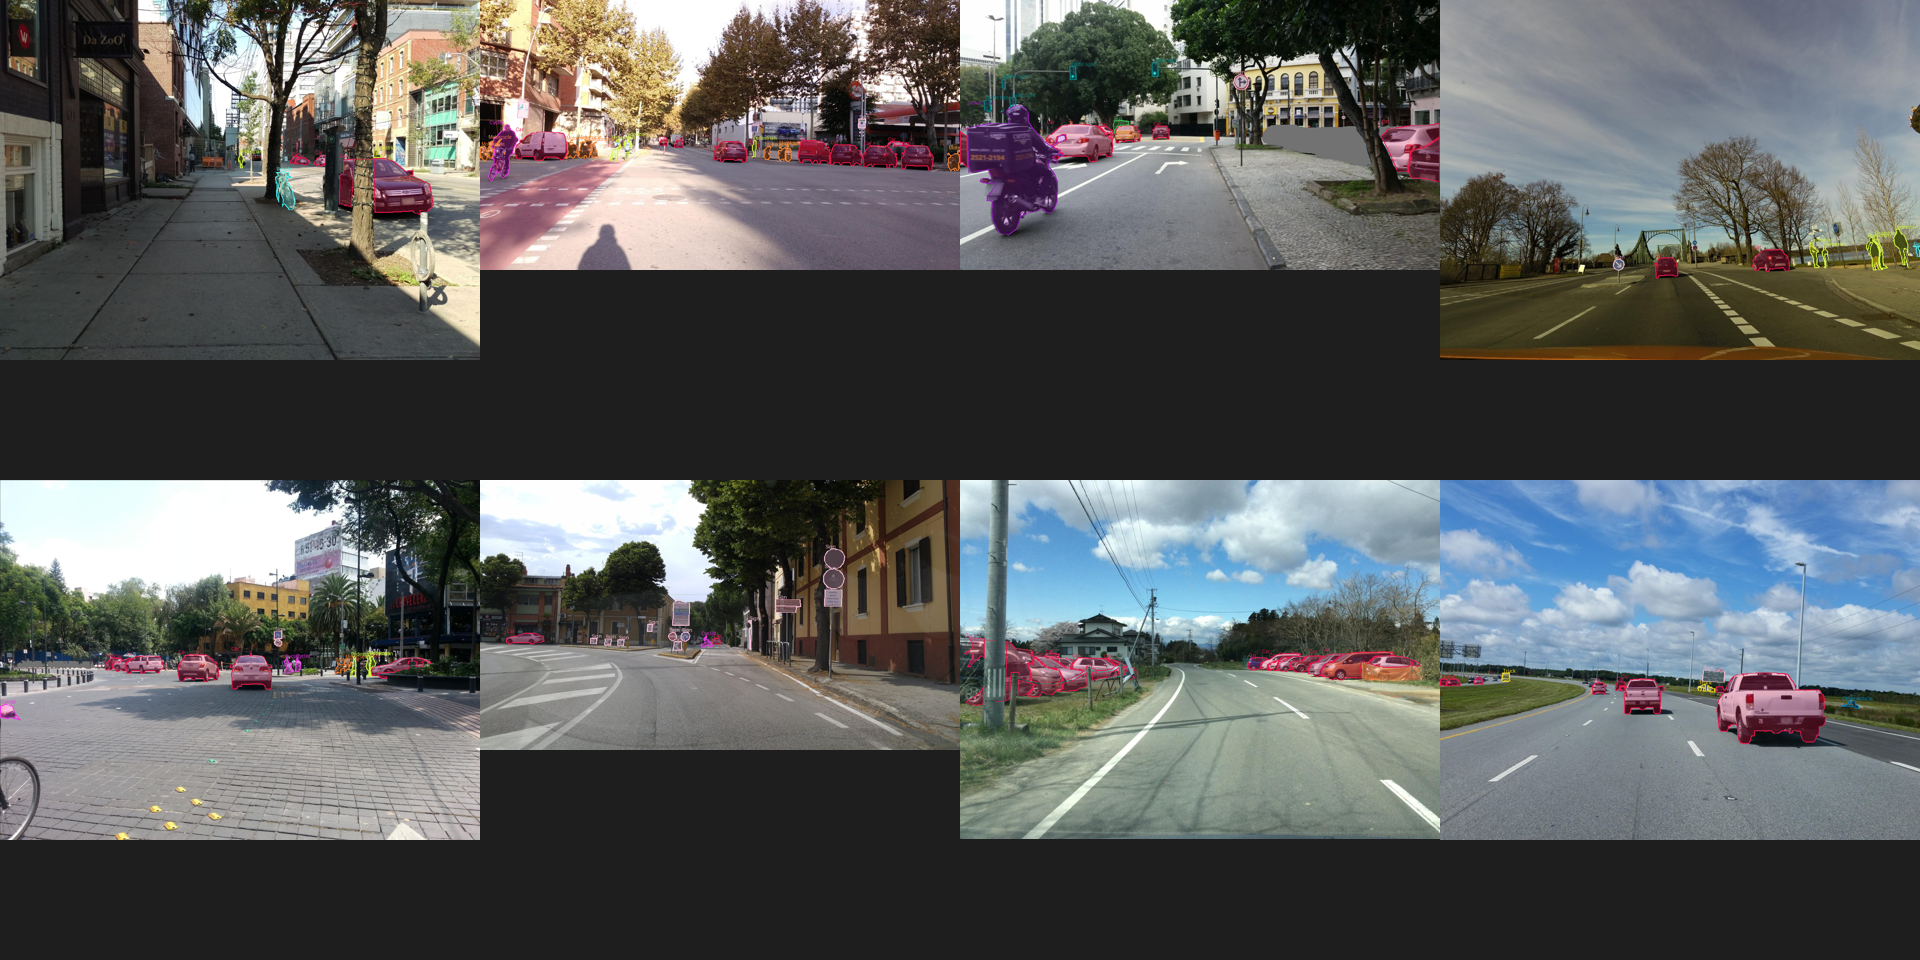

Mã băm dữ liệu (sha256): fb6eaedd6639d8039ecb2556b9490a12bd15d4f46b25d2e1ef402f1efd367b2e


In [27]:
REPORT = analyze_dataset(DATASET["out_dir"], CLASSES, MIN_GT_AREA_PX, IMGSZ, MIN_TRAIN_INSTANCES, MAX_IMBALANCE_RATIO, DUP_HAMMING_MAX, MIN_GT_PER_CLASS, MAX_DET)
print_report(REPORT, CLASSES, CLASS_DISPLAY_VI)
if REMOVE_LEAKAGE_FROM_TRAIN and (REPORT["duplicates"]["leak_exact"] or REPORT["duplicates"]["leak_near"]):
    remove_leakage_from_train(DATASET["out_dir"], REPORT)
    REPORT = analyze_dataset(DATASET["out_dir"], CLASSES, MIN_GT_AREA_PX, IMGSZ, MIN_TRAIN_INSTANCES, MAX_IMBALANCE_RATIO, DUP_HAMMING_MAX, MIN_GT_PER_CLASS, MAX_DET)
    print_report(REPORT, CLASSES, CLASS_DISPLAY_VI)
DATASET["counts"] = {s: {"images": v["images"], "instances": v["instances"]} for s, v in REPORT["splits"].items()}
PREVIEW = make_previews(DATASET["out_dir"], CLASSES, WORK / "report" / "preview_nhan.png", n=8, seed=SEED)
if PREVIEW:
    show_image(PREVIEW)
if not REPORT["ok"]:
    raise NotebookError("Dữ liệu có lỗi nặng, không thể huấn luyện:\n  - " + "\n  - ".join(REPORT["fatal"][:10]), "DATA")
DATASET["sha256"] = dataset_fingerprint(DATASET["out_dir"])
print(f"Mã băm dữ liệu (sha256): {DATASET['sha256']}")

## Bước 3. Huấn luyện (bạn được sửa tự do)
Mẫu huấn luyện đơn giản: fine-tune YOLO26-seg pretrained trên dữ liệu của đội, `imgsz=640`, `seed=SEED`, `deterministic=True`. Cuộc thi này chấm **dữ liệu** nhiều hơn tinh chỉnh,
nên mặc định không dùng thủ thuật nào. Bạn có thể bỏ dấu `#` ở dòng cuối của `TRAIN_ARGS` để thử augmentation, `freeze`, `cos_lr`... Chỉ cần giữ: **kiến trúc YOLO26n-seg, 11 lớp theo `data.yaml`**, và
cuối ô biến `BEST_WEIGHTS` trỏ tới tệp `.pt` bạn muốn nộp (dùng mã riêng thì tự gán `BEST_WEIGHTS = "đường_dẫn.pt"`).

Ô này in **ước lượng thời gian thô** (chưa đo trên Colab thật: tốc độ thật hiện ở epoch đầu tiên). Colab miễn phí ngắt kết nối khi để lâu, nên đặt `DRIVE_OUTPUT_DIR` để `best.pt` được lưu sang Drive.

In [28]:
from ultralytics import YOLO

# [VietSight] Step 3 (free to edit per the official notebook): same args + checkpoints every SAVE_PERIOD epochs written
# straight to Google Drive, and automatic resume from Drive last.pt after a Colab disconnect.
SAVE_PERIOD = 5
RUN_NAME = "vietsight_v1_e25"
TRAIN_ARGS = dict(
    data=DATASET["data_yaml"],
    imgsz=TRAIN_IMGSZ,      # giữ 640 (xem ô tham số)
    epochs=EPOCHS,
    batch=BATCH,
    seed=SEED,              # seed của đội
    deterministic=True,
    device=DEVICE,
    workers=WORKERS,
    patience=PATIENCE,
    cache=CACHE,
    plots=PLOTS,
    project=str(Path(DRIVE_OUTPUT_DIR) / "runs"),
    name=RUN_NAME,
    exist_ok=True,
    save_period=SAVE_PERIOD,
)
if TRAIN_ARGS["imgsz"] != IMGSZ:
    print(f"CẢNH BÁO: imgsz huấn luyện = {TRAIN_ARGS['imgsz']} khác {IMGSZ}. Hệ thống chấm chạy mô hình ở {IMGSZ}, điểm có thể thấp hơn.")
n_train, n_val = DATASET["counts"]["train"]["images"], DATASET["counts"]["val"]["images"]
print(f"Ước lượng thô (chưa đo): {n_train} ảnh train x {EPOCHS} epoch, cỡ {MODEL_SIZE} -> khoảng {fmt_minutes(estimate_train_minutes(n_train, n_val, EPOCHS, MODEL_SIZE))} trên T4.")

seed_everything(SEED)
RUN_DIR = Path(TRAIN_ARGS["project"]) / RUN_NAME
LAST = RUN_DIR / "weights" / "last.pt"
done_epochs = len((RUN_DIR / "results.csv").read_text().splitlines()) - 1 if (RUN_DIR / "results.csv").is_file() else 0
if LAST.is_file() and done_epochs < EPOCHS:
    print(f"RESUME từ {LAST} (đã xong {done_epochs}/{EPOCHS} epoch)")
    model = YOLO(str(LAST))
    try:
        model.train(resume=True)
    except (AssertionError, KeyError) as e:  # finished early (patience): optimizer stripped, nothing to resume
        print("Không resume được, dùng best.pt:", e)
        model = YOLO(str(RUN_DIR / "weights" / "best.pt"))
elif LAST.is_file():
    print(f"Run {RUN_NAME} đã train xong {done_epochs} epoch: dùng lại best.pt trên Drive")
    model = YOLO(str(RUN_DIR / "weights" / "best.pt"))
else:
    model = YOLO(MODEL_WEIGHTS)  # .pt: pretrained (tự tải)
    model.train(**TRAIN_ARGS)
BEST_WEIGHTS = RUN_DIR / "weights" / "best.pt"
trained_names = [model.names[i] for i in sorted(model.names)]
if trained_names != list(CLASSES):
    raise NotebookError(f"Tên lớp của mô hình {trained_names} khác danh sách lớp của cuộc thi {list(CLASSES)}. Hãy huấn luyện bằng data.yaml do Bước 1 tạo.", "TRAIN")
TRAIN_INFO = {"best_weights": str(BEST_WEIGHTS), "best_sha256": sha256_file(BEST_WEIGHTS), "best_tensors_sha256": weights_fingerprint(BEST_WEIGHTS),
              "train_args": {k: v for k, v in TRAIN_ARGS.items() if k != "project"}, "device": DEVICE, "gpu": GPU_NAME}
print("Trọng số tốt nhất:", BEST_WEIGHTS, "| checkpoint định kỳ:", sorted(p.name for p in (RUN_DIR / "weights").glob("*.pt")))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ước lượng thô (chưa đo): 1469 ảnh train x 25 epoch, cỡ n -> khoảng 29 phút trên T4.
New https://pypi.org/project/ultralytics/8.4.220 available 😃 Update with 'pip install -U ultralytics'
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/work/dataset/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, d

## Bước 4. Xuất ONNX, kiểm tra và đóng gói bài nộp (BẮT BUỘC, không sửa)
Ô dưới làm lần lượt:
1. Xuất `BEST_WEIGHTS` ra ONNX **chỉ với** `format="onnx", imgsz=640, batch=1, dynamic=False, simplify=True, opset=17` (không `nms`, không `half`: hai tùy chọn đó bị hệ thống chấm từ chối).
2. **Kiểm tra bằng đúng mã của hệ thống chấm** (kiến trúc YOLO26n-seg, 11 lớp, input/output, fp32, tên lớp, không phải model pretrained gốc, kích thước). Không đạt thì in đúng mã lỗi và thông báo
   tiếng Việt mà website sẽ hiện, và **không tạo zip**.
3. Đóng gói `submission.zip` chứa **đúng một tệp** `model.onnx` (tối đa 42 MiB), mở lại zip để kiểm tra lần nữa.

In [29]:
SUBMISSION = make_submission(BEST_WEIGHTS, WORK, YOLO, SELFCHECK)

Xuất ONNX với tham số cố định của cuộc thi: {'format': 'onnx', 'imgsz': 640, 'opset': 17, 'simplify': True, 'dynamic': False, 'batch': 1}
Ultralytics 8.4.214 🚀 Python-3.13.16 torch-2.14.1+cu130 CPU (Intel Xeon CPU @ 2.00GHz)
💡 ProTip: Export to OpenVINO format for best performance on Intel hardware. Learn more at https://docs.ultralytics.com/integrations/openvino
YOLO26n-seg summary (fused): 137 layers, 2,706,213 parameters, 0 gradients, 9.2 GFLOPs

PyTorch: starting from '/content/drive/MyDrive/VietSight/vietsight_v1_e25/runs/vietsight_v1_e25/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) ((1, 47, 8400), (1, 32, 160, 160)) (6.3 MB)

ONNX: starting export with onnx 1.23.2 opset 17...
ONNX: slimming with onnxslim 0.1.99...
ONNX: export success ✅ 2.5s, saved as '/content/drive/MyDrive/VietSight/vietsight_v1_e25/runs/vietsight_v1_e25/weights/best.onnx' (10.6 MB)

Export complete (3.1s)
Results saved to /content/drive/MyDrive/VietSight/vietsight_v1_e25/runs/vie

## Bước 5. Chạy thử như hệ thống chấm trên tập val
Ô dưới đưa `submission.zip` vừa tạo qua **chính mã chạy trong máy chấm** (letterbox, onnxruntime CPU, NMS, giải mã mask, RLE) trên ảnh val, rồi chấm bằng **bộ chấm của cuộc thi**
(mask mAP@[.5:.95], quy tắc bỏ qua vật nhỏ). Bạn thấy: điểm, AP50, **AP từng lớp** (lớp nào yếu), các nhầm lẫn thường gặp (ví dụ `Cyclist` bị nhầm thành `Pedestrian`) và ảnh
**nhãn (trái) so với dự đoán (phải)** của những ảnh sai nhiều nhất. Dùng nó để quyết định **thu thêm hoặc sửa nhãn ở đâu**, không phải để chỉnh tham số.
Lưu ý: đây là điểm trên val của đội, không phải điểm trên bộ test ẩn (và `best.pt` được chọn theo val nên hơi lạc quan).

Suy luận 262 ảnh val: 25954 dự đoán, p50 240 ms/ảnh (mô hình) + 125 ms (giải mã), 2 luồng CPU, kích thước mặt nạ RLE 2.49 MB.
mask mAP@[.5:.95] trên val = 0.2297  (điểm theo cách chấm của cuộc thi = 100 x mAP = 22.97)
AP50 = 0.3997 | AP75 = 0.2230 | 262 ảnh val | 25954 dự đoán | 32 nhãn nhỏ bị bỏ qua

id  lớp            tên tiếng Việt         AP[.5:.95]    AP50 số nhãn val
 0  Car            Ô tô con                    0.490   0.753        1160
 1  Bus            Xe buýt / xe khách          0.327   0.422          36
 2  Truck          Xe tải                      0.235   0.325          75
 3  Other vehicle  Phương tiện khác            0.075   0.090          35  <-- yếu
 4  Motorcycle     Xe máy (không người)        0.085   0.197          69  <-- yếu
 5  Motorcyclist   Xe máy (có người)           0.303   0.510          49
 6  Bicycle        Xe đạp (không người)        0.061   0.174          71  <-- yếu
 7  Cyclist        Xe đạp (có người)           0.207   0.393          59
 8  Pedestria

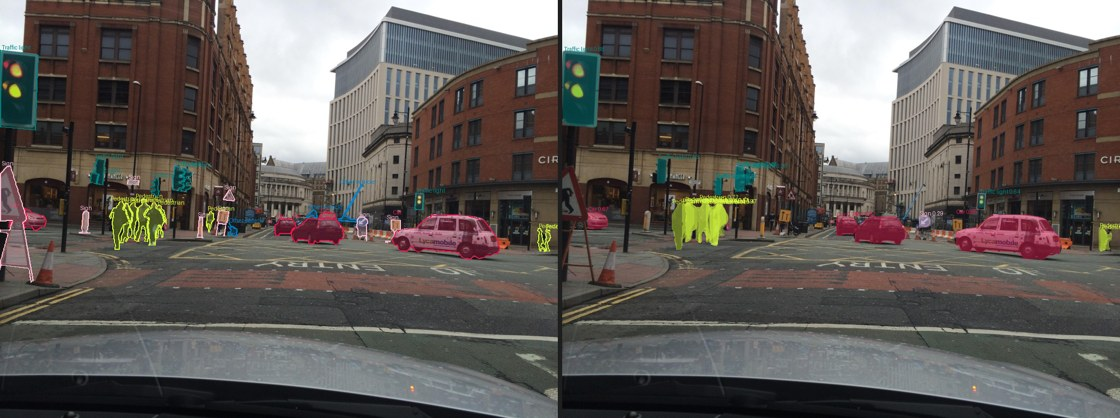

Ảnh: /content/work/report/loi/loi_02_00224_mapillary_vistas__Ik5C23HH5aeFdc311WYdeg__2f1ffc0d.jpg


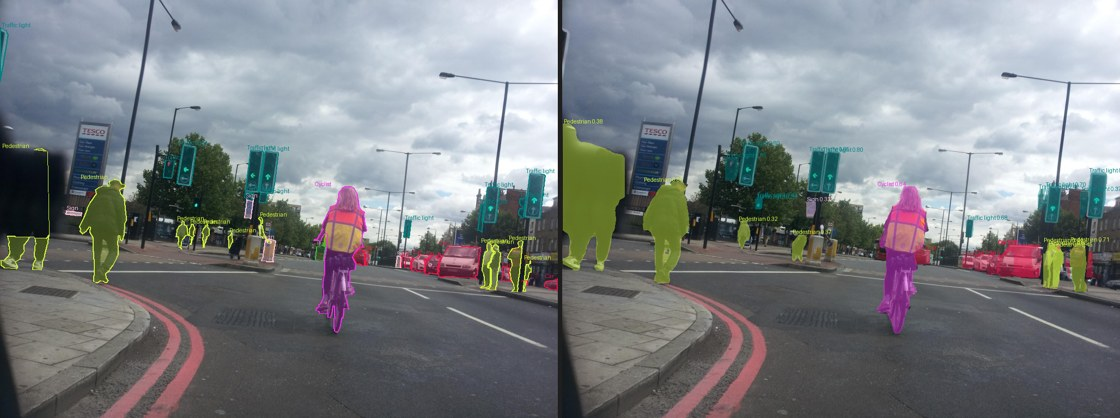

Ảnh: /content/work/report/loi/loi_03_00102_mapillary_vistas__7zKUntDt3zAZRDMsSJw9jw__433de7d5.jpg


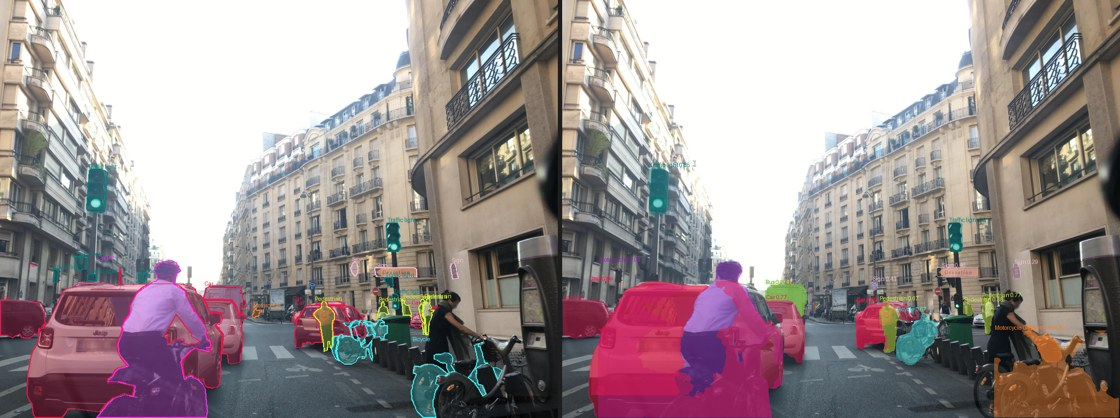

Ảnh: /content/work/report/loi/loi_04_00188_mapillary_vistas__Fp31dNDlqMC4LcgG5X_NqQ__28bdf7bd.jpg


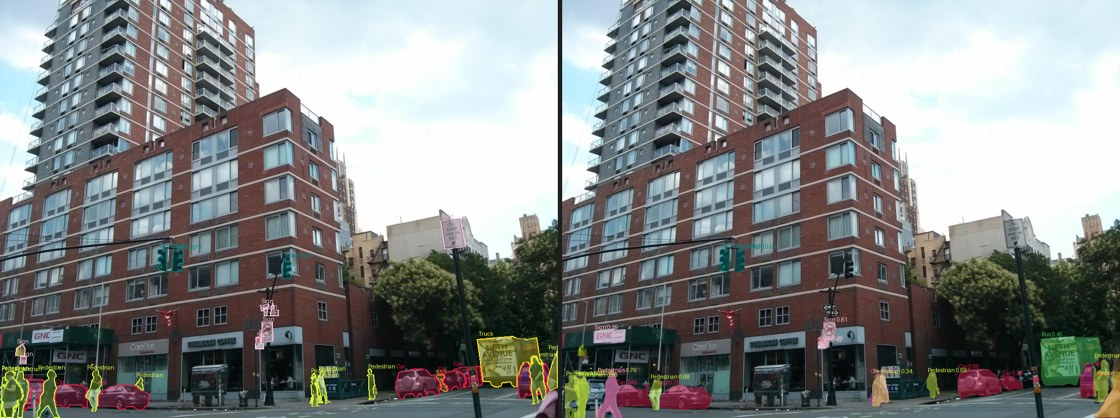

Ảnh: /content/work/report/loi/loi_05_00260_mapillary_vistas__jGzo9blhVkb-GgmTnYzHg__e79c817b.jpg


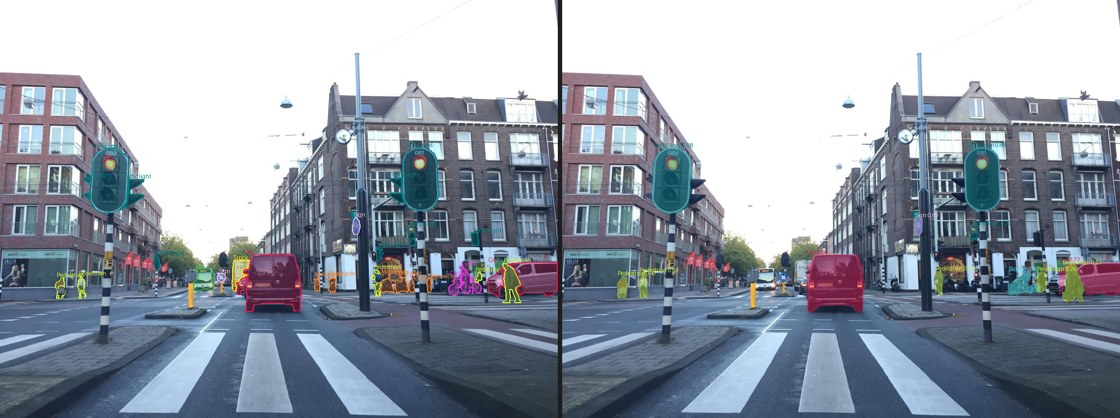

Ảnh: /content/work/report/loi/loi_06_00083_mapillary_vistas__6a-fGujfGx5UVyFt_pD3Kw__fee857bd.jpg


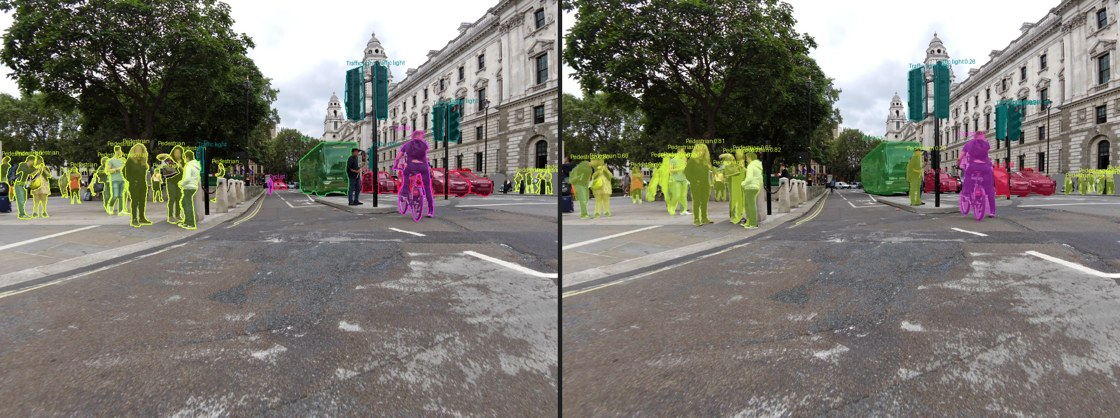

In [30]:
VAL_IMAGES = sample_stems(WORK / "dataset" / "images" / "val", SELFCHECK_MAX_IMAGES, SEED)
VAL_LABELS = WORK / "dataset" / "labels" / "val"
PRED_PATH, INFER_SUMMARY = run_platform_inference(SUBMISSION["zip"], VAL_IMAGES, WORK, SELFCHECK)
print(f"Suy luận {INFER_SUMMARY['n_images']} ảnh val: {INFER_SUMMARY['n_instances']} dự đoán, p50 {INFER_SUMMARY['latency_ms_p50']:.0f} ms/ảnh (mô hình) + {INFER_SUMMARY['decode_ms_p50']:.0f} ms (giải mã), "
      f"{INFER_SUMMARY['threads']} luồng CPU, kích thước mặt nạ RLE {INFER_SUMMARY['output_bytes'] / 1e6:.2f} MB.")
VAL_RESULT = print_score(score_predictions(PRED_PATH, VAL_LABELS, VAL_IMAGES, SELFCHECK), CLASSES, CLASS_DISPLAY_VI)
ERROR_ROWS, CONFUSION = analyze_errors(PRED_PATH, VAL_LABELS, SELFCHECK, CONF_SHOW)
print_confusion(CONFUSION, CLASSES)
ERROR_IMAGES = render_error_images(ERROR_ROWS, PRED_PATH, WORK / "dataset" / "images" / "val", VAL_LABELS, CLASSES, SELFCHECK, WORK / "report" / "loi", N_ERROR_IMAGES, CONF_SHOW)
print(f"{len(ERROR_IMAGES)} ảnh lỗi nhất (trái: nhãn, phải: dự đoán), lưu ở {WORK / 'report' / 'loi'}")
for p in ERROR_IMAGES:
    show_image(p)

## Bước 6. Bản kê tái lập và tải bài nộp
Ghi `run_report.json`: seed, mã băm dữ liệu, số đối tượng từng lớp, tham số huấn luyện và xuất, phiên bản thư viện, dấu vân tay mô hình, điểm val. Ban tổ chức dùng tệp này để chạy lại và đối chiếu.
Sau đó tải `submission.zip` và `run_report.json` về máy; **nộp tệp `submission.zip`** lên website (mỗi đội có 20 lượt nộp, nên hãy xem điểm val và ảnh lỗi trước khi nộp).

In [31]:
EVAL_SUMMARY = {"map50_95": VAL_RESULT["map50_95"], "score_x100": VAL_RESULT["score"], "map50": VAL_RESULT["map50"], "per_class_ap": VAL_RESULT["per_class_ap"],
                "n_images": VAL_RESULT["n_images"], "latency_ms_p50": INFER_SUMMARY["latency_ms_p50"], "note": "tính trên val của đội bằng bộ chấm nhúng, không phải điểm trên bộ test ẩn"}
MANIFEST = build_manifest(TEAM_ID, SEED, PARAMS, DATASET, REPORT, TRAIN_INFO, SUBMISSION, EVAL_SUMMARY, ENV, CLASSES)
MANIFEST_PATH = write_manifest(MANIFEST, SUBMISSION["zip"].parent / "run_report.json")
print(f"Bản kê tái lập: {MANIFEST_PATH}")
if DRIVE_OUTPUT_DIR:
    for src in (SUBMISSION["zip"], MANIFEST_PATH):
        shutil.copyfile(src, Path(DRIVE_OUTPUT_DIR) / src.name)
    print(f"Đã sao chép submission.zip và run_report.json sang {DRIVE_OUTPUT_DIR}")
offer_download([SUBMISSION["zip"], MANIFEST_PATH])

Bản kê tái lập: /content/work/submission/run_report.json
Đã sao chép submission.zip và run_report.json sang /content/drive/MyDrive/VietSight/vietsight_v1_e25
Tệp: /content/work/submission/submission.zip
Tệp: /content/work/submission/run_report.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Sau khi nộp: cải thiện dữ liệu, không phải tham số
- **Lớp yếu ở Bước 5** thường là lớp ít ví dụ ở Bước 2: thu thêm ảnh có lớp đó (đặc biệt cảnh khó: đêm, mưa, ngược sáng, đông đúc), không chỉ thêm cảnh dễ.
- **Nhầm lớp** (`Motorcycle` với `Motorcyclist`, `Bicycle` với `Cyclist`, `Truck` với `Other vehicle`): đọc lại hướng dẫn gán nhãn, rà soát nhãn của lớp đó theo cặp hai người, thống nhất quy ước.
- **Bỏ sót nhiều**: có thể thiếu nhãn (vật thể có trong ảnh nhưng chưa gán) hoặc vật quá nhỏ. Mở ảnh lỗi và đối chiếu bên trái (nhãn) với ảnh gốc.
- **Mask lệch biên**: mAP@[.5:.95] chấm rất khắt khe về độ khớp mask; vẽ lại polygon sát hơn (SAM hỗ trợ trong CVAT/Label Studio) thường tăng điểm hơn thêm ảnh.
- **Active learning:** dùng model hiện tại dự đoán trên ảnh chưa gán, ưu tiên gán những ảnh model kém tự tin; gán nháp bằng model rồi **người sửa lại**.
- Mỗi lần thêm dữ liệu, chạy lại từ Bước 1 **với cùng `TEAM_ID`**, so sánh điểm val và `run_report.json` giữa các vòng để biết thay đổi nào có ích.